# Legacy full pipeline · Standalone 完整项目

[English](../../legacy_full_pipeline.ipynb) · 简体中文

本 notebook 按顺序整合当前全部 11 本拆分版 notebook：数据准备与审计、EDA、HLR 基线与特征扩展、随机森林、LightGBM、N-HLR、统一比较、非线性消融、MAE/RMSE 误差分析，以及 RF–LightGBM 相似性诊断。

数据清洗、特征工程、全部模型的定义、选参、训练、评价和画图代码均已展开为本文件中的普通代码单元。运行时无需 `experiment_pipeline.py`、`pipeline_cells.py`、`pipeline_steps/` 或其他 notebook。

**独立运行：**将本文件放入一个文件夹，准备 Python 3.11 和下方依赖，把原始文件放在 `data/raw/settles.acl16.learning_traces.13m.csv.gz`，执行 **Restart Kernel and Run All Cells**。清洗数据、特征缓存、审计报告和图会自动生成；十二个主模型在本 notebook 中从头训练，不需要预先训练的模型文件。08 节统一使用 **-lex** 输入与三个配对种子（42、43、44），09 节误差分解比较 **HLR 与 RF-p**。

非线性消融支持逐模型缓存续跑；没有缓存时会完成六次训练。首次运行需要完整数据审计与模型训练，耗时和内存需求与完整拆分版实验相同。

**安装依赖：**

```text
numpy==2.4.6
pandas==3.1.1
scipy==1.17.1
scikit-learn==1.9.1
lightgbm==4.7.0
joblib==1.6.0
psutil==7.2.2
matplotlib==3.11.2
ipython==9.18.1
ipykernel==7.4.0
jupyterlab>=4,<5
```

将上述包安装到所选 kernel 的 Python 环境即可。

**内容对应：**按以下拆分版 notebook 的顺序保留所有实验、图表与说明；主模型的计算代码从其共用实现逐字展开。以下文件只说明来源，运行时无需携带。

- `00_data_preparation.ipynb`
- `01_eda.ipynb`
- `02_hlr_baselines.ipynb`
- `03_hlr_experiments.ipynb`
- `04_random_forest.ipynb`
- `05_lightgbm.ipynb`
- `06_neural_hlr.ipynb`
- `07_model_comparison.ipynb`
- `08_nonlinearity_ablation.ipynb`
- `09_mae_rmse_analysis.ipynb`
- `10_rf_lightgbm_similarity.ipynb`


# 数据准备与审计

[English](../../00_data_preparation.ipynb) · 简体中文

从原始 gzip 构建去重数据、固定切分及特征缓存，并运行数据审计。


In [1]:
# Locate shared data and modules when running from a subdirectory.
from pathlib import Path
import os
import sys

_notebook_start = Path.cwd().resolve()
_notebook_parents = (_notebook_start, *_notebook_start.parents)
_project_root = next(
    (p for p in _notebook_parents
     if (p / "data/raw/settles.acl16.learning_traces.13m.csv.gz").is_file()),
    None,
)
if _project_root is None:
    _project_root = next(
        (p for p in _notebook_parents if (p / "experiment_pipeline.py").is_file()),
        _notebook_start,
    )
os.chdir(_project_root)
if str(_project_root) not in sys.path:
    sys.path.insert(0, str(_project_root))

from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

filename = "settles.acl16.learning_traces.13m.csv.gz"
candidates = [Path("data/raw") / filename, Path("../data/raw") / filename]
data_path = next((p.resolve() for p in candidates if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError(f"找不到 {filename}；请把数据放到项目的 data/raw/ 下。")

preview = pd.read_csv(data_path, compression="gzip", nrows=5)
print("原始文件：", data_path)
print("前 5 行：")
display(preview)


原始文件： D:\fujing123\Projects\Data-Analytic\HLR\data\raw\settles.acl16.learning_traces.13m.csv.gz
前 5 行：


,p_recall,timestamp,delta,user_id,learning_language,ui_language,lexeme_id,lexeme_string,history_seen,history_correct,session_seen,session_correct
0,1.0,1362076081,27649635,u:FO,de,en,76390c1350a8dac31186187e2fe1e178,lernt/lernen<vblex><pri><p3><sg>,6,4,2,2
1,0.5,1362076081,27649635,u:FO,de,en,7dfd7086f3671685e2cf1c1da72796d7,die/die<det><def><f><sg><nom>,4,4,2,1
2,1.0,1362076081,27649635,u:FO,de,en,35a54c25a2cda8127343f6a82e6f6b7d,mann/mann<n><m><sg><nom>,5,4,1,1
3,0.5,1362076081,27649635,u:FO,de,en,0cf63ffe3dda158bc3dbd55682b355ae,frau/frau<n><f><sg><nom>,6,5,2,1
4,1.0,1362076081,27649635,u:FO,de,en,84920990d78044db53c1b012f5bf9ab5,das/das<det><def><nt><sg><nom>,4,4,1,1


In [2]:
import csv
import gzip
import hashlib
import os
import tempfile
from contextlib import ExitStack
import json

CP2_FIELDS = (
    "p_recall", "timestamp", "delta", "user_id", "learning_language",
    "ui_language", "lexeme_id", "lexeme_string", "history_seen",
    "history_correct", "session_seen", "session_correct",
)
raw_candidates = [Path("data/raw") / filename, Path("../data/raw") / filename]
raw_data_path = next((path.resolve() for path in raw_candidates if path.is_file()), None)
if raw_data_path is None:
    raise FileNotFoundError(f"Missing raw data: {filename}")
project_data_dir = raw_data_path.parent.parent
processed_dir = project_data_dir / "processed"
interim_dir = project_data_dir / "interim"
reports_dir = project_data_dir.parent / "reports"
for directory in (processed_dir, interim_dir, reports_dir):
    directory.mkdir(parents=True, exist_ok=True)
cleaned_data_path = processed_dir / "settles.acl16.learning_traces.13m.dedup_v1.csv.gz"
clean_manifest_path = processed_dir / "settles.acl16.learning_traces.13m.dedup_v1.json"
duplicate_report_path = reports_dir / "exact_duplicates_v1.json"

def cp2_file_sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def cp2_raw_rows(path):
    with gzip.open(path, "rt", encoding="utf-8", newline="") as stream:
        reader = csv.reader(stream)
        if tuple(next(reader)) != CP2_FIELDS:
            raise ValueError("Unexpected raw CSV header")
        yield from enumerate(reader)

def cp2_row_digest(row):
    return hashlib.blake2b(repr(tuple(row)).encode("utf-8"), digest_size=16).digest()

def cp2_find_exact_duplicates(path):
    with tempfile.TemporaryDirectory(prefix="cp2_dedup_", dir=interim_dir) as temp:
        bucket_paths = [Path(temp) / f"{i:02x}.bin" for i in range(256)]
        with ExitStack() as stack:
            buckets = [
                stack.enter_context(bucket.open("wb")) for bucket in bucket_paths
            ]
            raw_rows = 0
            for index, row in cp2_raw_rows(path):
                digest = cp2_row_digest(row)
                buckets[digest[0]].write(digest)
                raw_rows += 1
        candidates = set()
        for bucket_path in bucket_paths:
            seen = set()
            with bucket_path.open("rb") as stream:
                for digest in iter(lambda: stream.read(16), b""):
                    if digest in seen:
                        candidates.add(digest)
                    else:
                        seen.add(digest)
    first_rows = {}
    duplicate_indices = []
    examples = []
    if candidates:
        for index, row in cp2_raw_rows(path):
            digest = cp2_row_digest(row)
            if digest not in candidates:
                continue
            complete_row = tuple(row)
            seen = first_rows.setdefault(digest, [])
            first = next(
                (prior_index for previous, prior_index in seen
                 if previous == complete_row),
                None,
            )
            if first is None:
                seen.append((complete_row, index))
            else:
                duplicate_indices.append(index)
                if len(examples) < 10:
                    examples.append({
                        "first_row_index": first,
                        "duplicate_row_index": index,
                    })
    return raw_rows, duplicate_indices, examples

raw_stat = raw_data_path.stat()
clean_manifest = (
    json.loads(clean_manifest_path.read_text(encoding="utf-8"))
    if clean_manifest_path.is_file() else {}
)
clean_valid = (
    cleaned_data_path.is_file()
    and duplicate_report_path.is_file()
    and clean_manifest.get("version") == 1
    and clean_manifest.get("raw_file") == raw_data_path.name
    and clean_manifest.get("raw_size_bytes") == raw_stat.st_size
    and clean_manifest.get("raw_mtime_ns") == raw_stat.st_mtime_ns
    and clean_manifest.get("clean_size_bytes") == cleaned_data_path.stat().st_size
    and clean_manifest.get("clean_mtime_ns") == cleaned_data_path.stat().st_mtime_ns
    and clean_manifest.get("raw_rows", 0) > 0
    and clean_manifest.get("clean_rows", 0) > 0
)
if not clean_valid:
    raw_rows, duplicate_indices, examples = cp2_find_exact_duplicates(raw_data_path)
    duplicate_set = set(duplicate_indices)
    partial_path = cleaned_data_path.with_suffix(".partial")
    kept = 0
    with gzip.open(partial_path, "wt", encoding="utf-8", newline="",
                   compresslevel=6) as output:
        writer = csv.writer(output)
        writer.writerow(CP2_FIELDS)
        for index, row in cp2_raw_rows(raw_data_path):
            if index not in duplicate_set:
                writer.writerow(row)
                kept += 1
    assert kept == raw_rows - len(duplicate_indices)
    os.replace(partial_path, cleaned_data_path)
    clean_manifest = {
        "version": 1,
        "rule": "exact full CSV row; keep first raw occurrence",
        "raw_file": raw_data_path.name,
        "raw_size_bytes": raw_stat.st_size,
        "raw_mtime_ns": raw_stat.st_mtime_ns,
        "raw_sha256": cp2_file_sha256(raw_data_path),
        "raw_rows": raw_rows,
        "duplicate_rows_after_first": len(duplicate_indices),
        "duplicate_raw_row_indices": duplicate_indices,
        "clean_rows": kept,
        "clean_size_bytes": cleaned_data_path.stat().st_size,
        "clean_mtime_ns": cleaned_data_path.stat().st_mtime_ns,
        "clean_sha256": cp2_file_sha256(cleaned_data_path),
    }
    clean_manifest_path.write_text(
        json.dumps(clean_manifest, ensure_ascii=False, indent=2) + "\n",
        encoding="utf-8",
    )
    duplicate_report_path.write_text(
        json.dumps({
            "raw_sha256": clean_manifest["raw_sha256"],
            "raw_rows": raw_rows,
            "duplicate_rows_after_first": len(duplicate_indices),
            "duplicate_examples": examples,
            "policy": clean_manifest["rule"],
        }, ensure_ascii=False, indent=2) + "\n",
        encoding="utf-8",
    )
    print("Completed full raw-data exact-duplicate check and cleaning.")
else:
    print("Reused saved duplicate check and cleaned dataset.")

data_path = cleaned_data_path
assert clean_manifest["clean_rows"] == (
    clean_manifest["raw_rows"] - clean_manifest["duplicate_rows_after_first"]
)
display(pd.DataFrame([{
    "raw_rows": clean_manifest["raw_rows"],
    "exact_duplicates_removed": clean_manifest["duplicate_rows_after_first"],
    "clean_rows": clean_manifest["clean_rows"],
}]))
print("Model and EDA input:", data_path)


Reused saved duplicate check and cleaned dataset.


,raw_rows,exact_duplicates_removed,clean_rows
0,12854226,81,12854145


Model and EDA input: D:\fujing123\Projects\Data-Analytic\HLR\data\processed\settles.acl16.learning_traces.13m.dedup_v1.csv.gz


In [3]:
import hashlib
import json
import math
import os
import time

# 计数与缓存校验都直接读原始 gzip；不依赖旧目录中的报告、词表或模型文件。
source_sha256 = hashlib.sha256()
with data_path.open("rb") as source:
    for block in iter(lambda: source.read(8 * 1024 * 1024), b""):
        source_sha256.update(block)
source_sha256 = source_sha256.hexdigest()

n_rows = sum(len(chunk) for chunk in pd.read_csv(
    data_path, compression="gzip", usecols=["p_recall"], chunksize=500_000
))
train_end = int(0.72 * n_rows)
test_start = int(0.90 * n_rows)
splits = {
    "Train": (0, train_end),
    "Validation": (train_end, test_start),
    "Test": (test_start, n_rows),
}
display(pd.DataFrame([
    {"split": name, "start": start, "stop_exclusive": stop, "rows": stop - start}
    for name, (start, stop) in splits.items()
]))
print("切分依据：原始 CSV 文件行顺序；随机打乱仅发生在 Train 内的训练阶段。")

MIN_H, MAX_H = 15.0 / 1440.0, 274.0
MIN_P, MAX_P = 0.0001, 0.9999
ALPHA, L2, LEARNING_RATE, SEED, EPOCHS = 0.01, 0.1, 0.001, 42, 1
LOG_MIN_H, LOG_MAX_H = math.log2(MIN_H), math.log2(MAX_H)
BASE_FEATURES = [
    "sqrt(1+history_correct)",
    "sqrt(1+history_seen-history_correct)",
    "bias",
]
RECORD_DTYPE = np.dtype([
    ("x_correct", "<f8"), ("x_wrong", "<f8"), ("lexeme_column", "<i4"),
    ("p_target", "<f8"), ("delta_days", "<f8"), ("h_observed", "<f8"),
])

cache_dir = data_path.parent.parent / "interim"
cache_dir.mkdir(parents=True, exist_ok=True)
cache_path = cache_dir / "takeaway_hlr_features_v1.dat"
manifest_path = cache_dir / "takeaway_hlr_features_v1.json"
cache_identity = {
    "version": 1,
    "source_sha256": source_sha256,
    "n_rows": n_rows,
    "train_end": train_end,
    "dtype": repr(RECORD_DTYPE.descr),
}
manifest = json.loads(manifest_path.read_text(encoding="utf-8")) if manifest_path.is_file() else {}
cache_valid = (
    cache_path.is_file()
    and all(manifest.get(key) == value for key, value in cache_identity.items())
    and cache_path.stat().st_size == n_rows * RECORD_DTYPE.itemsize
)

if not cache_valid:
    vocabulary = {}  # 只能从 Train 学到词项列号；从第 3 列开始。
    unseen_validation = unseen_test = 0
    partial_path = cache_path.with_suffix(".partial")
    records_out = np.memmap(partial_path, dtype=RECORD_DTYPE, mode="w+", shape=(n_rows,))
    written = 0
    needed = [
        "p_recall", "delta", "history_seen", "history_correct",
        "learning_language", "lexeme_string",
    ]
    for chunk in pd.read_csv(data_path, compression="gzip", usecols=needed,
                             chunksize=200_000):
        start, stop = written, written + len(chunk)
        if stop > n_rows:
            raise ValueError("实际行数超过已计数的行数")
        keys = chunk["learning_language"].astype(str).str.cat(
            chunk["lexeme_string"].astype(str), sep=":"
        )
        train_count = max(0, min(stop, train_end) - start)
        for key in pd.unique(keys.iloc[:train_count]):
            vocabulary.setdefault(key, 3 + len(vocabulary))
        columns = keys.map(vocabulary).fillna(-1).to_numpy(dtype=np.int32)

        correct = chunk["history_correct"].to_numpy(dtype=np.float64)
        wrong = chunk["history_seen"].to_numpy(dtype=np.float64) - correct
        if np.any(correct < 0) or np.any(wrong < 0):
            raise ValueError("发现 history_seen < history_correct 或负数")
        p = np.clip(chunk["p_recall"].to_numpy(dtype=np.float64), MIN_P, MAX_P)
        days = chunk["delta"].to_numpy(dtype=np.float64) / 86_400.0
        h = np.clip(-days / np.log2(p), MIN_H, MAX_H)
        if not (np.isfinite(p).all() and np.isfinite(h).all()):
            raise ValueError("目标值包含非有限数")

        records_out["x_correct"][start:stop] = np.sqrt(1.0 + correct)
        records_out["x_wrong"][start:stop] = np.sqrt(1.0 + wrong)
        records_out["lexeme_column"][start:stop] = columns
        records_out["p_target"][start:stop] = p
        records_out["delta_days"][start:stop] = days
        records_out["h_observed"][start:stop] = h

        val_left, val_right = max(start, train_end), min(stop, test_start)
        if val_left < val_right:
            unseen_validation += int(np.sum(columns[val_left-start:val_right-start] < 0))
        test_left = max(start, test_start)
        if test_left < stop:
            unseen_test += int(np.sum(columns[test_left-start:] < 0))
        written = stop

    if written != n_rows:
        raise ValueError(f"缓存行数 {written:,} 与原始文件 {n_rows:,} 不一致")
    records_out.flush()
    del records_out
    os.replace(partial_path, cache_path)
    manifest = {
        **cache_identity,
        "vocab_size": len(vocabulary),
        "unseen_validation": unseen_validation,
        "unseen_test": unseen_test,
    }
    manifest_path.write_text(json.dumps(manifest, ensure_ascii=False, indent=2),
                             encoding="utf-8")
    print("已建立新目录所需的特征缓存。")
else:
    print("已复用与当前原始数据、切分一致的特征缓存。")

records = np.memmap(cache_path, dtype=RECORD_DTYPE, mode="r", shape=(n_rows,))
vocab_size = int(manifest["vocab_size"])
print(f"缓存：{cache_path}；{cache_path.stat().st_size / 2**20:.1f} MiB")
print("基础特征：", BASE_FEATURES)
print(f"Train 词项数：{vocab_size:,}；Validation 未见词项行数："
      f"{manifest['unseen_validation']:,}；Test 未见词项行数：{manifest['unseen_test']:,}")

def train_hlr(dimension):
    """沿用原论文风格：一次打乱 Train，逐行、逐活跃特征更新。"""
    weights = [0.0] * dimension
    feature_counts = [0] * dimension
    order = np.arange(train_end, dtype=np.int32)
    np.random.default_rng(SEED).shuffle(order)
    started = time.perf_counter()
    x0_all, x1_all = records["x_correct"], records["x_wrong"]
    lex_all, p_all = records["lexeme_column"], records["p_target"]
    days_all, h_all = records["delta_days"], records["h_observed"]
    for step, row_index in enumerate(order, start=1):
        x0, x1 = float(x0_all[row_index]), float(x1_all[row_index])
        column = int(lex_all[row_index])
        p, days, h_true = float(p_all[row_index]), float(days_all[row_index]), float(h_all[row_index])
        score = weights[0] * x0 + weights[1] * x1 + weights[2]
        if dimension > 3 and 3 <= column < dimension:
            score += weights[column]
        h_pred = math.exp2(min(max(score, LOG_MIN_H), LOG_MAX_H))
        p_pred = min(max(math.exp2(-days / h_pred), MIN_P), MAX_P)
        grad_p = 2.0 * (p_pred - p) * math.log(2.0)**2 * p_pred * (days / h_pred)
        grad_h = 2.0 * (h_pred - h_true) * math.log(2.0) * h_pred
        active = ((0, x0), (1, x1), (2, 1.0))
        if dimension > 3 and 3 <= column < dimension:
            active += ((column, 1.0),)
        for k, value in active:
            rate = LEARNING_RATE / ((1.0 + p) * math.sqrt(1 + feature_counts[k]))
            weights[k] -= rate * grad_p * value
            weights[k] -= rate * ALPHA * grad_h * value
            weights[k] -= rate * L2 * weights[k]
            feature_counts[k] += 1
        if step % 1_000_000 == 0 or step == train_end:
            print(f"  {step:,}/{train_end:,} 行；耗时 {time.perf_counter()-started:.1f} 秒")
    return np.asarray(weights, dtype=np.float64)

def auc_fixed(labels, scores):
    labels = np.asarray(labels, dtype=np.int8)
    n_pos = int(labels.sum())
    n_neg = len(labels) - n_pos
    if not n_pos or not n_neg:
        return np.nan
    ranks = pd.Series(scores).rank(method="average").to_numpy(dtype=np.float64)
    rank_sum = float(ranks[labels == 1].sum())
    return (rank_sum - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)

def spearman_with_ties(observed, predicted):
    x_rank = pd.Series(observed).rank(method="average").to_numpy(dtype=np.float64)
    y_rank = pd.Series(predicted).rank(method="average").to_numpy(dtype=np.float64)
    if np.std(x_rank) == 0 or np.std(y_rank) == 0:
        return np.nan
    return float(np.corrcoef(x_rank, y_rank)[0, 1])

def evaluate_hlr(weights, split_name, batch_size=200_000):
    start, stop = splits[split_name]
    count = stop - start
    p_true = records["p_target"][start:stop]
    h_true = records["h_observed"][start:stop]
    p_pred = np.empty(count, dtype=np.float64)
    h_pred = np.empty(count, dtype=np.float64)
    for left in range(start, stop, batch_size):
        right = min(left + batch_size, stop)
        batch = records[left:right]
        score = (weights[0] * batch["x_correct"]
                 + weights[1] * batch["x_wrong"] + weights[2])
        if len(weights) > 3:
            columns = batch["lexeme_column"]
            known = (columns >= 3) & (columns < len(weights))
            score[known] += weights[columns[known]]
        h_batch = np.exp2(np.clip(score, LOG_MIN_H, LOG_MAX_H))
        p_batch = np.clip(np.exp2(-batch["delta_days"] / h_batch), MIN_P, MAX_P)
        h_pred[left-start:right-start] = h_batch
        p_pred[left-start:right-start] = p_batch

    p_error = p_pred - p_true
    mae_p = float(np.abs(p_error).mean())
    p_sq = float(np.dot(p_error, p_error))
    del p_error
    h_error = h_pred - h_true
    h_sq = float(np.dot(h_error, h_error))
    del h_error
    loss_sum = p_sq + ALPHA * h_sq + L2 * float(np.dot(weights, weights))
    auc = auc_fixed(np.rint(p_true), p_pred)
    spearman = spearman_with_ties(h_true, h_pred)
    return {
        "split": split_name, "rows": count, "loss_total": loss_sum,
        "loss_per_row": loss_sum / count, "MAE(p)": mae_p,
        "AUC": auc, "Spearman(h)": spearman,
    }

def show_model_result(name, weights):
    print(f"{name}；输入特征维度：{len(weights):,}")
    print("超参数：", {"alpha": ALPHA, "L2": L2, "learning_rate": LEARNING_RATE,
                       "epochs": EPOCHS, "seed": SEED})
    print("Loss = Σ[(p−p̂)² + 0.01(h−ĥ)²] + 0.1||θ||²")
    print("训练已完成；下表分别是完整 Train、Validation 和 Test 的效果：")
    result = pd.DataFrame([evaluate_hlr(weights, name) for name in splits])
    display(result.round({"loss_total": 3, "loss_per_row": 5,
                          "MAE(p)": 6, "AUC": 6, "Spearman(h)": 6}))
    return result


,split,start,stop_exclusive,rows
0,Train,0,9254984,9254984
1,Validation,9254984,11568730,2313746
2,Test,11568730,12854145,1285415


切分依据：原始 CSV 文件行顺序；随机打乱仅发生在 Train 内的训练阶段。
已复用与当前原始数据、切分一致的特征缓存。
缓存：D:\fujing123\Projects\Data-Analytic\HLR\data\interim\takeaway_hlr_features_v1.dat；539.4 MiB
基础特征： ['sqrt(1+history_correct)', 'sqrt(1+history_seen-history_correct)', 'bias']
Train 词项数：18,353；Validation 未见词项行数：1,150；Test 未见词项行数：560


In [4]:
import csv
import gzip

CATEGORY_DTYPE = np.dtype([
    ("user_index", "<i4"),
    ("learning_index", "i1"),
    ("ui_index", "i1"),
])
category_path = cache_dir / "takeaway_hlr_categories_v1.dat"
category_manifest_path = cache_dir / "takeaway_hlr_categories_v1.json"
category_identity = {
    "version": 1,
    "source_sha256": source_sha256,
    "n_rows": n_rows,
    "train_end": train_end,
    "dtype": repr(CATEGORY_DTYPE.descr),
}
category_manifest = (
    json.loads(category_manifest_path.read_text(encoding="utf-8"))
    if category_manifest_path.is_file() else {}
)
category_valid = (
    category_path.is_file()
    and category_path.stat().st_size == n_rows * CATEGORY_DTYPE.itemsize
    and all(category_manifest.get(k) == v for k, v in category_identity.items())
    and category_manifest.get("user_count", 0) > 0
    and len(category_manifest.get("learning_values", [])) > 0
    and len(category_manifest.get("ui_values", [])) > 0
)
if not category_valid:
    category_vocab = {
        "user_id": {},
        "learning_language": {},
        "ui_language": {},
    }
    partial_path = category_path.with_suffix(".partial")
    category_out = np.memmap(
        partial_path, dtype=CATEGORY_DTYPE, mode="w+", shape=(n_rows,)
    )
    count = 0
    with gzip.open(data_path, "rt", encoding="utf-8", newline="") as stream:
        reader = csv.reader(stream)
        header = next(reader)
        columns = [header.index(name) for name in category_vocab]
        for row_index, row in enumerate(reader):
            if row_index >= n_rows:
                raise ValueError("Raw file has more rows than the base cache")
            values = [row[column] for column in columns]
            if row_index < train_end:
                encoded = [
                    category_vocab[name].setdefault(value, len(category_vocab[name]))
                    for name, value in zip(category_vocab, values)
                ]
            else:
                encoded = [
                    category_vocab[name].get(value, -1)
                    for name, value in zip(category_vocab, values)
                ]
            if encoded[1] > 127 or encoded[2] > 127:
                raise ValueError("Language category count exceeds int8 range")
            category_out[row_index] = tuple(encoded)
            count += 1
    if count != n_rows:
        raise ValueError(f"Category rows {count:,} != base rows {n_rows:,}")
    category_out.flush()
    del category_out
    os.replace(partial_path, category_path)
    category_manifest = {
        **category_identity,
        "user_count": len(category_vocab["user_id"]),
        "learning_values": list(category_vocab["learning_language"]),
        "ui_values": list(category_vocab["ui_language"]),
    }
    category_manifest_path.write_text(
        json.dumps(category_manifest, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )
    print("Created Train-only categorical index cache.")
else:
    print("Reused Train-only categorical index cache.")

categorical_records = np.memmap(
    category_path, dtype=CATEGORY_DTYPE, mode="r", shape=(n_rows,)
)
n_users = int(category_manifest["user_count"])
n_learning_languages = len(category_manifest["learning_values"])
n_ui_languages = len(category_manifest["ui_values"])
assert np.all(categorical_records["user_index"][:train_end] >= 0)
assert np.all(categorical_records["learning_index"][:train_end] >= 0)
assert np.all(categorical_records["ui_index"][:train_end] >= 0)
assert n_users == 92_392 and n_learning_languages == 6 and n_ui_languages == 4
print(
    f"Train categories: {n_users:,} users, {n_learning_languages} learning "
    f"languages, {n_ui_languages} UI languages."
)
print(
    f"Validation unseen users: "
    f"{np.count_nonzero(categorical_records['user_index'][train_end:test_start] < 0):,}"
)


Reused Train-only categorical index cache.
Train categories: 92,392 users, 6 learning languages, 4 UI languages.
Validation unseen users: 590,955


In [5]:
# 原有 src/data.py 中的基础有效性与完整重复记录审计代码。
import csv
import gzip
import hashlib
import heapq
import math
import tempfile
from collections import Counter
from contextlib import ExitStack
from typing import Iterator

FIELDS = (
    "p_recall", "timestamp", "delta", "user_id", "learning_language",
    "ui_language", "lexeme_id", "lexeme_string", "history_seen",
    "history_correct", "session_seen", "session_correct",
)


INTEGER_FIELDS = (
    "timestamp", "delta", "history_seen", "history_correct",
    "session_seen", "session_correct",
)


NUMERIC_FIELDS = ("p_recall",) + INTEGER_FIELDS


RATIO_ABS_TOL = 1e-8


READ_BUFFER = 8 * 1024 * 1024


VALIDITY_RULES = (
    ["malformed_csv_row"]
    + [f"missing:{field}" for field in FIELDS]
    + [f"invalid_type:{field}" for field in NUMERIC_FIELDS]
    + [
        "p_recall_out_of_range", "delta_negative", "history_seen_negative",
        "history_correct_negative", "history_correct_gt_seen",
        "session_seen_nonpositive", "session_correct_negative",
        "session_correct_gt_seen", "p_recall_ratio_mismatch",
    ]
)


DIAGNOSTIC_COUNTS = (
    "p_recall_zero", "p_recall_one", "delta_zero", "delta_gt_30_days",
    "delta_gt_365_days", "timestamp_nonpositive",
    "timestamp_backwards_adjacent",
)




def inspect_row(row: dict[str, str | None]) -> tuple[list[str], dict[str, int | float]]:
    """Return all applicable exclusion reasons and successfully parsed numbers.

    Rules are independent, so a row may have more than one reason. A zero or
    one recall target is valid. No session outcome is used as a predictor.
    """
    reasons: list[str] = []
    values: dict[str, int | float] = {}
    if "_extra" in row:
        reasons.append("malformed_csv_row")

    for field in FIELDS:
        raw = row.get(field)
        if raw is None or not raw.strip():
            reasons.append(f"missing:{field}")
            continue
        if field not in NUMERIC_FIELDS:
            continue
        try:
            value = float(raw) if field == "p_recall" else int(raw)
        except (ValueError, TypeError):
            reasons.append(f"invalid_type:{field}")
            continue
        if isinstance(value, float) and not math.isfinite(value):
            reasons.append(f"invalid_type:{field}")
            continue
        values[field] = value

    p = values.get("p_recall")
    delta = values.get("delta")
    h_seen = values.get("history_seen")
    h_correct = values.get("history_correct")
    s_seen = values.get("session_seen")
    s_correct = values.get("session_correct")

    if p is not None and not 0 <= p <= 1:
        reasons.append("p_recall_out_of_range")
    if delta is not None and delta < 0:
        reasons.append("delta_negative")
    if h_seen is not None and h_seen < 0:
        reasons.append("history_seen_negative")
    if h_correct is not None and h_correct < 0:
        reasons.append("history_correct_negative")
    if h_seen is not None and h_correct is not None and h_correct > h_seen:
        reasons.append("history_correct_gt_seen")
    if s_seen is not None and s_seen <= 0:
        reasons.append("session_seen_nonpositive")
    if s_correct is not None and s_correct < 0:
        reasons.append("session_correct_negative")
    if s_seen is not None and s_correct is not None and s_correct > s_seen:
        reasons.append("session_correct_gt_seen")
    if (
        p is not None and 0 <= p <= 1
        and s_seen is not None and s_seen > 0
        and s_correct is not None and 0 <= s_correct <= s_seen
        and not math.isclose(p, s_correct / s_seen, rel_tol=0, abs_tol=RATIO_ABS_TOL)
    ):
        reasons.append("p_recall_ratio_mismatch")
    return reasons, values

quality_report_path = reports_dir / "data_quality_clean_v1.json"
quality_summary = (
    json.loads(quality_report_path.read_text(encoding="utf-8"))
    if quality_report_path.is_file() else {}
)
quality_valid = (
    quality_summary.get("version") == 1
    and quality_summary.get("input_sha256") == clean_manifest["clean_sha256"]
    and quality_summary.get("total_rows") == clean_manifest["clean_rows"]
    and quality_summary.get("scope") == "full_file"
)
if not quality_valid:
    rule_hits = Counter()
    examples = []
    invalid_rows = 0
    total_rows = 0
    with gzip.open(data_path, "rt", encoding="utf-8", newline="") as stream:
        reader = csv.DictReader(stream, restkey="_extra", restval=None)
        if tuple(reader.fieldnames or ()) != FIELDS:
            raise ValueError("Unexpected cleaned CSV header")
        for index, row in enumerate(reader):
            reasons, _ = inspect_row(row)
            total_rows += 1
            if reasons:
                invalid_rows += 1
                rule_hits.update(reasons)
                if len(examples) < 20:
                    examples.append({"row_index": index, "reasons": reasons})
    if total_rows != clean_manifest["clean_rows"]:
        raise ValueError("Cleaned row count differs from its manifest")
    quality_summary = {
        "version": 1,
        "scope": "full_file",
        "input_sha256": clean_manifest["clean_sha256"],
        "total_rows": total_rows,
        "rows_with_any_basic_issue": invalid_rows,
        "ratio_abs_tolerance": RATIO_ABS_TOL,
        "rule_hit_counts": {
            rule: int(rule_hits[rule]) for rule in VALIDITY_RULES
        },
        "examples": examples,
        "policy": "audit only; stop if any basic validity issue remains",
    }
    quality_report_path.write_text(
        json.dumps(quality_summary, ensure_ascii=False, indent=2) + "\n",
        encoding="utf-8",
    )
    print("Completed full cleaned-data basic-validity audit.")
else:
    print("Reused saved basic-validity audit.")

rule_hits = quality_summary["rule_hit_counts"]
validity_groups = [
    ("missing numeric", [key for key in rule_hits
                         if key.startswith("missing:") and
                         key.split(":", 1)[1] in NUMERIC_FIELDS]),
    ("missing categorical/text", [key for key in rule_hits
                                  if key.startswith("missing:") and
                                  key.split(":", 1)[1] not in NUMERIC_FIELDS]),
    ("invalid numeric type", [key for key in rule_hits
                              if key.startswith("invalid_type:")]),
    ("numeric range", [
        "p_recall_out_of_range", "delta_negative",
        "history_seen_negative", "history_correct_negative",
        "session_seen_nonpositive", "session_correct_negative",
    ]),
    ("count relationship", [
        "history_correct_gt_seen", "session_correct_gt_seen",
    ]),
    ("p_recall/session ratio", ["p_recall_ratio_mismatch"]),
    ("malformed CSV", ["malformed_csv_row"]),
]
assert {key for _, keys in validity_groups for key in keys} == set(rule_hits)
display(pd.DataFrame([
    {
        "check": group,
        "rule_hits": sum(rule_hits[key] for key in keys),
        "clean_rows": quality_summary["total_rows"],
    }
    for group, keys in validity_groups
]))
if quality_summary["rows_with_any_basic_issue"]:
    raise ValueError(
        "Basic validity issues remain in the cleaned dataset; "
        "only exact duplicates are removed automatically."
    )


Reused saved basic-validity audit.


,check,rule_hits,clean_rows
0,missing numeric,0,12854145
1,missing categorical/text,0,12854145
2,invalid numeric type,0,12854145
3,numeric range,0,12854145
4,count relationship,0,12854145
5,p_recall/session ratio,0,12854145
6,malformed CSV,0,12854145


In [6]:
# 原有 src/audit_history_counts.py 中的全量历史计数审计代码。
import itertools

BUCKETS = 256


HISTORY_FIELDS = (
    "user_id", "learning_language", "lexeme_id", "timestamp",
    "history_seen", "history_correct", "session_seen", "session_correct",
)


HISTORY_OUTPUT_FIELDS = (
    "raw_row_index", "user_id", "learning_language", "lexeme_id", "timestamp",
    "history_seen", "history_correct", "session_seen", "session_correct",
    "seen_rollback", "correct_rollback", "seen_cumulative_shortfall",
    "correct_cumulative_shortfall", "prior_max_seen", "prior_max_correct",
    "prior_max_seen_plus_session", "prior_max_correct_plus_session",
)


def bucket_id(key: tuple[str, str, str]) -> int:
    return hashlib.blake2b(repr(key).encode("utf-8"), digest_size=1).digest()[0]


def cp2_audit_history(source: Path, output: Path, *, max_rows: int | None = None) -> dict:
    source = source.resolve()
    output.parent.mkdir(parents=True, exist_ok=True)
    counts = {name: 0 for name in (
        "rows_scanned", "groups", "timestamp_groups", "same_timestamp_groups_with_different_counts",
        "rows_with_any_anomaly", "rows_with_seen_rollback", "rows_with_correct_rollback",
        "rows_with_seen_cumulative_shortfall", "rows_with_correct_cumulative_shortfall",
        "rows_with_cumulative_shortfall_without_rollback", "groups_with_any_anomaly",
    )}
    examples: list[dict] = []

    with tempfile.TemporaryDirectory(prefix="hlr_count_audit_", dir=interim_dir) as temporary:
        paths = [Path(temporary) / f"{i:02x}.csv" for i in range(BUCKETS)]
        with ExitStack() as stack:
            writers = [csv.writer(stack.enter_context(p.open("w", encoding="utf-8", newline="")))
                       for p in paths]
            with gzip.open(source, "rt", encoding="utf-8", newline="") as stream:
                reader = csv.DictReader(stream)
                if not set(HISTORY_FIELDS).issubset(reader.fieldnames or []):
                    raise ValueError("Required history fields are missing")
                for index, row in enumerate(reader):
                    if max_rows is not None and index >= max_rows:
                        break
                    key = tuple(row[field] for field in HISTORY_FIELDS[:3])
                    writers[bucket_id(key)].writerow((index, *(row[field] for field in HISTORY_FIELDS)))
                    counts["rows_scanned"] += 1

        with gzip.open(output, "wt", encoding="utf-8", newline="") as stream:
            writer = csv.DictWriter(stream, fieldnames=HISTORY_OUTPUT_FIELDS)
            writer.writeheader()
            for path in paths:
                with path.open("r", encoding="utf-8", newline="") as stream_in:
                    records = [
                        (int(r[0]), r[1], r[2], r[3], int(r[4]), int(r[5]),
                         int(r[6]), int(r[7]), int(r[8]))
                        for r in csv.reader(stream_in)
                    ]
                records.sort(key=lambda r: (r[1], r[2], r[3], r[4], r[0]))
                for _, pair_iter in itertools.groupby(records, key=lambda r: r[1:4]):
                    counts["groups"] += 1
                    prior_seen = prior_correct = None
                    prior_seen_after = prior_correct_after = None
                    group_has_anomaly = False
                    for _, time_iter in itertools.groupby(pair_iter, key=lambda r: r[4]):
                        same_time = list(time_iter)
                        counts["timestamp_groups"] += 1
                        if len({(r[5], r[6], r[7], r[8]) for r in same_time}) > 1:
                            counts["same_timestamp_groups_with_different_counts"] += 1
                        for r in same_time:
                            seen_rollback = prior_seen is not None and r[5] < prior_seen
                            correct_rollback = prior_correct is not None and r[6] < prior_correct
                            seen_short = prior_seen_after is not None and r[5] < prior_seen_after
                            correct_short = prior_correct_after is not None and r[6] < prior_correct_after
                            flags = (seen_rollback, correct_rollback, seen_short, correct_short)
                            if not any(flags):
                                continue
                            group_has_anomaly = True
                            counts["rows_with_any_anomaly"] += 1
                            for flag, name in zip(flags, (
                                "rows_with_seen_rollback", "rows_with_correct_rollback",
                                "rows_with_seen_cumulative_shortfall",
                                "rows_with_correct_cumulative_shortfall",
                            )):
                                counts[name] += int(flag)
                            if (seen_short or correct_short) and not (seen_rollback or correct_rollback):
                                counts["rows_with_cumulative_shortfall_without_rollback"] += 1
                            record = dict(zip(HISTORY_OUTPUT_FIELDS, (
                                r[0], r[1], r[2], r[3], r[4], r[5], r[6], r[7], r[8],
                                *flags, prior_seen, prior_correct,
                                prior_seen_after, prior_correct_after,
                            )))
                            writer.writerow(record)
                            if len(examples) < 20:
                                examples.append(record)
                        prior_seen = max(prior_seen or 0, *(r[5] for r in same_time))
                        prior_correct = max(prior_correct or 0, *(r[6] for r in same_time))
                        prior_seen_after = max(prior_seen_after or 0, *(r[5] + r[7] for r in same_time))
                        prior_correct_after = max(prior_correct_after or 0, *(r[6] + r[8] for r in same_time))
                    counts["groups_with_any_anomaly"] += int(group_has_anomaly)

    digest = hashlib.sha256()
    with source.open("rb") as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return {
        "source": str(source), "source_sha256": digest.hexdigest(),
        "scope": "full_file" if max_rows is None else f"first_{max_rows}_rows",
        "group_key": list(HISTORY_FIELDS[:3]),
        "rule": "Strictly later timestamps only; rollback compares prior maximum history count; cumulative shortfall compares prior maximum history + session count.",
        "same_timestamp_policy": "No ordering or anomaly comparison within a timestamp.",
        "anomaly_rows_file": str(output.resolve()), **counts, "examples": examples,
    }


history_report_path = reports_dir / "history_count_audit_clean_v1.json"
history_anomaly_path = interim_dir / "history_count_anomalies_clean_v1.csv.gz"
history_summary = (
    json.loads(history_report_path.read_text(encoding="utf-8"))
    if history_report_path.is_file() else {}
)
history_valid = (
    history_anomaly_path.is_file()
    and history_summary.get("version") == 1
    and history_summary.get("scope") == "full_file"
    and history_summary.get("source_sha256") == clean_manifest["clean_sha256"]
    and history_summary.get("rows_scanned") == clean_manifest["clean_rows"]
)
if not history_valid:
    history_summary = cp2_audit_history(data_path, history_anomaly_path)
    if history_summary["rows_scanned"] != clean_manifest["clean_rows"]:
        raise ValueError("History audit row count differs from cleaned dataset")
    if history_summary["source_sha256"] != clean_manifest["clean_sha256"]:
        raise ValueError("History audit source hash differs from cleaned dataset")
    history_summary["version"] = 1
    history_summary["policy"] = "report only; retain all history anomalies"
    history_report_path.write_text(
        json.dumps(history_summary, ensure_ascii=False, indent=2) + "\n",
        encoding="utf-8",
    )
    print("Completed full cleaned-data history-consistency audit.")
else:
    print("Reused saved history-consistency audit.")

any_history = int(history_summary["rows_with_any_anomaly"])
shortfall_only = int(
    history_summary["rows_with_cumulative_shortfall_without_rollback"]
)
any_rollback = any_history - shortfall_only
display(pd.DataFrame([
    {
        "check": "history rollback",
        "rows": any_rollback,
        "clean_rows": history_summary["rows_scanned"],
    },
    {
        "check": "cumulative shortfall (includes rollback)",
        "rows": any_history,
        "clean_rows": history_summary["rows_scanned"],
    },
    {
        "check": "same timestamp with differing counts",
        "rows": history_summary["same_timestamp_groups_with_different_counts"],
        "clean_rows": history_summary["rows_scanned"],
    },
]))
print("History anomalies are reported and retained in the cleaned dataset.")


Reused saved history-consistency audit.


,check,rows,clean_rows
0,history rollback,47124,12854145
1,cumulative shortfall (includes rollback),101466,12854145
2,same timestamp with differing counts,41,12854145


History anomalies are reported and retained in the cleaned dataset.


In [7]:
# Locate shared data and modules when running from a subdirectory.
from pathlib import Path
import os
import sys

_notebook_start = Path.cwd().resolve()
_notebook_parents = (_notebook_start, *_notebook_start.parents)
_project_root = next(
    (p for p in _notebook_parents
     if (p / "data/raw/settles.acl16.learning_traces.13m.csv.gz").is_file()),
    None,
)
if _project_root is None:
    _project_root = next(
        (p for p in _notebook_parents if (p / "experiment_pipeline.py").is_file()),
        _notebook_start,
    )
os.chdir(_project_root)
if str(_project_root) not in sys.path:
    sys.path.insert(0, str(_project_root))

# All required implementation code is included in this notebook.
# Execute the stages in order in this kernel.
# The inline cells above have completed this stage.


# 探索性数据分析

[English](../../01_eda.ipynb) · 简体中文

从全新 kernel 运行；输入统一为去重后的数据。


In [8]:
# Locate shared data and modules when running from a subdirectory.
from pathlib import Path
import os
import sys

_notebook_start = Path.cwd().resolve()
_notebook_parents = (_notebook_start, *_notebook_start.parents)
_project_root = next(
    (p for p in _notebook_parents
     if (p / "data/raw/settles.acl16.learning_traces.13m.csv.gz").is_file()),
    None,
)
if _project_root is None:
    _project_root = next(
        (p for p in _notebook_parents if (p / "experiment_pipeline.py").is_file()),
        _notebook_start,
    )
os.chdir(_project_root)
if str(_project_root) not in sys.path:
    sys.path.insert(0, str(_project_root))

# All required implementation code is included in this notebook.
# Execute the stages in order in this kernel.
# The inline cells above have completed this stage.


# 2. EDA 图

沿用原 Notebook 的七张图：对全文件逐块扫描，同时按固定种子抽取约 2% 的记录用于较重的绘图。图 6 和图 7 的频数统计使用全量数据。


In [9]:
from collections import Counter
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

SAMPLE_FRAC = 0.02
CHUNK_SIZE = 200_000
SAMPLE_SEED = 42
EDA_COLUMNS = [
    "p_recall", "timestamp", "delta", "history_seen", "history_correct",
    "user_id", "lexeme_id", "learning_language", "ui_language",
]
text_dtypes = {
    "user_id": "string", "lexeme_id": "string",
    "learning_language": "string", "ui_language": "string",
}
parts = []
user_counts = Counter()
lexeme_counts = Counter()
pair_counts = Counter()
pair_recall_sums = Counter()
full_p_zero = full_p_one = 0
full_row_count = 0
chunk_count = 0

for chunk_index, chunk in enumerate(pd.read_csv(
    data_path, compression="gzip", chunksize=CHUNK_SIZE,
    usecols=EDA_COLUMNS, dtype=text_dtypes,
)):
    chunk_count += 1
    full_row_count += len(chunk)
    full_p_zero += int(chunk["p_recall"].eq(0).sum())
    full_p_one += int(chunk["p_recall"].eq(1).sum())

    user_counts.update(chunk["user_id"].value_counts().to_dict())
    lexeme_key = chunk["learning_language"].str.cat(chunk["lexeme_id"], sep=":")
    lexeme_counts.update(lexeme_key.value_counts().to_dict())

    pair_chunk = chunk.groupby(
        ["ui_language", "learning_language"], dropna=False
    )["p_recall"].agg(["size", "sum"])
    for pair, stats in pair_chunk.iterrows():
        pair_counts[pair] += int(stats["size"])
        pair_recall_sums[pair] += float(stats["sum"])

    parts.append(chunk.sample(frac=SAMPLE_FRAC, random_state=SAMPLE_SEED + chunk_index))

eda = pd.concat(parts, ignore_index=True)
eda["delta_days"] = eda["delta"] / 86_400
assert sum(user_counts.values()) == full_row_count
assert sum(lexeme_counts.values()) == full_row_count
assert sum(pair_counts.values()) == full_row_count
print(f"全文件：{full_row_count:,} 行，{chunk_count} 个分块")
print(f"EDA 抽样：{len(eda):,} 行，约 {len(eda)/full_row_count:.2%}；seed={SAMPLE_SEED}")
print(f"全量用户：{len(user_counts):,}；全量语言:词项键：{len(lexeme_counts):,}")
display(eda.head())

全文件：12,854,145 行，65 个分块
EDA 抽样：257,083 行，约 2.00%；seed=42
全量用户：115,222；全量语言:词项键：19,279


,p_recall,timestamp,delta,user_id,learning_language,ui_language,lexeme_id,history_seen,history_correct,delta_days
0,1.0,1362088381,228,u:iH0P,es,en,86584daef5933b284384453795bbf0ed,52,47,0.002639
1,1.0,1362086102,613268,u:g47e,it,en,5e27bc0ec9851a23ed650915fc7f50bb,3,2,7.098009
2,1.0,1362090391,270,u:innr,en,pt,a617ed646a251e339738ce62b84e61ce,23,21,0.003125
3,1.0,1362085783,189283,u:iDjx,de,en,5ac6336de0f683c21074570627e9410b,8,6,2.190775
4,1.0,1362084081,2815915,u:gvUe,es,en,edf5a0ef6c836c4df4f3b3de76ca63ba,2,2,32.591609


固定 `seed=42`，所以同一份数据每次抽到相同记录。`delta_days` 是原始秒数除以 86,400。

## 2.1 回忆比例


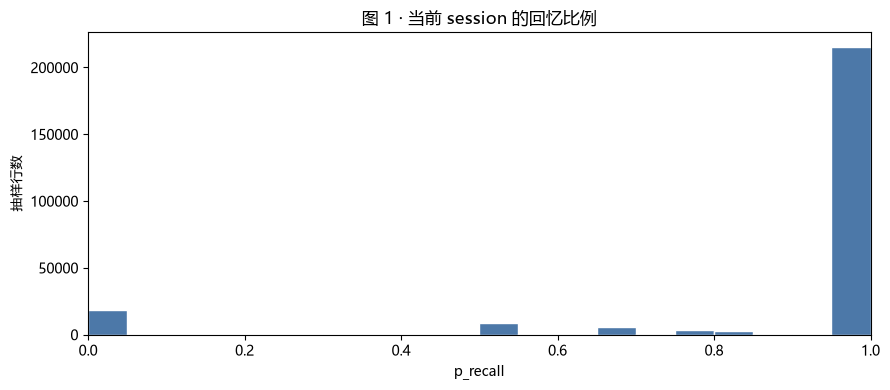

全量 p_recall=0：906,318（7.05%）
全量 p_recall=1：10,782,890（83.89%）
全量中间值：1,164,937（9.06%）


In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(eda["p_recall"], bins=np.linspace(0, 1, 21), color="#4C78A8", edgecolor="white")
ax.set(xlabel="p_recall", ylabel="抽样行数", title="图 1 · 当前 session 的回忆比例")
ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()
print(f"全量 p_recall=0：{full_p_zero:,}（{full_p_zero/full_row_count:.2%}）")
print(f"全量 p_recall=1：{full_p_one:,}（{full_p_one/full_row_count:.2%}）")
print(f"全量中间值：{full_row_count-full_p_zero-full_p_one:,}（{1-(full_p_zero+full_p_one)/full_row_count:.2%}）")

`p_recall` 大量集中在 1；模型评估不能只凭多数类的高正确率判断效果。

## 2.2 复习间隔


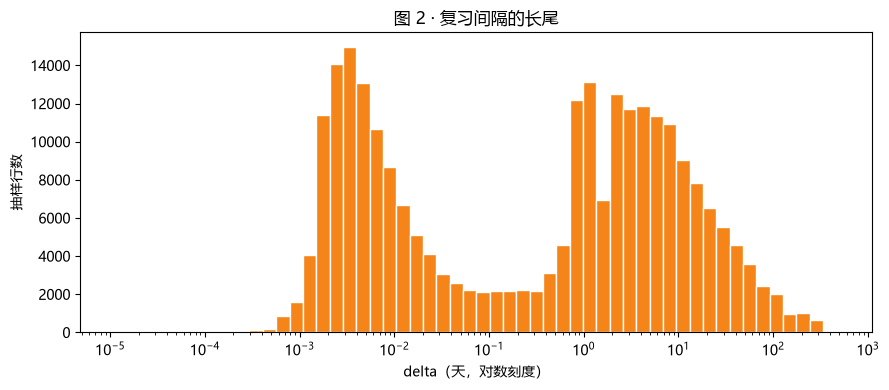

抽样中 delta=0： 0


0.00      0.000012
0.25      0.006088
0.50      0.892743
0.75      5.125822
0.90     19.899676
0.99    131.834011
1.00    464.945625
Name: delta_days, dtype: float64

In [11]:
positive_days = eda.loc[eda["delta_days"] > 0, "delta_days"]
fig, ax = plt.subplots(figsize=(9, 4))
if len(positive_days):
    log_bins = np.logspace(
        np.log10(positive_days.min()), np.log10(positive_days.max()), 55
    )
    ax.hist(positive_days, bins=log_bins, color="#F58518", edgecolor="white")
    ax.set_xscale("log")
ax.set(xlabel="delta（天，对数刻度）", ylabel="抽样行数", title="图 2 · 复习间隔的长尾")
plt.tight_layout()
plt.show()
print("抽样中 delta=0：", int(eda["delta"].eq(0).sum()))
display(eda["delta_days"].quantile([0, .25, .5, .75, .9, .99, 1]).rename("delta_days"))

复习间隔有长尾；对数横轴便于同时看到短间隔和长间隔。

## 2.3 历史练习次数


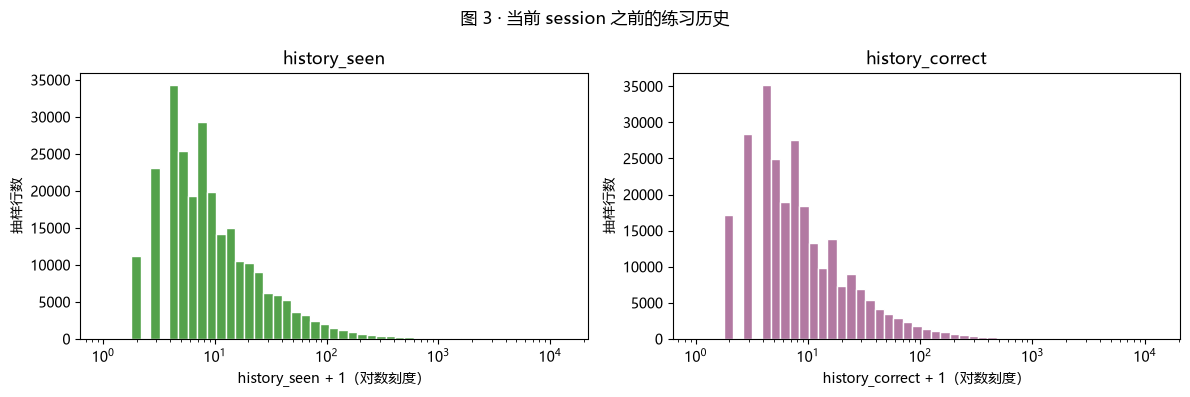

,history_seen,history_correct
0.00,1.0,1.0
0.50,6.0,6.0
0.90,36.0,32.0
0.99,234.0,206.0
1.00,13463.0,12835.0


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, field, color in zip(
    axes, ["history_seen", "history_correct"], ["#54A24B", "#B279A2"]
):
    values = eda[field].to_numpy() + 1
    bins = np.logspace(0, np.log10(values.max() + 1), 50)
    ax.hist(values, bins=bins, color=color, edgecolor="white")
    ax.set_xscale("log")
    ax.set(xlabel=f"{field} + 1（对数刻度）", ylabel="抽样行数", title=field)
plt.suptitle("图 3 · 当前 session 之前的练习历史")
plt.tight_layout()
plt.show()
display(eda[["history_seen", "history_correct"]].quantile([0, .5, .9, .99, 1]))

历史计数也有长尾，后续两个 HLR 模型对计数使用平方根变换。

## 2.4 间隔与回忆比例


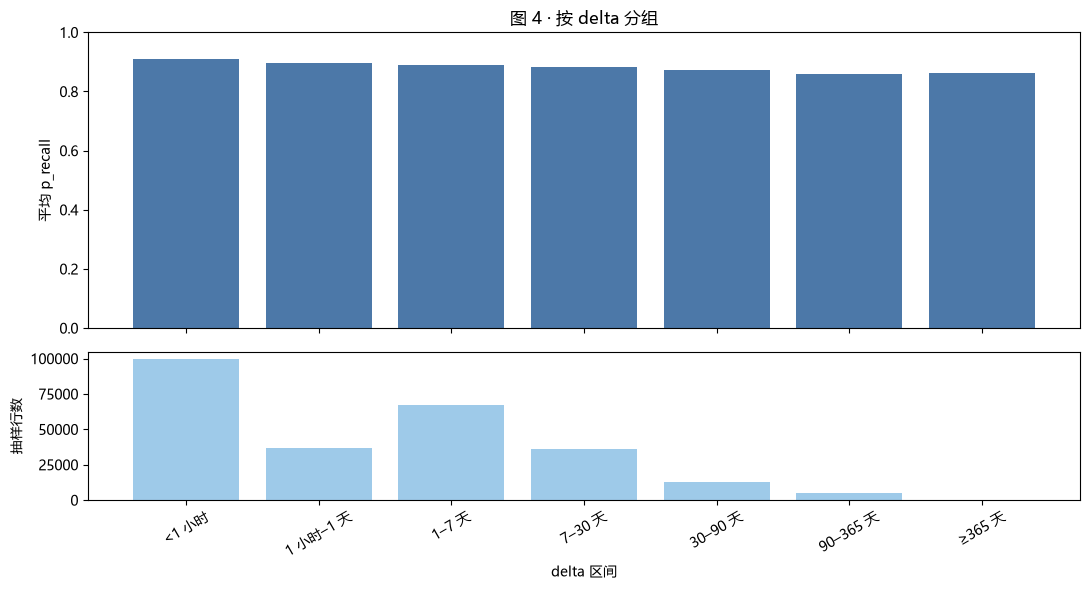

,mean_recall,n
delta_bin,,
<1 小时,0.909624,99494
1 小时–1 天,0.896490,36803
1–7 天,0.888860,67146
7–30 天,0.882713,35953
30–90 天,0.871382,12830
90–365 天,0.858637,4827
≥365 天,0.861111,30


In [13]:
delta_edges = [-np.inf, 1/24, 1, 7, 30, 90, 365, np.inf]
delta_labels = ["<1 小时", "1 小时–1 天", "1–7 天", "7–30 天",
                "30–90 天", "90–365 天", "≥365 天"]
eda["delta_bin"] = pd.cut(
    eda["delta_days"], bins=delta_edges, labels=delta_labels, right=False
)
delta_summary = eda.groupby("delta_bin", observed=False)["p_recall"].agg(
    mean_recall="mean", n="size"
)
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axes[0].bar(delta_labels, delta_summary["mean_recall"], color="#4C78A8")
axes[0].set(ylabel="平均 p_recall", ylim=(0, 1), title="图 4 · 按 delta 分组")
axes[1].bar(delta_labels, delta_summary["n"], color="#9ECAE9")
axes[1].set(ylabel="抽样行数", xlabel="delta 区间")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()
display(delta_summary)

间隔分组均值是观察性关联，不能直接当成遗忘的因果效应；同时看每组样本数。

## 2.5 历史次数与回忆比例


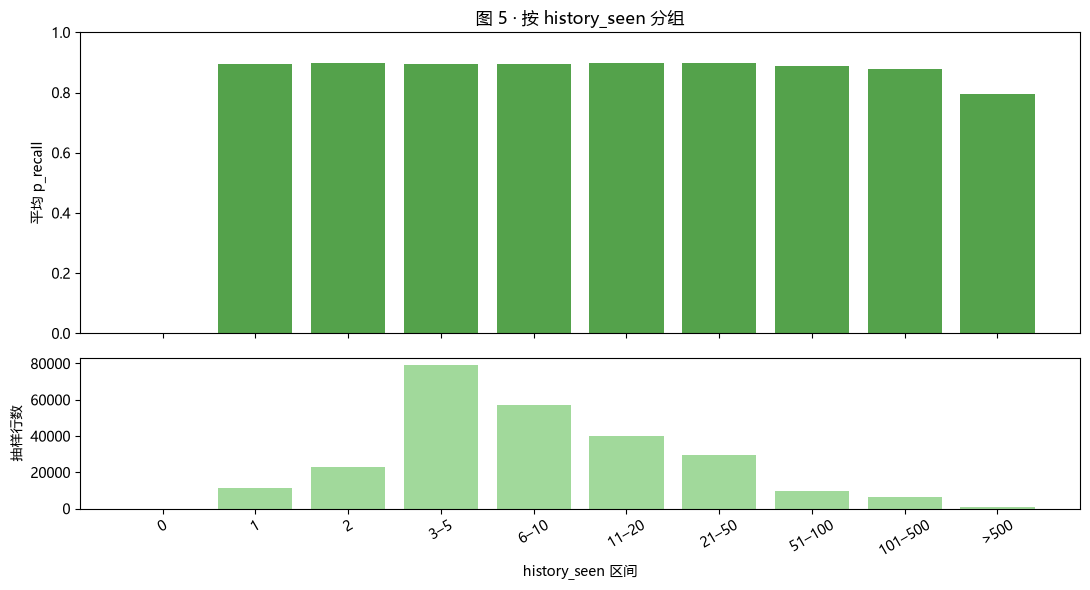

,mean_recall,n
seen_bin,,
0,NaN,0
1,0.893269,11268
2,0.899139,23030
3–5,0.895206,79000
6–10,0.896267,56938
11–20,0.898950,39830
21–50,0.899391,29790
51–100,0.888768,9793
101–500,0.876910,6456


In [14]:
seen_edges = [-1, 0, 1, 2, 5, 10, 20, 50, 100, 500, np.inf]
seen_labels = ["0", "1", "2", "3–5", "6–10", "11–20",
               "21–50", "51–100", "101–500", ">500"]
eda["seen_bin"] = pd.cut(
    eda["history_seen"], bins=seen_edges, labels=seen_labels
)
seen_summary = eda.groupby("seen_bin", observed=False)["p_recall"].agg(
    mean_recall="mean", n="size"
)
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axes[0].bar(seen_labels, seen_summary["mean_recall"], color="#54A24B")
axes[0].set(ylabel="平均 p_recall", ylim=(0, 1), title="图 5 · 按 history_seen 分组")
axes[1].bar(seen_labels, seen_summary["n"], color="#A1D99B")
axes[1].set(ylabel="抽样行数", xlabel="history_seen 区间")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()
display(seen_summary)

不同历史次数的回忆比例受用户、词项难度等因素影响；同时看每组样本数。

## 2.6 语言组合


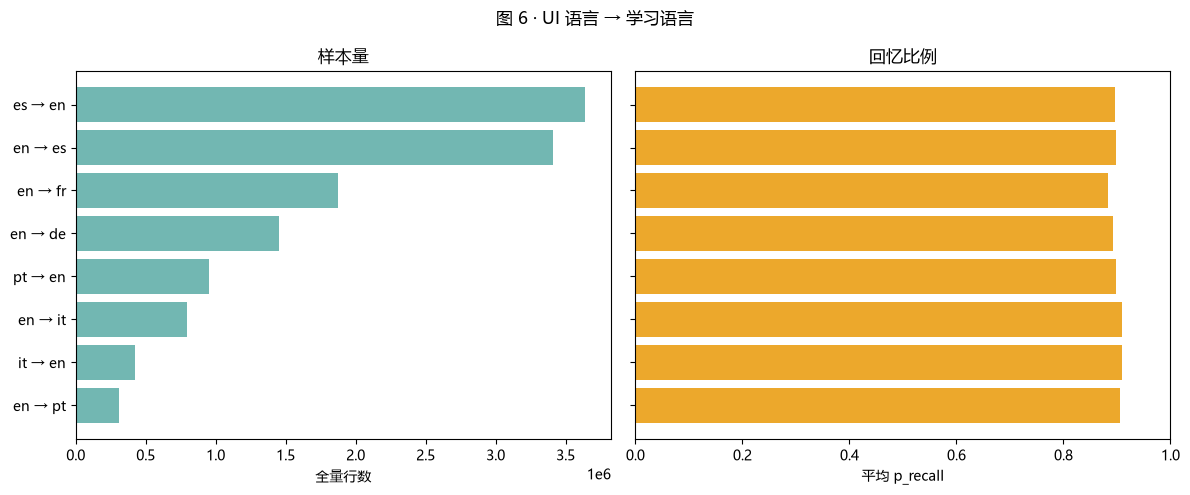

,pair,n,mean_recall
0,en → pt,311480,0.905512
1,it → en,424152,0.909596
2,en → it,793919,0.908592
3,pt → en,949460,0.898728
4,en → de,1452597,0.892786
5,en → fr,1873716,0.882756
6,en → es,3407654,0.898490
7,es → en,3641167,0.896290


In [15]:
pair_summary = pd.DataFrame([
    {
        "ui_language": ui, "learning_language": learning,
        "n": count, "mean_recall": pair_recall_sums[(ui, learning)] / count,
    }
    for (ui, learning), count in pair_counts.items()
]).sort_values("n", ascending=True).reset_index(drop=True)
pair_summary["pair"] = (
    pair_summary["ui_language"] + " → " + pair_summary["learning_language"]
)
positions = np.arange(len(pair_summary))
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
axes[0].barh(positions, pair_summary["n"], color="#72B7B2")
axes[0].set(yticks=positions, yticklabels=pair_summary["pair"],
            xlabel="全量行数", title="样本量")
axes[1].barh(positions, pair_summary["mean_recall"], color="#ECA82C")
axes[1].set(xlabel="平均 p_recall", xlim=(0, 1), title="回忆比例")
fig.suptitle("图 6 · UI 语言 → 学习语言")
plt.tight_layout()
plt.show()
display(pair_summary[["pair", "n", "mean_recall"]])

语言组合的样本量差异较大，比较组均值时应一起查看行数。

## 2.7 用户与词项频次


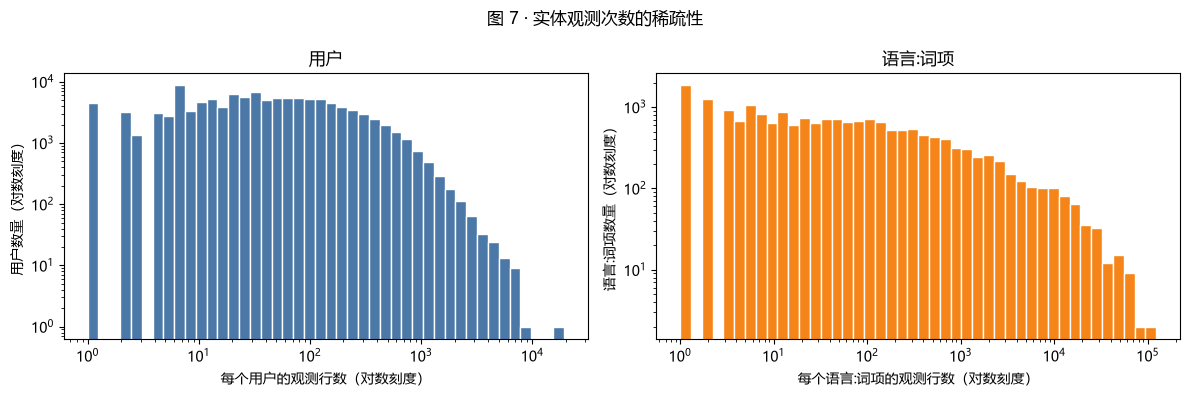

用户：115,222 个；≤5 行：11.43%
语言:词项：19,279 个；≤5 行：27.69%


,user_rows,lexeme_rows
0.00,1.00,1.00
0.50,34.00,26.00
0.90,280.00,963.00
0.99,1065.79,13757.08
1.00,19194.00,123098.00


In [16]:
user_frequency = np.fromiter(user_counts.values(), dtype=np.int64)
lexeme_frequency = np.fromiter(lexeme_counts.values(), dtype=np.int64)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, values, color, label in zip(
    axes,
    [user_frequency, lexeme_frequency],
    ["#4C78A8", "#F58518"],
    ["用户", "语言:词项"],
):
    bins = np.logspace(0, np.log10(values.max() + 1), 45)
    ax.hist(values, bins=bins, color=color, edgecolor="white")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set(xlabel=f"每个{label}的观测行数（对数刻度）",
           ylabel=f"{label}数量（对数刻度）", title=label)
plt.suptitle("图 7 · 实体观测次数的稀疏性")
plt.tight_layout()
plt.show()
print(f"用户：{len(user_frequency):,} 个；≤5 行：{np.mean(user_frequency <= 5):.2%}")
print(f"语言:词项：{len(lexeme_frequency):,} 个；≤5 行：{np.mean(lexeme_frequency <= 5):.2%}")
display(pd.DataFrame({
    "user_rows": pd.Series(user_frequency).quantile([0, .5, .9, .99, 1]),
    "lexeme_rows": pd.Series(lexeme_frequency).quantile([0, .5, .9, .99, 1]),
}))

少见用户和词项较多；完整 HLR 对训练集中未见过的词项只使用三个基础特征。

# HLR 与常数基线

[English](../../02_hlr_baselines.ipynb) · 简体中文

包含完整 HLR、HLR -lex 和 Train mean。重复运行会读取已保存的训练结果。


In [17]:
hlr_weights = train_hlr(dimension=3 + vocab_size)
hlr_results = show_model_result("Baseline 1 · HLR", hlr_weights)


  1,000,000/9,254,984 行；耗时 8.5 秒


  2,000,000/9,254,984 行；耗时 16.2 秒


  3,000,000/9,254,984 行；耗时 25.2 秒


  4,000,000/9,254,984 行；耗时 34.3 秒


  5,000,000/9,254,984 行；耗时 43.4 秒


  6,000,000/9,254,984 行；耗时 47.3 秒


  7,000,000/9,254,984 行；耗时 50.9 秒


  8,000,000/9,254,984 行；耗时 54.5 秒


  9,000,000/9,254,984 行；耗时 58.2 秒


  9,254,984/9,254,984 行；耗时 59.1 秒
Baseline 1 · HLR；输入特征维度：18,356
超参数： {'alpha': 0.01, 'L2': 0.1, 'learning_rate': 0.001, 'epochs': 1, 'seed': 42}
Loss = Σ[(p−p̂)² + 0.01(h−ĥ)²] + 0.1||θ||²
训练已完成；下表分别是完整 Train、Validation 和 Test 的效果：


,split,rows,loss_total,loss_per_row,MAE(p),AUC,Spearman(h)
0,Train,9254984,1.371574e+09,148.19838,0.123557,0.537412,0.199720
1,Validation,2313746,3.426501e+08,148.09323,0.125906,0.535212,0.194228
2,Test,1285415,1.904022e+08,148.12507,0.128033,0.537856,0.196418


In [18]:
hlr_lexless_weights = train_hlr(dimension=3)
hlr_lexless_results = show_model_result("Baseline 2 · HLR -lex", hlr_lexless_weights)


  1,000,000/9,254,984 行；耗时 3.2 秒


  2,000,000/9,254,984 行；耗时 6.3 秒


  3,000,000/9,254,984 行；耗时 9.6 秒


  4,000,000/9,254,984 行；耗时 14.5 秒


  5,000,000/9,254,984 行；耗时 17.8 秒


  6,000,000/9,254,984 行；耗时 20.9 秒


  7,000,000/9,254,984 行；耗时 24.1 秒


  8,000,000/9,254,984 行；耗时 28.1 秒


  9,000,000/9,254,984 行；耗时 32.4 秒


  9,254,984/9,254,984 行；耗时 33.3 秒
Baseline 2 · HLR -lex；输入特征维度：3
超参数： {'alpha': 0.01, 'L2': 0.1, 'learning_rate': 0.001, 'epochs': 1, 'seed': 42}
Loss = Σ[(p−p̂)² + 0.01(h−ĥ)²] + 0.1||θ||²
训练已完成；下表分别是完整 Train、Validation 和 Test 的效果：


,split,rows,loss_total,loss_per_row,MAE(p),AUC,Spearman(h)
0,Train,9254984,1.406769e+09,152.00124,0.123859,0.536885,0.158798
1,Validation,2313746,3.505060e+08,151.48855,0.126217,0.535436,0.162334
2,Test,1285415,1.949501e+08,151.66318,0.128283,0.537459,0.160552


In [19]:
mean_constant_p = float(np.mean(records["p_target"][:train_end]))
assert MIN_P <= mean_constant_p <= MAX_P

def mean_constant_split_row(split_name):
    start, stop = splits[split_name]
    p_true = records["p_target"][start:stop]
    error = mean_constant_p - p_true
    sse = float(np.dot(error, error))
    centered = p_true - float(np.mean(p_true))
    sst = float(np.dot(centered, centered))
    return {
        "model": "Train mean",
        "split": split_name,
        "n_rows": stop - start,
        "MAE(p)": float(np.abs(error).mean()),
        "RMSE(p)": float(np.sqrt(sse / (stop - start))),
        "R²": 1.0 - sse / sst if sst > 0 else np.nan,
    }

mean_constant_baseline = pd.DataFrame([
    mean_constant_split_row("Train"),
    mean_constant_split_row("Validation"),
])
print(f"Train p_target mean = {mean_constant_p:.6f}; constant input X has 0 features.")
print("Selection loss: MSE(p); the prediction is the Train mean.")
display(mean_constant_baseline.round(6))


Train p_target mean = 0.896182; constant input X has 0 features.
Selection loss: MSE(p); the prediction is the Train mean.


,model,split,n_rows,MAE(p),RMSE(p),R²
0,Train mean,Train,9254984,0.174141,0.271249,0.000000
1,Train mean,Validation,2313746,0.174389,0.271857,-0.000002


In [20]:
# Locate shared data and modules when running from a subdirectory.
from pathlib import Path
import os
import sys

_notebook_start = Path.cwd().resolve()
_notebook_parents = (_notebook_start, *_notebook_start.parents)
_project_root = next(
    (p for p in _notebook_parents
     if (p / "data/raw/settles.acl16.learning_traces.13m.csv.gz").is_file()),
    None,
)
if _project_root is None:
    _project_root = next(
        (p for p in _notebook_parents if (p / "experiment_pipeline.py").is_file()),
        _notebook_start,
    )
os.chdir(_project_root)
if str(_project_root) not in sys.path:
    sys.path.insert(0, str(_project_root))

# All required implementation code is included in this notebook.
# Execute the stages in order in this kernel.
# The inline cells above have completed this stage.


## 3.3 Baseline 1：完整 HLR

In [21]:
from IPython.display import display
print("hlr_results")
display(hlr_results)


hlr_results


,split,rows,loss_total,loss_per_row,MAE(p),AUC,Spearman(h)
0,Train,9254984,1.371574e+09,148.198377,0.123557,0.537412,0.199720
1,Validation,2313746,3.426501e+08,148.093231,0.125906,0.535212,0.194228
2,Test,1285415,1.904022e+08,148.125066,0.128033,0.537856,0.196418


## 3.4 Baseline 2：HLR -lex

In [22]:
from IPython.display import display
print("hlr_lexless_results")
display(hlr_lexless_results)


hlr_lexless_results


,split,rows,loss_total,loss_per_row,MAE(p),AUC,Spearman(h)
0,Train,9254984,1.406769e+09,152.001237,0.123859,0.536885,0.158798
1,Validation,2313746,3.505060e+08,151.488550,0.126217,0.535436,0.162334
2,Test,1285415,1.949501e+08,151.663179,0.128283,0.537459,0.160552


## 3.5 Baseline 3：Train mean 常数预测

只使用 Train 的裁剪后 `p_target` 均值作为所有记录的预测概率。均值最小化 Train 的 MSE；此基线不预测半衰期。这里报告 Train 和 Validation，Test 统一在第 8 节展示。


In [23]:
from IPython.display import display
print("mean_constant_baseline")
display(mean_constant_baseline)


mean_constant_baseline


,model,split,n_rows,MAE(p),RMSE(p),R²
0,Train mean,Train,9254984,0.174141,0.271249,0.000000
1,Train mean,Validation,2313746,0.174389,0.271857,-0.000002


# HLR 类别特征实验

[English](../../03_hlr_experiments.ipynb) · 简体中文

三个扩展模型分别加入用户、语言或两类特征。


In [24]:
def hlr_extended_layout(use_user, use_languages):
    offset = 3 + vocab_size
    layout = {
        "lex_end": offset,
        "user_start": None,
        "learning_start": None,
        "ui_start": None,
    }
    if use_user:
        layout["user_start"] = offset
        offset += n_users
    if use_languages:
        layout["learning_start"] = offset
        offset += n_learning_languages
        layout["ui_start"] = offset
        offset += n_ui_languages
    layout["dimension"] = offset
    return layout


def train_hlr_extended(name, layout):
    weights = [0.0] * layout["dimension"]
    feature_counts = [0] * layout["dimension"]
    order = np.arange(train_end, dtype=np.int32)
    np.random.default_rng(SEED).shuffle(order)
    x0_all, x1_all = records["x_correct"], records["x_wrong"]
    lex_all, p_all = records["lexeme_column"], records["p_target"]
    days_all, h_all = records["delta_days"], records["h_observed"]
    user_all = categorical_records["user_index"]
    learning_all = categorical_records["learning_index"]
    ui_all = categorical_records["ui_index"]
    started = time.perf_counter()
    for step, row_index in enumerate(order, start=1):
        x0, x1 = float(x0_all[row_index]), float(x1_all[row_index])
        lex_col = int(lex_all[row_index])
        p = float(p_all[row_index])
        days = float(days_all[row_index])
        h_true = float(h_all[row_index])
        score = weights[0] * x0 + weights[1] * x1 + weights[2]
        active = ((0, x0), (1, x1), (2, 1.0))
        if 3 <= lex_col < layout["lex_end"]:
            score += weights[lex_col]
            active += ((lex_col, 1.0),)
        if layout["user_start"] is not None:
            user_index = int(user_all[row_index])
            if user_index >= 0:
                column = layout["user_start"] + user_index
                score += weights[column]
                active += ((column, 1.0),)
        if layout["learning_start"] is not None:
            learning_index = int(learning_all[row_index])
            ui_index = int(ui_all[row_index])
            if learning_index >= 0:
                column = layout["learning_start"] + learning_index
                score += weights[column]
                active += ((column, 1.0),)
            if ui_index >= 0:
                column = layout["ui_start"] + ui_index
                score += weights[column]
                active += ((column, 1.0),)
        h_pred = math.exp2(min(max(score, LOG_MIN_H), LOG_MAX_H))
        p_pred = min(max(math.exp2(-days / h_pred), MIN_P), MAX_P)
        grad_p = (
            2.0 * (p_pred - p) * math.log(2.0)**2
            * p_pred * (days / h_pred)
        )
        grad_h = 2.0 * (h_pred - h_true) * math.log(2.0) * h_pred
        for column, value in active:
            rate = LEARNING_RATE / (
                (1.0 + p) * math.sqrt(1 + feature_counts[column])
            )
            weights[column] -= rate * grad_p * value
            weights[column] -= rate * ALPHA * grad_h * value
            weights[column] -= rate * L2 * weights[column]
            feature_counts[column] += 1
        if step % 1_000_000 == 0 or step == train_end:
            print(
                f"{name}: {step:,}/{train_end:,} Train rows; "
                f"elapsed={time.perf_counter() - started:.1f}s",
                flush=True,
            )
    return np.asarray(weights, dtype=np.float64), time.perf_counter() - started


def predict_hlr_extended_batch(weights, layout, batch, categories):
    assert len(batch) == len(categories)
    score = (
        weights[0] * batch["x_correct"]
        + weights[1] * batch["x_wrong"] + weights[2]
    )
    lexeme = batch["lexeme_column"]
    known_lexeme = (lexeme >= 3) & (lexeme < layout["lex_end"])
    score[known_lexeme] += weights[lexeme[known_lexeme]]
    if layout["user_start"] is not None:
        user_index = categories["user_index"]
        known_user = user_index >= 0
        score[known_user] += weights[
            layout["user_start"] + user_index[known_user]
        ]
    if layout["learning_start"] is not None:
        for field, start in (
            ("learning_index", layout["learning_start"]),
            ("ui_index", layout["ui_start"]),
        ):
            index = categories[field]
            known = index >= 0
            score[known] += weights[start + index[known].astype(np.int32)]
    h_pred = np.exp2(np.clip(score, LOG_MIN_H, LOG_MAX_H))
    p_pred = np.clip(
        np.exp2(-batch["delta_days"] / h_pred), MIN_P, MAX_P
    )
    return p_pred, h_pred


def evaluate_hlr_extended_validation(name, weights, layout):
    start, stop = splits["Validation"]
    count = stop - start
    p_true = records["p_target"][start:stop]
    h_true = records["h_observed"][start:stop]
    days = records["delta_days"][start:stop]
    p_pred = np.empty(count, dtype=np.float64)
    h_pred = np.empty(count, dtype=np.float64)
    for left in range(start, stop, 200_000):
        right = min(left + 200_000, stop)
        p_batch, h_batch = predict_hlr_extended_batch(
            weights, layout, records[left:right], categorical_records[left:right]
        )
        p_pred[left-start:right-start] = p_batch
        h_pred[left-start:right-start] = h_batch
    error = p_pred - p_true
    sse = float(np.dot(error, error))
    centered = p_true - float(np.mean(p_true))
    sst = float(np.dot(centered, centered))
    interior = (
        (h_true > MIN_H) & (h_true < MAX_H) & (days > 0)
    )
    n_interior = int(interior.sum())
    row = {
        "model": name,
        "split": "Validation",
        "n_train": train_end,
        "n_eval": count,
        "MAE(p)": float(np.abs(error).mean()),
        "RMSE": float(np.sqrt(sse / count)),
        "R²": 1.0 - sse / sst if sst > 0 else np.nan,
        "AUC": auc_fixed(np.rint(p_true), p_pred),
        "Spearman(h)": spearman_with_ties(h_true, h_pred),
        "n_spearman_h": count,
        "n_h_interior": n_interior,
        "h_interior_share": n_interior / count,
        "Spearman(h)_interior": (
            spearman_with_ties(h_true[interior], h_pred[interior])
            if n_interior > 1 else np.nan
        ),
    }
    abs_error = np.abs(error)
    language_index = categorical_records["learning_index"][start:stop]
    language_rows = []
    for index, language in enumerate(category_manifest["learning_values"]):
        mask = language_index == index
        count_in_group = int(mask.sum())
        language_rows.append({
            "learning_language": language,
            "rows": count_in_group,
            "MAE(p)": (
                float(abs_error[mask].mean()) if count_in_group else np.nan
            ),
        })
    unknown_language = language_index < 0
    if unknown_language.any():
        language_rows.append({
            "learning_language": "unseen",
            "rows": int(unknown_language.sum()),
            "MAE(p)": float(abs_error[unknown_language].mean()),
        })
    by_language = pd.DataFrame(language_rows)
    assert int(by_language["rows"].sum()) == count
    user_index = categorical_records["user_index"][start:stop]
    by_user = pd.DataFrame([
        {
            "user_status": status,
            "rows": int(np.count_nonzero(mask)),
            "MAE(p)": float(abs_error[mask].mean()) if mask.any() else np.nan,
        }
        for status, mask in (
            ("known", user_index >= 0),
            ("unseen", user_index < 0),
        )
    ])
    return pd.DataFrame([row]), by_language, by_user


def run_hlr_extended(name, use_user, use_languages):
    layout = hlr_extended_layout(use_user, use_languages)
    weights, fit_seconds = train_hlr_extended(name, layout)
    validation, by_language, by_user = evaluate_hlr_extended_validation(
        name, weights, layout
    )
    resources = pd.DataFrame([{
        "model": name,
        "n_train": train_end,
        "dimension": layout["dimension"],
        "fit_seconds": fit_seconds,
        "user_features": n_users if use_user else 0,
        "language_features": (
            n_learning_languages + n_ui_languages if use_languages else 0
        ),
    }])
    def predict_and_loss(batch, left, right):
        p_pred, h_pred = predict_hlr_extended_batch(
            weights, layout, batch, categorical_records[left:right]
        )
        p_error = p_pred - batch["p_target"]
        h_error = h_pred - batch["h_observed"]
        loss_sum = float(
            np.dot(p_error, p_error) + ALPHA * np.dot(h_error, h_error)
        )
        return p_pred, loss_sum

    report_model_fit(
        name, layout["dimension"], "sparse HLR base + lexeme + selected category one-hot",
        "p_target and h_observed",
        {"alpha": ALPHA, "L2": L2, "learning_rate": LEARNING_RATE,
         "epochs": EPOCHS, "seed": SEED},
        "sum[(p-p_hat)^2 + alpha*(h-h_hat)^2] + L2*||weights||^2; shown per row",
        resources, predict_and_loss,
        regularization_per_row=lambda n: L2 * float(np.dot(weights, weights)) / n,
    )
    return weights, layout, resources, validation, by_language, by_user


def report_model_fit(name, input_dim, input_description, target_description,
                     hyperparameters, loss_description, resource,
                     predict_and_loss_batch, regularization_per_row=None):
    """Report the same Train/Validation fields without touching Test."""
    print(f"Model: {name}")
    print(f"Input X shape: Train ({train_end}, {input_dim}); "
          f"Validation ({splits['Validation'][1]-splits['Validation'][0]}, {input_dim})")
    print(f"Input representation: {input_description}")
    print(f"Target: {target_description}")
    print(f"Hyperparameters: {hyperparameters}")
    print(f"Loss: {loss_description}")
    rows = []
    for split_name in ("Train", "Validation"):
        start, stop = splits[split_name]
        n = stop - start
        abs_sum = sq_sum = target_sum = target_sq_sum = loss_sum = 0.0
        for left in range(start, stop, 200_000):
            right = min(left + 200_000, stop)
            batch = records[left:right]
            p_pred, batch_loss = predict_and_loss_batch(batch, left, right)
            p_true = batch["p_target"]
            error = p_pred - p_true
            abs_sum += float(np.abs(error).sum())
            sq_sum += float(np.dot(error, error))
            target_sum += float(p_true.sum())
            target_sq_sum += float(np.dot(p_true, p_true))
            loss_sum += float(batch_loss)
        sst = target_sq_sum - target_sum ** 2 / n
        penalty = (
            float(regularization_per_row(n))
            if regularization_per_row is not None else 0.0
        )
        rows.append({
            "model": name, "split": split_name, "n_rows": n,
            "Loss/row": loss_sum / n + penalty,
            "MAE(p)": abs_sum / n,
            "RMSE(p)": math.sqrt(sq_sum / n),
            "R²": 1.0 - sq_sum / sst if sst > 0 else np.nan,
        })
    report = pd.DataFrame(rows)
    print("Fit resources:")
    display(resource.round(3))
    print("Train and Validation (Test is reported in Section 8):")
    display(report.round(6))
    return report


In [25]:
hlr_user_weights, hlr_user_layout, hlr_user_resource, hlr_user_validation, hlr_user_by_language, hlr_user_by_user = run_hlr_extended(
    "HLR-User", use_user=True, use_languages=False
)


HLR-User: 1,000,000/9,254,984 Train rows; elapsed=4.4s


HLR-User: 2,000,000/9,254,984 Train rows; elapsed=8.8s


HLR-User: 3,000,000/9,254,984 Train rows; elapsed=13.3s


HLR-User: 4,000,000/9,254,984 Train rows; elapsed=17.7s


HLR-User: 5,000,000/9,254,984 Train rows; elapsed=22.1s


HLR-User: 6,000,000/9,254,984 Train rows; elapsed=26.5s


... (5 outputs left out)

Fit resources:


,model,n_train,dimension,fit_seconds,user_features,language_features
0,HLR-User,9254984,110748,41.168,92392,0


Train and Validation (Test is reported in Section 8):


,model,split,n_rows,Loss/row,MAE(p),RMSE(p),R²
0,HLR-User,Train,9254984,126.734815,0.121706,0.288070,-0.127867
1,HLR-User,Validation,2313746,144.857456,0.124844,0.290094,-0.138672


In [26]:
hlr_lang_weights, hlr_lang_layout, hlr_lang_resource, hlr_lang_validation, hlr_lang_by_language, hlr_lang_by_user = run_hlr_extended(
    "HLR-Lang", use_user=False, use_languages=True
)


HLR-Lang: 1,000,000/9,254,984 Train rows; elapsed=5.2s


HLR-Lang: 2,000,000/9,254,984 Train rows; elapsed=10.9s


HLR-Lang: 3,000,000/9,254,984 Train rows; elapsed=16.1s


HLR-Lang: 4,000,000/9,254,984 Train rows; elapsed=21.1s


HLR-Lang: 5,000,000/9,254,984 Train rows; elapsed=25.9s


HLR-Lang: 6,000,000/9,254,984 Train rows; elapsed=30.8s


... (5 outputs left out)

Fit resources:


,model,n_train,dimension,fit_seconds,user_features,language_features
0,HLR-Lang,9254984,18366,46.696,0,10


Train and Validation (Test is reported in Section 8):


,model,split,n_rows,Loss/row,MAE(p),RMSE(p),R²
0,HLR-Lang,Train,9254984,148.036429,0.123471,0.289305,-0.137564
1,HLR-Lang,Validation,2313746,147.936141,0.125806,0.290641,-0.142972


In [27]:
hlr_both_weights, hlr_both_layout, hlr_both_resource, hlr_both_validation, hlr_both_by_language, hlr_both_by_user = run_hlr_extended(
    "HLR-User+Lang", use_user=True, use_languages=True
)


HLR-User+Lang: 1,000,000/9,254,984 Train rows; elapsed=5.6s


HLR-User+Lang: 2,000,000/9,254,984 Train rows; elapsed=11.3s


HLR-User+Lang: 3,000,000/9,254,984 Train rows; elapsed=17.0s


HLR-User+Lang: 4,000,000/9,254,984 Train rows; elapsed=22.9s


HLR-User+Lang: 5,000,000/9,254,984 Train rows; elapsed=28.5s


HLR-User+Lang: 6,000,000/9,254,984 Train rows; elapsed=34.3s


... (5 outputs left out)

Fit resources:


,model,n_train,dimension,fit_seconds,user_features,language_features
0,HLR-User+Lang,9254984,110758,53.092,92392,10


Train and Validation (Test is reported in Section 8):


,model,split,n_rows,Loss/row,MAE(p),RMSE(p),R²
0,HLR-User+Lang,Train,9254984,126.328052,0.121609,0.288042,-0.127649
1,HLR-User+Lang,Validation,2313746,145.068698,0.124616,0.289985,-0.137812


In [28]:
# Locate shared data and modules when running from a subdirectory.
from pathlib import Path
import os
import sys

_notebook_start = Path.cwd().resolve()
_notebook_parents = (_notebook_start, *_notebook_start.parents)
_project_root = next(
    (p for p in _notebook_parents
     if (p / "data/raw/settles.acl16.learning_traces.13m.csv.gz").is_file()),
    None,
)
if _project_root is None:
    _project_root = next(
        (p for p in _notebook_parents if (p / "experiment_pipeline.py").is_file()),
        _notebook_start,
    )
os.chdir(_project_root)
if str(_project_root) not in sys.path:
    sys.path.insert(0, str(_project_root))

# All required implementation code is included in this notebook.
# Execute the stages in order in this kernel.
# The inline cells above have completed this stage.


## 4.1 HLR-User

在完整 HLR 后加入 Train 用户 one-hot；Validation/Test 中未见用户不激活用户权重。原始数据下的参考值，去重后需重新计算；来源 notebook 的 Validation MAE(p) 约为 `0.125200`，可作为移植后的核对值。


In [29]:
from IPython.display import display
print("hlr_user_validation")
display(hlr_user_validation)
print("hlr_user_resource")
display(hlr_user_resource)


hlr_user_validation


,model,split,n_train,n_eval,MAE(p),RMSE,R²,AUC,Spearman(h),n_spearman_h,n_h_interior,h_interior_share,Spearman(h)_interior
0,HLR-User,Validation,9254984,2313746,0.124844,0.290094,-0.138672,0.538649,0.241829,2313746,1025825,0.443361,0.038417


hlr_user_resource


,model,n_train,dimension,fit_seconds,user_features,language_features
0,HLR-User,9254984,110748,41.168308,92392,0


## 4.2 HLR-Lang

在完整 HLR 后分别加入 `learning_language` 的 6 个位置和 `ui_language` 的 4 个位置。每行各激活一个已知语言位置；未见类别全零。原始数据下的参考值，去重后需重新计算；来源 notebook 的 Validation MAE(p) 约为 `0.126131`。


In [30]:
from IPython.display import display
print("hlr_lang_validation")
display(hlr_lang_validation)
print("hlr_lang_resource")
display(hlr_lang_resource)


hlr_lang_validation


,model,split,n_train,n_eval,MAE(p),RMSE,R²,AUC,Spearman(h),n_spearman_h,n_h_interior,h_interior_share,Spearman(h)_interior
0,HLR-Lang,Validation,9254984,2313746,0.125806,0.290641,-0.142972,0.535468,0.195588,2313746,1025825,0.443361,0.05245


hlr_lang_resource


,model,n_train,dimension,fit_seconds,user_features,language_features
0,HLR-Lang,9254984,18366,46.695759,0,10


## 4.3 HLR-User+Lang

完整 HLR 同时加入用户与两列语言 one-hot。模型独立从零训练，不从前两个扩展模型继续训练。原始数据下的参考值，去重后需重新计算；来源 notebook 的 Validation MAE(p) 约为 `0.124987`。


In [31]:
from IPython.display import display
print("hlr_both_validation")
display(hlr_both_validation)
print("hlr_both_resource")
display(hlr_both_resource)


hlr_both_validation


,model,split,n_train,n_eval,MAE(p),RMSE,R²,AUC,Spearman(h),n_spearman_h,n_h_interior,h_interior_share,Spearman(h)_interior
0,HLR-User+Lang,Validation,9254984,2313746,0.124616,0.289985,-0.137812,0.537505,0.240462,2313746,1025825,0.443361,0.036283


hlr_both_resource


,model,n_train,dimension,fit_seconds,user_features,language_features
0,HLR-User+Lang,9254984,110758,53.091914,92392,10


# 随机森林实验

[English](../../04_random_forest.ipynb) · 简体中文

E1 预测 log2 半衰期，E2 直接预测回忆率。


In [32]:
from itertools import product
from sklearn.ensemble import RandomForestRegressor

RF_TUNE_N, RF_FINAL_N, RF_BATCH = 200_000, train_end, 200_000
# Keep the original 200k tuning rows fixed; final fits use the full Train split.
rf_tune_pool = np.sort(
    np.random.default_rng(SEED).choice(train_end, 1_000_000, replace=False)
)
rf_tune_indices = np.sort(
    np.random.default_rng(SEED + 1).choice(rf_tune_pool, RF_TUNE_N, replace=False)
)
del rf_tune_pool
assert len(rf_tune_indices) == RF_TUNE_N and rf_tune_indices[-1] < train_end
assert RF_FINAL_N == splits['Train'][1]

def rf_x_from_records(batch):
    x = np.empty((len(batch), 3), dtype=np.float32)
    x[:, 0] = batch['x_correct']
    x[:, 1] = batch['x_wrong']
    x[:, 2] = 1.0
    return x

def rf_logh_predictions(model, batch):
    score = model.predict(rf_x_from_records(batch))
    h_pred = np.exp2(np.clip(score, LOG_MIN_H, LOG_MAX_H))
    p_pred = np.clip(np.exp2(-batch["delta_days"] / h_pred), MIN_P, MAX_P)
    return p_pred, h_pred

rf_tune_records = records[rf_tune_indices]
rf_tune_x = rf_x_from_records(rf_tune_records)
rf_tune_y = np.log2(rf_tune_records["h_observed"])
val_start, val_stop = splits["Validation"]
rf_candidate_rows = []
for depth, leaf in product((8, 12, 16), (50, 100)):
    candidate = RandomForestRegressor(
        criterion="squared_error", n_estimators=100, max_depth=depth,
        min_samples_leaf=leaf, max_features=1.0, n_jobs=-1, random_state=SEED,
    )
    fit_started = time.perf_counter()
    candidate.fit(rf_tune_x, rf_tune_y)
    fit_seconds = time.perf_counter() - fit_started
    predict_started = time.perf_counter()
    absolute_error_sum = 0.0
    for left in range(val_start, val_stop, RF_BATCH):
        right = min(left + RF_BATCH, val_stop)
        p_pred, _ = rf_logh_predictions(candidate, records[left:right])
        absolute_error_sum += float(np.abs(
            p_pred - records["p_target"][left:right]
        ).sum())
    predict_seconds = time.perf_counter() - predict_started
    rf_candidate_rows.append({
        "max_depth": depth,
        "min_samples_leaf": leaf,
        "n_train": RF_TUNE_N,
        "n_validation": val_stop - val_start,
        "fit_seconds": fit_seconds,
        "predict_seconds": predict_seconds,
        "MAE(p)": absolute_error_sum / (val_stop - val_start),
    })
    del candidate

rf_candidate_results = pd.DataFrame(rf_candidate_rows).sort_values(
    ["MAE(p)", "max_depth", "min_samples_leaf"],
    ascending=[True, True, False],
).reset_index(drop=True)
rf_selected_depth = int(rf_candidate_results.loc[0, "max_depth"])
rf_selected_leaf = int(rf_candidate_results.loc[0, "min_samples_leaf"])
display(rf_candidate_results.round({"fit_seconds": 2, "predict_seconds": 2, "MAE(p)": 6}))


,max_depth,min_samples_leaf,n_train,n_validation,fit_seconds,predict_seconds,MAE(p)
0,8,50,200000,2313746,0.38,0.90,0.160599
1,8,100,200000,2313746,0.35,0.90,0.160651
2,12,50,200000,2313746,0.37,0.89,0.160684
3,12,100,200000,2313746,0.36,0.97,0.160715
4,16,50,200000,2313746,0.35,0.92,0.160720
5,16,100,200000,2313746,0.38,0.90,0.160725


In [33]:
import threading
import psutil

rf_process = psutil.Process()
rf_rss_before = rf_process.memory_info().rss
rf_peak_rss = [rf_rss_before]
rf_monitor_stop = threading.Event()

def rf_watch_rss():
    while not rf_monitor_stop.wait(0.1):
        rf_peak_rss[0] = max(rf_peak_rss[0], rf_process.memory_info().rss)

rf_monitor = threading.Thread(target=rf_watch_rss, daemon=True)
rf_monitor.start()
try:
    rf_final_records = records[:train_end]
    rf_final_x = rf_x_from_records(rf_final_records)
    rf_final_y = np.log2(rf_final_records["h_observed"])
    rf_e1_model = RandomForestRegressor(
        criterion="squared_error", n_estimators=100,
        max_depth=rf_selected_depth, min_samples_leaf=rf_selected_leaf,
        max_features=1.0, n_jobs=-1, random_state=SEED,
    )
    fit_started = time.perf_counter()
    rf_e1_model.fit(rf_final_x, rf_final_y)
    rf_final_fit_seconds = time.perf_counter() - fit_started
    del rf_final_records, rf_final_x, rf_final_y, rf_tune_records, rf_tune_x, rf_tune_y

    n_val = val_stop - val_start
    p_true = records["p_target"][val_start:val_stop]
    h_true = records["h_observed"][val_start:val_stop]
    days = records["delta_days"][val_start:val_stop]
    rf_e1_p_pred = np.empty(n_val, dtype=np.float64)
    rf_e1_h_pred = np.empty(n_val, dtype=np.float64)
    predict_started = time.perf_counter()
    for left in range(val_start, val_stop, RF_BATCH):
        right = min(left + RF_BATCH, val_stop)
        batch = records[left:right]
        offset_left, offset_right = left - val_start, right - val_start
        p_batch, h_batch = rf_logh_predictions(rf_e1_model, batch)
        rf_e1_p_pred[offset_left:offset_right] = p_batch
        rf_e1_h_pred[offset_left:offset_right] = h_batch
    rf_final_predict_seconds = time.perf_counter() - predict_started
finally:
    rf_monitor_stop.set()
    rf_monitor.join()
    rf_peak_rss[0] = max(rf_peak_rss[0], rf_process.memory_info().rss)

assert np.isfinite(rf_e1_p_pred).all() and np.isfinite(rf_e1_h_pred).all()
assert np.all((MIN_P <= rf_e1_p_pred) & (rf_e1_p_pred <= MAX_P))
assert np.all((MIN_H <= rf_e1_h_pred) & (rf_e1_h_pred <= MAX_H))

interior = (h_true > MIN_H) & (h_true < MAX_H) & (days > 0)
n_interior = int(interior.sum())

def rf_e1_metric_row(name, n_train, p_pred, h_pred):
    error = p_pred - p_true
    return {
        "model": name, "n_train": n_train, "n_validation": n_val,
        "MAE(p)": float(np.abs(error).mean()),
        "RMSE(p)": float(np.sqrt(np.mean(error ** 2))),
        "AUC": auc_fixed(np.rint(p_true), p_pred),
        "Spearman(h)": spearman_with_ties(h_true, h_pred),
        "n_spearman_h": n_val,
        "n_h_interior": n_interior,
        "h_interior_share": n_interior / n_val,
        "Spearman(h)_interior": spearman_with_ties(
            h_true[interior], h_pred[interior]
        ),
        "p_hat_at_bounds": float(np.mean((p_pred == MIN_P) | (p_pred == MAX_P))),
        "h_hat_at_bounds": float(np.mean((h_pred == MIN_H) | (h_pred == MAX_H))),
    }

rf_e1_validation = pd.DataFrame([
    rf_e1_metric_row("RF-logh (E1)", RF_FINAL_N, rf_e1_p_pred, rf_e1_h_pred),
])
rf_e1_resource = pd.DataFrame([{
    "n_train": RF_FINAL_N, "max_depth": rf_selected_depth,
    "min_samples_leaf": rf_selected_leaf,
    "fit_seconds": rf_final_fit_seconds,
    "predict_seconds": rf_final_predict_seconds,
    "rss_before_GiB": rf_rss_before / 2**30,
    "peak_rss_GiB": rf_peak_rss[0] / 2**30,
}])


def rf_e1_report_batch(batch, left, right):
    raw_logh = rf_e1_model.predict(rf_x_from_records(batch))
    h_pred = np.exp2(np.clip(raw_logh, LOG_MIN_H, LOG_MAX_H))
    p_pred = np.clip(
        np.exp2(-batch["delta_days"] / h_pred), MIN_P, MAX_P
    )
    error = raw_logh - np.log2(batch["h_observed"])
    return p_pred, float(np.dot(error, error))

rf_e1_fit_report = report_model_fit(
    "RF-logh (E1)", 3, "dense [x_correct, x_wrong, bias]",
    "log2(h_observed)",
    {"criterion": "squared_error", "n_estimators": 100,
     "max_depth": rf_selected_depth, "min_samples_leaf": rf_selected_leaf,
     "max_features": 1.0, "random_state": SEED},
    "MSE(raw log2(h) prediction, log2(h_observed))",
    rf_e1_resource, rf_e1_report_batch,
)


Model: RF-logh (E1)
Input X shape: Train (9254984, 3); Validation (2313746, 3)
Input representation: dense [x_correct, x_wrong, bias]
Target: log2(h_observed)
Hyperparameters: {'criterion': 'squared_error', 'n_estimators': 100, 'max_depth': 8, 'min_samples_leaf': 50, 'max_features': 1.0, 'random_state': 42}
Loss: MSE(raw log2(h) prediction, log2(h_observed))


Fit resources:


,n_train,max_depth,min_samples_leaf,fit_seconds,predict_seconds,rss_before_GiB,peak_rss_GiB
0,9254984,8,50,59.963,0.93,0.807,8.592


Train and Validation (Test is reported in Section 8):


,model,split,n_rows,Loss/row,MAE(p),RMSE(p),R²
0,RF-logh (E1),Train,9254984,14.876342,0.155618,0.310390,-0.309416
1,RF-logh (E1),Validation,2313746,14.766794,0.160425,0.314653,-0.339631


In [34]:
def rf_p_x_from_records(batch):
    x = np.empty((len(batch), 4), dtype=np.float32)
    x[:, 0] = batch['x_correct']
    x[:, 1] = batch['x_wrong']
    x[:, 2] = 1.0
    x[:, 3] = batch['delta_days']
    return x

def rf_p_predictions(model, batch):
    p_pred = np.clip(model.predict(rf_p_x_from_records(batch)), MIN_P, MAX_P)
    h_pred = np.clip(-batch["delta_days"] / np.log2(p_pred), MIN_H, MAX_H)
    return p_pred, h_pred

rf_p_tune_x = rf_p_x_from_records(records[rf_tune_indices])
rf_p_tune_y = records["p_target"][rf_tune_indices].copy()
rf_p_candidate_rows = []
for depth, leaf in product((8, 12, 16), (50, 100)):
    candidate = RandomForestRegressor(
        criterion="squared_error", n_estimators=100, max_depth=depth,
        min_samples_leaf=leaf, max_features=1.0, n_jobs=-1, random_state=SEED,
    )
    fit_started = time.perf_counter()
    candidate.fit(rf_p_tune_x, rf_p_tune_y)
    fit_seconds = time.perf_counter() - fit_started
    predict_started = time.perf_counter()
    absolute_error_sum = 0.0
    for left in range(val_start, val_stop, RF_BATCH):
        right = min(left + RF_BATCH, val_stop)
        p_pred, _ = rf_p_predictions(candidate, records[left:right])
        absolute_error_sum += float(np.abs(
            p_pred - records["p_target"][left:right]
        ).sum())
    predict_seconds = time.perf_counter() - predict_started
    rf_p_candidate_rows.append({
        "max_depth": depth, "min_samples_leaf": leaf,
        "n_train": RF_TUNE_N, "n_validation": val_stop - val_start,
        "fit_seconds": fit_seconds, "predict_seconds": predict_seconds,
        "MAE(p)": absolute_error_sum / (val_stop - val_start),
    })
    del candidate

rf_p_candidate_results = pd.DataFrame(rf_p_candidate_rows).sort_values(
    ["MAE(p)", "max_depth", "min_samples_leaf"],
    ascending=[True, True, False],
).reset_index(drop=True)
rf_p_selected_depth = int(rf_p_candidate_results.loc[0, "max_depth"])
rf_p_selected_leaf = int(rf_p_candidate_results.loc[0, "min_samples_leaf"])
display(rf_p_candidate_results.round({"fit_seconds": 2, "predict_seconds": 2, "MAE(p)": 6}))


,max_depth,min_samples_leaf,n_train,n_validation,fit_seconds,predict_seconds,MAE(p)
0,12,50,200000,2313746,1.24,1.15,0.170564
1,16,50,200000,2313746,1.43,1.26,0.170566
2,12,100,200000,2313746,1.25,1.17,0.170703
3,16,100,200000,2313746,1.33,1.16,0.170711
4,8,50,200000,2313746,0.92,0.93,0.170763
5,8,100,200000,2313746,1.00,0.98,0.170875


In [35]:
rf_p_process = psutil.Process()
rf_p_rss_before = rf_p_process.memory_info().rss
rf_p_peak_rss = [rf_p_rss_before]
rf_p_monitor_stop = threading.Event()

def rf_p_watch_rss():
    while not rf_p_monitor_stop.wait(0.1):
        rf_p_peak_rss[0] = max(rf_p_peak_rss[0], rf_p_process.memory_info().rss)

rf_p_monitor = threading.Thread(target=rf_p_watch_rss, daemon=True)
rf_p_monitor.start()
try:
    rf_p_final_x = rf_p_x_from_records(records[:train_end])
    rf_p_final_y = records["p_target"][:train_end]
    rf_e2_model = RandomForestRegressor(
        criterion="squared_error", n_estimators=100,
        max_depth=rf_p_selected_depth, min_samples_leaf=rf_p_selected_leaf,
        max_features=1.0, n_jobs=-1, random_state=SEED,
    )
    fit_started = time.perf_counter()
    rf_e2_model.fit(rf_p_final_x, rf_p_final_y)
    rf_e2_fit_seconds = time.perf_counter() - fit_started
    del rf_p_final_x, rf_p_final_y, rf_p_tune_x, rf_p_tune_y

    rf_e2_p_pred = np.empty(n_val, dtype=np.float64)
    rf_e2_h_pred = np.empty(n_val, dtype=np.float64)
    predict_started = time.perf_counter()
    for left in range(val_start, val_stop, RF_BATCH):
        right = min(left + RF_BATCH, val_stop)
        p_batch, h_batch = rf_p_predictions(rf_e2_model, records[left:right])
        offset_left, offset_right = left - val_start, right - val_start
        rf_e2_p_pred[offset_left:offset_right] = p_batch
        rf_e2_h_pred[offset_left:offset_right] = h_batch
    rf_e2_predict_seconds = time.perf_counter() - predict_started
finally:
    rf_p_monitor_stop.set()
    rf_p_monitor.join()
    rf_p_peak_rss[0] = max(rf_p_peak_rss[0], rf_p_process.memory_info().rss)

assert np.isfinite(rf_e2_p_pred).all() and np.isfinite(rf_e2_h_pred).all()
assert np.all((MIN_P <= rf_e2_p_pred) & (rf_e2_p_pred <= MAX_P))
assert np.all((MIN_H <= rf_e2_h_pred) & (rf_e2_h_pred <= MAX_H))
rf_e2_validation = pd.DataFrame([
    rf_e1_metric_row("RF-p (E2)", RF_FINAL_N, rf_e2_p_pred, rf_e2_h_pred),
])
rf_e2_resource = pd.DataFrame([{
    "n_train": RF_FINAL_N, "max_depth": rf_p_selected_depth,
    "min_samples_leaf": rf_p_selected_leaf,
    "fit_seconds": rf_e2_fit_seconds,
    "predict_seconds": rf_e2_predict_seconds,
    "rss_before_GiB": rf_p_rss_before / 2**30,
    "peak_rss_GiB": rf_p_peak_rss[0] / 2**30,
}])


def rf_e2_report_batch(batch, left, right):
    raw_p = rf_e2_model.predict(rf_p_x_from_records(batch))
    p_pred = np.clip(raw_p, MIN_P, MAX_P)
    error = raw_p - batch["p_target"]
    return p_pred, float(np.dot(error, error))

rf_e2_fit_report = report_model_fit(
    "RF-p (E2)", 4, "dense [x_correct, x_wrong, bias, delta_days]",
    "p_target",
    {"criterion": "squared_error", "n_estimators": 100,
     "max_depth": rf_p_selected_depth, "min_samples_leaf": rf_p_selected_leaf,
     "max_features": 1.0, "random_state": SEED},
    "MSE(raw p prediction, p_target)",
    rf_e2_resource, rf_e2_report_batch,
)


Model: RF-p (E2)
Input X shape: Train (9254984, 4); Validation (2313746, 4)
Input representation: dense [x_correct, x_wrong, bias, delta_days]
Target: p_target
Hyperparameters: {'criterion': 'squared_error', 'n_estimators': 100, 'max_depth': 12, 'min_samples_leaf': 50, 'max_features': 1.0, 'random_state': 42}
Loss: MSE(raw p prediction, p_target)


Fit resources:


,n_train,max_depth,min_samples_leaf,fit_seconds,predict_seconds,rss_before_GiB,peak_rss_GiB
0,9254984,12,50,138.394,1.128,0.842,8.686


Train and Validation (Test is reported in Section 8):


,model,split,n_rows,Loss/row,MAE(p),RMSE(p),R²
0,RF-p (E2),Train,9254984,0.071470,0.169193,0.267339,0.028622
1,RF-p (E2),Validation,2313746,0.071622,0.169912,0.267622,0.030907


In [36]:
# Locate shared data and modules when running from a subdirectory.
from pathlib import Path
import os
import sys

_notebook_start = Path.cwd().resolve()
_notebook_parents = (_notebook_start, *_notebook_start.parents)
_project_root = next(
    (p for p in _notebook_parents
     if (p / "data/raw/settles.acl16.learning_traces.13m.csv.gz").is_file()),
    None,
)
if _project_root is None:
    _project_root = next(
        (p for p in _notebook_parents if (p / "experiment_pipeline.py").is_file()),
        _notebook_start,
    )
os.chdir(_project_root)
if str(_project_root) not in sys.path:
    sys.path.insert(0, str(_project_root))

# All required implementation code is included in this notebook.
# Execute the stages in order in this kernel.
# The inline cells above have completed this stage.


# 5. 随机森林实验

## 5.1 E1：RF-logh 的超参数选择与全量训练

使用 HLR -lex 的三个 `x` 特征预测 `log2(h_observed)`。六组候选仍在固定的 20 万条 Train 样本上训练，并在完整 Validation 上按 `MAE(p)` 选参；选出的配置在全部 Train 上重新训练。Test 统一在第 8 节评估。

In [37]:
from IPython.display import display
print("rf_candidate_results")
display(rf_candidate_results)
print("rf_e1_validation")
display(rf_e1_validation)
print("rf_e1_resource")
display(rf_e1_resource)


rf_candidate_results


,max_depth,min_samples_leaf,n_train,n_validation,fit_seconds,predict_seconds,MAE(p)
0,8,50,200000,2313746,0.376220,0.899469,0.160599
1,8,100,200000,2313746,0.347543,0.901953,0.160651
2,12,50,200000,2313746,0.374751,0.888924,0.160684
3,12,100,200000,2313746,0.358289,0.968176,0.160715
4,16,50,200000,2313746,0.353982,0.919934,0.160720
5,16,100,200000,2313746,0.376353,0.898839,0.160725


rf_e1_validation


,model,n_train,n_validation,MAE(p),RMSE(p),AUC,Spearman(h),n_spearman_h,n_h_interior,h_interior_share,Spearman(h)_interior,p_hat_at_bounds,h_hat_at_bounds
0,RF-logh (E1),9254984,2313746,0.160425,0.314653,0.548231,0.163656,2313746,1025825,0.443361,0.043351,0.240248,0.0


rf_e1_resource


,n_train,max_depth,min_samples_leaf,fit_seconds,predict_seconds,rss_before_GiB,peak_rss_GiB
0,9254984,8,50,59.962719,0.93005,0.807011,8.592201


## 5.2 E2：RF-p 直接预测回忆率

E2 与 E1 共用 20 万条候选训练行，正式拟合使用全部 Train。输入为 `[x_correct, x_wrong, bias, delta_days]`，目标为 `p_target`。模型预测 `p_hat`；`h_hat` 由 `p_hat` 与 `delta_days` 反推，只用于诊断。

In [38]:
from IPython.display import display
print("rf_p_candidate_results")
display(rf_p_candidate_results)
print("rf_e2_validation")
display(rf_e2_validation)
print("rf_e2_resource")
display(rf_e2_resource)


rf_p_candidate_results


,max_depth,min_samples_leaf,n_train,n_validation,fit_seconds,predict_seconds,MAE(p)
0,12,50,200000,2313746,1.244543,1.145721,0.170564
1,16,50,200000,2313746,1.429521,1.262872,0.170566
2,12,100,200000,2313746,1.251496,1.171280,0.170703
3,16,100,200000,2313746,1.327285,1.156205,0.170711
4,8,50,200000,2313746,0.923743,0.929329,0.170763
5,8,100,200000,2313746,1.000856,0.976339,0.170875


rf_e2_validation


,model,n_train,n_validation,MAE(p),RMSE(p),AUC,Spearman(h),n_spearman_h,n_h_interior,h_interior_share,Spearman(h)_interior,p_hat_at_bounds,h_hat_at_bounds
0,RF-p (E2),9254984,2313746,0.169912,0.267622,0.608063,0.624224,2313746,1025825,0.443361,0.022707,0.000013,0.06882


rf_e2_resource


,n_train,max_depth,min_samples_leaf,fit_seconds,predict_seconds,rss_before_GiB,peak_rss_GiB
0,9254984,12,50,138.393915,1.127818,0.8423,8.686489


# LightGBM 实验

[English](../../05_lightgbm.ipynb) · 简体中文

E3 预测 log2 半衰期，E4 直接预测回忆率。


In [39]:
import gc
import lightgbm as lgb
from lightgbm import LGBMRegressor

lgbm_tune_x = rf_x_from_records(records[rf_tune_indices])
lgbm_tune_y = np.log2(records["h_observed"][rf_tune_indices])
lgbm_val_x = rf_x_from_records(records[val_start:val_stop])
lgbm_val_y = np.log2(records["h_observed"][val_start:val_stop])
lgbm_val_days = records["delta_days"][val_start:val_stop]
lgbm_val_p = records["p_target"][val_start:val_stop]

def lgbm_logh_predictions(model, x, delta_days):
    score = model.predict(x, num_iteration=model.best_iteration_)
    h_pred = np.exp2(np.clip(score, LOG_MIN_H, LOG_MAX_H))
    p_pred = np.clip(np.exp2(-delta_days / h_pred), MIN_P, MAX_P)
    return p_pred, h_pred

lgbm_e3_candidate_rows = []
for leaves, min_child in product((15, 31, 63), (50, 200)):
    candidate = LGBMRegressor(
        objective="regression", n_estimators=1000, learning_rate=0.05,
        num_leaves=leaves, min_child_samples=min_child,
        random_state=SEED, n_jobs=-1, verbosity=-1,
    )
    fit_started = time.perf_counter()
    candidate.fit(
        lgbm_tune_x, lgbm_tune_y,
        eval_set=[(lgbm_val_x, lgbm_val_y)], eval_metric="l2",
        callbacks=[lgb.early_stopping(50, verbose=False)],
    )
    fit_seconds = time.perf_counter() - fit_started
    predict_started = time.perf_counter()
    p_pred, _ = lgbm_logh_predictions(candidate, lgbm_val_x, lgbm_val_days)
    predict_seconds = time.perf_counter() - predict_started
    lgbm_e3_candidate_rows.append({
        "num_leaves": leaves, "min_child_samples": min_child,
        "best_iteration": int(candidate.best_iteration_),
        "n_train": RF_TUNE_N, "n_validation": len(lgbm_val_p),
        "fit_seconds": fit_seconds, "predict_seconds": predict_seconds,
        "MAE(p)": float(np.abs(p_pred - lgbm_val_p).mean()),
    })
    del candidate, p_pred
    gc.collect()

lgbm_e3_candidate_results = pd.DataFrame(lgbm_e3_candidate_rows).sort_values(
    ["MAE(p)", "num_leaves", "min_child_samples"],
    ascending=[True, True, False],
).reset_index(drop=True)
lgbm_e3_selected_leaves = int(lgbm_e3_candidate_results.loc[0, "num_leaves"])
lgbm_e3_selected_min_child = int(lgbm_e3_candidate_results.loc[0, "min_child_samples"])
display(lgbm_e3_candidate_results.round({"fit_seconds": 2, "predict_seconds": 2, "MAE(p)": 6}))


D:\fujing123\miniconda3\envs\data-science\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


D:\fujing123\miniconda3\envs\data-science\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


D:\fujing123\miniconda3\envs\data-science\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


D:\fujing123\miniconda3\envs\data-science\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


D:\fujing123\miniconda3\envs\data-science\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


D:\fujing123\miniconda3\envs\data-science\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


,num_leaves,min_child_samples,best_iteration,n_train,n_validation,fit_seconds,predict_seconds,MAE(p)
0,15,50,94,200000,2313746,0.76,0.41,0.160506
1,15,200,91,200000,2313746,0.80,0.41,0.160547
2,31,50,65,200000,2313746,0.79,0.30,0.160559
3,31,200,73,200000,2313746,1.12,0.34,0.160601
4,63,50,53,200000,2313746,0.98,0.29,0.160641
5,63,200,61,200000,2313746,1.32,0.43,0.160676


In [40]:
lgbm_e3_process = psutil.Process()
lgbm_e3_rss_before = lgbm_e3_process.memory_info().rss
lgbm_e3_peak_rss = [lgbm_e3_rss_before]
lgbm_e3_monitor_stop = threading.Event()

def lgbm_e3_watch_rss():
    while not lgbm_e3_monitor_stop.wait(0.1):
        lgbm_e3_peak_rss[0] = max(
            lgbm_e3_peak_rss[0], lgbm_e3_process.memory_info().rss
        )

lgbm_e3_monitor = threading.Thread(target=lgbm_e3_watch_rss, daemon=True)
lgbm_e3_monitor.start()
try:
    lgbm_e3_train_x = rf_x_from_records(records[:train_end])
    lgbm_e3_train_y = np.log2(records["h_observed"][:train_end])
    lgbm_e3_model = LGBMRegressor(
        objective="regression", n_estimators=1000, learning_rate=0.05,
        num_leaves=lgbm_e3_selected_leaves,
        min_child_samples=lgbm_e3_selected_min_child,
        random_state=SEED, n_jobs=-1, verbosity=-1,
    )
    fit_started = time.perf_counter()
    lgbm_e3_model.fit(
        lgbm_e3_train_x, lgbm_e3_train_y,
        eval_set=[(lgbm_val_x, lgbm_val_y)], eval_metric="l2",
        callbacks=[lgb.early_stopping(50, verbose=False)],
    )
    lgbm_e3_fit_seconds = time.perf_counter() - fit_started
    del lgbm_e3_train_x, lgbm_e3_train_y, lgbm_tune_x, lgbm_tune_y
    predict_started = time.perf_counter()
    lgbm_e3_p_pred, lgbm_e3_h_pred = lgbm_logh_predictions(
        lgbm_e3_model, lgbm_val_x, lgbm_val_days
    )
    lgbm_e3_predict_seconds = time.perf_counter() - predict_started
finally:
    lgbm_e3_monitor_stop.set()
    lgbm_e3_monitor.join()
    lgbm_e3_peak_rss[0] = max(
        lgbm_e3_peak_rss[0], lgbm_e3_process.memory_info().rss
    )

assert np.isfinite(lgbm_e3_p_pred).all() and np.isfinite(lgbm_e3_h_pred).all()
assert np.all((MIN_P <= lgbm_e3_p_pred) & (lgbm_e3_p_pred <= MAX_P))
assert np.all((MIN_H <= lgbm_e3_h_pred) & (lgbm_e3_h_pred <= MAX_H))
lgbm_e3_validation = pd.DataFrame([
    rf_e1_metric_row("LGBM-logh (E3)", RF_FINAL_N,
                     lgbm_e3_p_pred, lgbm_e3_h_pred),
])
lgbm_e3_resource = pd.DataFrame([{
    "n_train": RF_FINAL_N,
    "num_leaves": lgbm_e3_selected_leaves,
    "min_child_samples": lgbm_e3_selected_min_child,
    "best_iteration": int(lgbm_e3_model.best_iteration_),
    "fit_seconds": lgbm_e3_fit_seconds,
    "predict_seconds": lgbm_e3_predict_seconds,
    "rss_before_GiB": lgbm_e3_rss_before / 2**30,
    "peak_rss_GiB": lgbm_e3_peak_rss[0] / 2**30,
}])


def lgbm_e3_report_batch(batch, left, right):
    raw_logh = lgbm_e3_model.predict(
        rf_x_from_records(batch), num_iteration=lgbm_e3_model.best_iteration_
    )
    h_pred = np.exp2(np.clip(raw_logh, LOG_MIN_H, LOG_MAX_H))
    p_pred = np.clip(
        np.exp2(-batch["delta_days"] / h_pred), MIN_P, MAX_P
    )
    error = raw_logh - np.log2(batch["h_observed"])
    return p_pred, float(np.dot(error, error))

lgbm_e3_fit_report = report_model_fit(
    "LGBM-logh (E3)", 3, "dense [x_correct, x_wrong, bias]",
    "log2(h_observed)",
    {"objective": "regression", "n_estimators": 1000,
     "learning_rate": 0.05, "num_leaves": lgbm_e3_selected_leaves,
     "min_child_samples": lgbm_e3_selected_min_child,
     "best_iteration": int(lgbm_e3_model.best_iteration_),
     "early_stopping_rounds": 50, "random_state": SEED},
    "MSE(raw log2(h) prediction, log2(h_observed))",
    lgbm_e3_resource, lgbm_e3_report_batch,
)


D:\fujing123\miniconda3\envs\data-science\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Model: LGBM-logh (E3)
Input X shape: Train (9254984, 3); Validation (2313746, 3)
Input representation: dense [x_correct, x_wrong, bias]
Target: log2(h_observed)
Hyperparameters: {'objective': 'regression', 'n_estimators': 1000, 'learning_rate': 0.05, 'num_leaves': 15, 'min_child_samples': 50, 'best_iteration': 271, 'early_stopping_rounds': 50, 'random_state': 42}
Loss: MSE(raw log2(h) prediction, log2(h_observed))


Fit resources:


,n_train,num_leaves,min_child_samples,best_iteration,fit_seconds,predict_seconds,rss_before_GiB,peak_rss_GiB
0,9254984,15,50,271,13.829,0.979,0.967,1.603


Train and Validation (Test is reported in Section 8):


,model,split,n_rows,Loss/row,MAE(p),RMSE(p),R²
0,LGBM-logh (E3),Train,9254984,14.875817,0.155624,0.310390,-0.309420
1,LGBM-logh (E3),Validation,2313746,14.765649,0.160429,0.314646,-0.339572


In [41]:
lgbm_p_tune_x = rf_p_x_from_records(records[rf_tune_indices])
lgbm_p_tune_y = records["p_target"][rf_tune_indices].copy()
lgbm_p_val_x = rf_p_x_from_records(records[val_start:val_stop])

def lgbm_p_predictions(model, x, delta_days):
    p_pred = np.clip(
        model.predict(x, num_iteration=model.best_iteration_), MIN_P, MAX_P
    )
    h_pred = np.clip(-delta_days / np.log2(p_pred), MIN_H, MAX_H)
    return p_pred, h_pred

lgbm_e4_candidate_rows = []
for leaves, min_child in product((15, 31, 63), (50, 200)):
    candidate = LGBMRegressor(
        objective="regression", n_estimators=1000, learning_rate=0.05,
        num_leaves=leaves, min_child_samples=min_child,
        random_state=SEED, n_jobs=-1, verbosity=-1,
    )
    fit_started = time.perf_counter()
    candidate.fit(
        lgbm_p_tune_x, lgbm_p_tune_y,
        eval_set=[(lgbm_p_val_x, lgbm_val_p)], eval_metric="l2",
        callbacks=[lgb.early_stopping(50, verbose=False)],
    )
    fit_seconds = time.perf_counter() - fit_started
    predict_started = time.perf_counter()
    p_pred, _ = lgbm_p_predictions(candidate, lgbm_p_val_x, lgbm_val_days)
    predict_seconds = time.perf_counter() - predict_started
    lgbm_e4_candidate_rows.append({
        "num_leaves": leaves, "min_child_samples": min_child,
        "best_iteration": int(candidate.best_iteration_),
        "n_train": RF_TUNE_N, "n_validation": len(lgbm_val_p),
        "fit_seconds": fit_seconds, "predict_seconds": predict_seconds,
        "MAE(p)": float(np.abs(p_pred - lgbm_val_p).mean()),
    })
    del candidate, p_pred
    gc.collect()

lgbm_e4_candidate_results = pd.DataFrame(lgbm_e4_candidate_rows).sort_values(
    ["MAE(p)", "num_leaves", "min_child_samples"],
    ascending=[True, True, False],
).reset_index(drop=True)
lgbm_e4_selected_leaves = int(lgbm_e4_candidate_results.loc[0, "num_leaves"])
lgbm_e4_selected_min_child = int(lgbm_e4_candidate_results.loc[0, "min_child_samples"])
display(lgbm_e4_candidate_results.round({"fit_seconds": 2, "predict_seconds": 2, "MAE(p)": 6}))


D:\fujing123\miniconda3\envs\data-science\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


D:\fujing123\miniconda3\envs\data-science\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


D:\fujing123\miniconda3\envs\data-science\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


D:\fujing123\miniconda3\envs\data-science\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


D:\fujing123\miniconda3\envs\data-science\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


D:\fujing123\miniconda3\envs\data-science\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


,num_leaves,min_child_samples,best_iteration,n_train,n_validation,fit_seconds,predict_seconds,MAE(p)
0,15,200,136,200000,2313746,1.00,0.54,0.170633
1,15,50,124,200000,2313746,0.93,0.53,0.170642
2,31,200,92,200000,2313746,1.18,0.50,0.170649
3,31,50,79,200000,2313746,0.85,0.40,0.170659
4,63,200,70,200000,2313746,1.31,0.52,0.170715
5,63,50,60,200000,2313746,1.00,0.49,0.170726


In [42]:
lgbm_e4_process = psutil.Process()
lgbm_e4_rss_before = lgbm_e4_process.memory_info().rss
lgbm_e4_peak_rss = [lgbm_e4_rss_before]
lgbm_e4_monitor_stop = threading.Event()

def lgbm_e4_watch_rss():
    while not lgbm_e4_monitor_stop.wait(0.1):
        lgbm_e4_peak_rss[0] = max(
            lgbm_e4_peak_rss[0], lgbm_e4_process.memory_info().rss
        )

lgbm_e4_monitor = threading.Thread(target=lgbm_e4_watch_rss, daemon=True)
lgbm_e4_monitor.start()
try:
    lgbm_e4_train_x = rf_p_x_from_records(records[:train_end])
    lgbm_e4_train_y = records["p_target"][:train_end]
    lgbm_e4_model = LGBMRegressor(
        objective="regression", n_estimators=1000, learning_rate=0.05,
        num_leaves=lgbm_e4_selected_leaves,
        min_child_samples=lgbm_e4_selected_min_child,
        random_state=SEED, n_jobs=-1, verbosity=-1,
    )
    fit_started = time.perf_counter()
    lgbm_e4_model.fit(
        lgbm_e4_train_x, lgbm_e4_train_y,
        eval_set=[(lgbm_p_val_x, lgbm_val_p)], eval_metric="l2",
        callbacks=[lgb.early_stopping(50, verbose=False)],
    )
    lgbm_e4_fit_seconds = time.perf_counter() - fit_started
    del lgbm_e4_train_x, lgbm_e4_train_y, lgbm_p_tune_x, lgbm_p_tune_y
    predict_started = time.perf_counter()
    lgbm_e4_p_pred, lgbm_e4_h_pred = lgbm_p_predictions(
        lgbm_e4_model, lgbm_p_val_x, lgbm_val_days
    )
    lgbm_e4_predict_seconds = time.perf_counter() - predict_started
finally:
    lgbm_e4_monitor_stop.set()
    lgbm_e4_monitor.join()
    lgbm_e4_peak_rss[0] = max(
        lgbm_e4_peak_rss[0], lgbm_e4_process.memory_info().rss
    )

assert np.isfinite(lgbm_e4_p_pred).all() and np.isfinite(lgbm_e4_h_pred).all()
assert np.all((MIN_P <= lgbm_e4_p_pred) & (lgbm_e4_p_pred <= MAX_P))
assert np.all((MIN_H <= lgbm_e4_h_pred) & (lgbm_e4_h_pred <= MAX_H))
lgbm_e4_validation = pd.DataFrame([
    rf_e1_metric_row("LGBM-p (E4)", RF_FINAL_N,
                     lgbm_e4_p_pred, lgbm_e4_h_pred),
])
lgbm_e4_resource = pd.DataFrame([{
    "n_train": RF_FINAL_N,
    "num_leaves": lgbm_e4_selected_leaves,
    "min_child_samples": lgbm_e4_selected_min_child,
    "best_iteration": int(lgbm_e4_model.best_iteration_),
    "fit_seconds": lgbm_e4_fit_seconds,
    "predict_seconds": lgbm_e4_predict_seconds,
    "rss_before_GiB": lgbm_e4_rss_before / 2**30,
    "peak_rss_GiB": lgbm_e4_peak_rss[0] / 2**30,
}])


def lgbm_e4_report_batch(batch, left, right):
    raw_p = lgbm_e4_model.predict(
        rf_p_x_from_records(batch), num_iteration=lgbm_e4_model.best_iteration_
    )
    p_pred = np.clip(raw_p, MIN_P, MAX_P)
    error = raw_p - batch["p_target"]
    return p_pred, float(np.dot(error, error))

lgbm_e4_fit_report = report_model_fit(
    "LGBM-p (E4)", 4, "dense [x_correct, x_wrong, bias, delta_days]",
    "p_target",
    {"objective": "regression", "n_estimators": 1000,
     "learning_rate": 0.05, "num_leaves": lgbm_e4_selected_leaves,
     "min_child_samples": lgbm_e4_selected_min_child,
     "best_iteration": int(lgbm_e4_model.best_iteration_),
     "early_stopping_rounds": 50, "random_state": SEED},
    "MSE(raw p prediction, p_target)",
    lgbm_e4_resource, lgbm_e4_report_batch,
)


D:\fujing123\miniconda3\envs\data-science\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Model: LGBM-p (E4)
Input X shape: Train (9254984, 4); Validation (2313746, 4)
Input representation: dense [x_correct, x_wrong, bias, delta_days]
Target: p_target
Hyperparameters: {'objective': 'regression', 'n_estimators': 1000, 'learning_rate': 0.05, 'num_leaves': 15, 'min_child_samples': 200, 'best_iteration': 333, 'early_stopping_rounds': 50, 'random_state': 42}
Loss: MSE(raw p prediction, p_target)


Fit resources:


,n_train,num_leaves,min_child_samples,best_iteration,fit_seconds,predict_seconds,rss_before_GiB,peak_rss_GiB
0,9254984,15,200,333,16.629,1.086,1.04,1.731


Train and Validation (Test is reported in Section 8):


,model,split,n_rows,Loss/row,MAE(p),RMSE(p),R²
0,LGBM-p (E4),Train,9254984,0.071643,0.16943,0.267662,0.026271
1,LGBM-p (E4),Validation,2313746,0.071640,0.16997,0.267656,0.030660


In [43]:
# Locate shared data and modules when running from a subdirectory.
from pathlib import Path
import os
import sys

_notebook_start = Path.cwd().resolve()
_notebook_parents = (_notebook_start, *_notebook_start.parents)
_project_root = next(
    (p for p in _notebook_parents
     if (p / "data/raw/settles.acl16.learning_traces.13m.csv.gz").is_file()),
    None,
)
if _project_root is None:
    _project_root = next(
        (p for p in _notebook_parents if (p / "experiment_pipeline.py").is_file()),
        _notebook_start,
    )
os.chdir(_project_root)
if str(_project_root) not in sys.path:
    sys.path.insert(0, str(_project_root))

# All required implementation code is included in this notebook.
# Execute the stages in order in this kernel.
# The inline cells above have completed this stage.


# 6. LightGBM 实验

## 6.1 E3：LGBM-logh 预测半衰期

E3 使用与 E1 相同的输入和 `log2(h_observed)` 标签。六组候选在相同的 20 万条 Train 上训练，使用完整 Validation 的目标均方误差提前停止，再按 Validation `MAE(p)` 选参。选定后在全部 Train 上重训；Test 留到第 8 节。

In [44]:
from IPython.display import display
print("lgbm_e3_candidate_results")
display(lgbm_e3_candidate_results)
print("lgbm_e3_validation")
display(lgbm_e3_validation)
print("lgbm_e3_resource")
display(lgbm_e3_resource)


lgbm_e3_candidate_results


,num_leaves,min_child_samples,best_iteration,n_train,n_validation,fit_seconds,predict_seconds,MAE(p)
0,15,50,94,200000,2313746,0.764596,0.407682,0.160506
1,15,200,91,200000,2313746,0.797118,0.410263,0.160547
2,31,50,65,200000,2313746,0.786787,0.296266,0.160559
3,31,200,73,200000,2313746,1.123795,0.339708,0.160601
4,63,50,53,200000,2313746,0.978070,0.294218,0.160641
5,63,200,61,200000,2313746,1.319771,0.429286,0.160676


lgbm_e3_validation


,model,n_train,n_validation,MAE(p),RMSE(p),AUC,Spearman(h),n_spearman_h,n_h_interior,h_interior_share,Spearman(h)_interior,p_hat_at_bounds,h_hat_at_bounds
0,LGBM-logh (E3),9254984,2313746,0.160429,0.314646,0.548446,0.16306,2313746,1025825,0.443361,0.045099,0.240425,0.0


lgbm_e3_resource


,n_train,num_leaves,min_child_samples,best_iteration,fit_seconds,predict_seconds,rss_before_GiB,peak_rss_GiB
0,9254984,15,50,271,13.829005,0.97935,0.966946,1.603363


## 6.2 E4：LGBM-p 直接预测回忆率

E4 使用与 E2 相同的四项输入 `[x_correct, x_wrong, bias, delta_days]` 和 `p_target` 标签。六组候选在相同的 20 万条 Train 上拟合，按完整 Validation 的目标均方误差提前停止，再按 Validation `MAE(p)` 选参。选定后在全部 Train 上重训；`h_hat` 由 `p_hat` 和 `delta_days` 反推。

In [45]:
from IPython.display import display
print("lgbm_e4_candidate_results")
display(lgbm_e4_candidate_results)
print("lgbm_e4_validation")
display(lgbm_e4_validation)
print("lgbm_e4_resource")
display(lgbm_e4_resource)


lgbm_e4_candidate_results


,num_leaves,min_child_samples,best_iteration,n_train,n_validation,fit_seconds,predict_seconds,MAE(p)
0,15,200,136,200000,2313746,0.998166,0.542752,0.170633
1,15,50,124,200000,2313746,0.926651,0.533290,0.170642
2,31,200,92,200000,2313746,1.180693,0.500613,0.170649
3,31,50,79,200000,2313746,0.851898,0.404767,0.170659
4,63,200,70,200000,2313746,1.313018,0.521226,0.170715
5,63,50,60,200000,2313746,0.997489,0.493879,0.170726


lgbm_e4_validation


,model,n_train,n_validation,MAE(p),RMSE(p),AUC,Spearman(h),n_spearman_h,n_h_interior,h_interior_share,Spearman(h)_interior,p_hat_at_bounds,h_hat_at_bounds
0,LGBM-p (E4),9254984,2313746,0.16997,0.267656,0.608162,0.624405,2313746,1025825,0.443361,0.023734,0.00001,0.068119


lgbm_e4_resource


,n_train,num_leaves,min_child_samples,best_iteration,fit_seconds,predict_seconds,rss_before_GiB,peak_rss_GiB
0,9254984,15,200,333,16.628524,1.085622,1.039513,1.730629


# 神经半衰期模型

[English](../../06_neural_hlr.ipynb) · 简体中文

两个模型分别包含与不包含 lexeme；所需 HLR 初始化权重会自动读取或训练。


In [46]:
import gc
import threading
import psutil

NN_HIDDEN = 4
NN_BATCH = 8192
NN_EPOCHS = 5
NN_LR = 1e-4
NN_H_WEIGHT = 1e-4
NN_L2 = 1e-6
NN_CLIP_NORM = 10.0
NN_EVAL_BATCH = 200_000

class NeuralHLR:
    """Four-ReLU HLR curve; lexeme rows are looked up rather than one-hot-expanded."""
    def __init__(self, linear_weights, seed=SEED):
        linear_weights = np.asarray(linear_weights, dtype=np.float64)
        self.with_lexeme = len(linear_weights) > 3
        self.w1 = np.zeros((len(linear_weights), NN_HIDDEN), dtype=np.float64)
        self.w1[:, 0] = linear_weights
        self.w1[:, 1] = -linear_weights
        self.w1[:, 2:] = np.random.default_rng(seed).normal(
            0.0, 0.01, size=(len(linear_weights), 2)
        )
        self.w1[2, 2:] = 0.1
        self.w2 = np.array([1.0, -1.0, 0.0, 0.0], dtype=np.float64)
        self.b2 = np.zeros(1, dtype=np.float64)

    def state(self):
        return self.w1.copy(), self.w2.copy(), self.b2.copy()

    def restore(self, state):
        self.w1[:], self.w2[:], self.b2[:] = state

    def forward(self, batch):
        base = np.column_stack((
            batch["x_correct"], batch["x_wrong"],
            np.ones(len(batch), dtype=np.float64),
        ))
        pre = base @ self.w1[:3]
        if self.with_lexeme:
            lex = batch["lexeme_column"]
            known = (lex >= 3) & (lex < len(self.w1))
            pre[known] += self.w1[lex[known]]
        hidden = np.maximum(pre, 0.0)
        score = np.clip(hidden @ self.w2 + self.b2[0], LOG_MIN_H, LOG_MAX_H)
        h_pred = np.clip(np.exp2(score), MIN_H, MAX_H)
        p_pred = np.clip(np.exp2(-batch["delta_days"] / h_pred), MIN_P, MAX_P)
        return base, pre, hidden, score, h_pred, p_pred

    def predict(self, batch):
        _, _, _, _, h_pred, p_pred = self.forward(batch)
        return p_pred, h_pred


def nn_adam_update(param, grad, state, step):
    m, v = state
    m *= 0.9
    m += 0.1 * grad
    v *= 0.999
    v += 0.001 * np.square(grad)
    param -= NN_LR * (m / (1.0 - 0.9 ** step)) / (
        np.sqrt(v / (1.0 - 0.999 ** step)) + 1e-8
    )


def nn_train_step(model, batch, states, step):
    base, pre, hidden, score, h_pred, p_pred = model.forward(batch)
    days = batch["delta_days"]
    grad_score = (2.0 / len(batch)) * (
        (p_pred - batch["p_target"]) * p_pred
        * (np.log(2.0) ** 2) * (days / h_pred)
        + NN_H_WEIGHT * (score - np.log2(batch["h_observed"]))
    )
    grad_w2 = hidden.T @ grad_score + 2.0 * NN_L2 * model.w2
    grad_b2 = np.array([grad_score.sum()], dtype=np.float64)
    grad_hidden = grad_score[:, None] * model.w2[None, :] * (pre > 0)
    grad_w1 = np.zeros_like(model.w1)
    grad_w1[:3] = base.T @ grad_hidden
    if model.with_lexeme:
        lex = batch["lexeme_column"]
        known = (lex >= 3) & (lex < len(model.w1))
        lex_rows = lex[known] - 3
        for j in range(NN_HIDDEN):
            grad_w1[3:, j] = np.bincount(
                lex_rows, weights=grad_hidden[known, j],
                minlength=len(model.w1) - 3,
            )
    grad_w1 += 2.0 * NN_L2 * model.w1
    norm = np.sqrt(np.sum(grad_w1 ** 2) + np.sum(grad_w2 ** 2)
                   + np.sum(grad_b2 ** 2))
    if norm > NN_CLIP_NORM:
        factor = NN_CLIP_NORM / norm
        grad_w1 *= factor
        grad_w2 *= factor
        grad_b2 *= factor
    nn_adam_update(model.w1, grad_w1, states[0], step)
    nn_adam_update(model.w2, grad_w2, states[1], step)
    nn_adam_update(model.b2, grad_b2, states[2], step)


def nn_validation_metrics(model):
    start, stop = splits["Validation"]
    abs_sum = sq_sum = h_abs_sum = 0.0
    for left in range(start, stop, NN_EVAL_BATCH):
        right = min(left + NN_EVAL_BATCH, stop)
        batch = records[left:right]
        p_pred, h_pred = model.predict(batch)
        error = p_pred - batch["p_target"]
        abs_sum += float(np.abs(error).sum())
        sq_sum += float(np.dot(error, error))
        h_abs_sum += float(np.abs(h_pred - batch["h_observed"]).sum())
    n = stop - start
    return {"n_validation": n, "MAE(p)": abs_sum / n,
            "RMSE(p)": np.sqrt(sq_sum / n), "MAE(h)_days": h_abs_sum / n}


def nn_validation_predictions(model):
    start, stop = splits["Validation"]
    p_pred = np.empty(stop-start, dtype=np.float64)
    h_pred = np.empty(stop-start, dtype=np.float64)
    for left in range(start, stop, NN_EVAL_BATCH):
        right = min(left + NN_EVAL_BATCH, stop)
        p_batch, h_batch = model.predict(records[left:right])
        p_pred[left-start:right-start] = p_batch
        h_pred[left-start:right-start] = h_batch
    return p_pred, h_pred


def train_neural_hlr(linear_weights, baseline_results, name):
    model = NeuralHLR(linear_weights)
    initial = nn_validation_metrics(model)
    baseline_mae = float(baseline_results.loc[
        baseline_results["split"] == "Validation", "MAE(p)"
    ].iloc[0])
    assert abs(initial["MAE(p)"] - baseline_mae) < 1e-10
    trace = [{"epoch": 0, **initial}]
    best_mae, best_epoch, best_state = initial["MAE(p)"], 0, model.state()
    states = [(np.zeros_like(p), np.zeros_like(p))
              for p in (model.w1, model.w2, model.b2)]
    order = np.arange(train_end, dtype=np.int32)
    rng = np.random.default_rng(SEED + 10)
    process = psutil.Process()
    rss_before = process.memory_info().rss
    peak_rss = [rss_before]
    stop_monitor = threading.Event()

    def watch_rss():
        while not stop_monitor.wait(0.1):
            peak_rss[0] = max(peak_rss[0], process.memory_info().rss)

    monitor = threading.Thread(target=watch_rss, daemon=True)
    monitor.start()
    started = time.perf_counter()
    step = 0
    try:
        for epoch in range(1, NN_EPOCHS + 1):
            rng.shuffle(order)
            for left in range(0, train_end, NN_BATCH):
                rows = order[left:min(left + NN_BATCH, train_end)]
                step += 1
                nn_train_step(model, records[rows], states, step)
            metrics = nn_validation_metrics(model)
            trace.append({"epoch": epoch, **metrics})
            if metrics["MAE(p)"] < best_mae:
                best_mae, best_epoch, best_state = (
                    metrics["MAE(p)"], epoch, model.state()
                )
    finally:
        stop_monitor.set()
        monitor.join()
        peak_rss[0] = max(peak_rss[0], process.memory_info().rss)
    fit_seconds = time.perf_counter() - started
    model.restore(best_state)
    final = nn_validation_metrics(model)
    assert np.isclose(final["MAE(p)"], best_mae)
    resource = pd.DataFrame([{
        "model": name, "n_train": train_end, "input_dim": len(model.w1),
        "hidden": NN_HIDDEN, "epochs": NN_EPOCHS,
        "selected_epoch": best_epoch, "batch_size": NN_BATCH,
        "fit_seconds": fit_seconds,
        "rss_before_GiB": rss_before / 2**30,
        "peak_rss_GiB": peak_rss[0] / 2**30,
    }])
    del states, order
    gc.collect()
    return model, pd.DataFrame(trace), resource, pd.DataFrame([{
        "model": name, "n_train": train_end, **final,
    }])


def nn_report_batch(model, batch):
    _, _, _, score, h_pred, p_pred = model.forward(batch)
    p_error = p_pred - batch["p_target"]
    logh_error = score - np.log2(batch["h_observed"])
    loss_sum = (
        np.dot(p_error, p_error)
        + NN_H_WEIGHT * np.dot(logh_error, logh_error)
    )
    return p_pred, float(loss_sum)

def report_neural_hlr_fit(model, name, resource):
    penalty = NN_L2 * (
        float(np.sum(model.w1 ** 2)) + float(np.sum(model.w2 ** 2))
    )
    return report_model_fit(
        name, len(model.w1),
        "sparse HLR inputs; W1 shape " + str(model.w1.shape),
        "p_target and log2(h_observed)",
        {"hidden_units": NN_HIDDEN, "epochs": NN_EPOCHS,
         "selected_epoch": int(resource["selected_epoch"].iloc[0]),
         "batch_size": NN_BATCH, "learning_rate": NN_LR,
         "h_weight": NN_H_WEIGHT, "L2": NN_L2,
         "clip_norm": NN_CLIP_NORM, "seed": SEED},
        "MSE(p) + h_weight*MSE(log2(h)) + L2*(||W1||^2+||W2||^2)",
        resource,
        lambda batch, left, right: nn_report_batch(model, batch),
        regularization_per_row=lambda n: penalty,
    )


In [47]:
nn_hlr_model, nn_hlr_trace, nn_hlr_resource, nn_hlr_validation = train_neural_hlr(
    hlr_weights, hlr_results, "N-HLR"
)
nn_hlr_val_p_pred, nn_hlr_val_h_pred = nn_validation_predictions(nn_hlr_model)
nn_hlr_fit_report = report_neural_hlr_fit(nn_hlr_model, 'N-HLR', nn_hlr_resource)
display(nn_hlr_trace.round(6))


Model: N-HLR
Input X shape: Train (9254984, 18356); Validation (2313746, 18356)
Input representation: sparse HLR inputs; W1 shape (18356, 4)
Target: p_target and log2(h_observed)
Hyperparameters: {'hidden_units': 4, 'epochs': 5, 'selected_epoch': 5, 'batch_size': 8192, 'learning_rate': 0.0001, 'h_weight': 0.0001, 'L2': 1e-06, 'clip_norm': 10.0, 'seed': 42}
Loss: MSE(p) + h_weight*MSE(log2(h)) + L2*(||W1||^2+||W2||^2)


Fit resources:


,model,n_train,input_dim,hidden,epochs,selected_epoch,batch_size,fit_seconds,rss_before_GiB,peak_rss_GiB
0,N-HLR,9254984,18356,4,5,5,8192,13.687,1.127,1.155


Train and Validation (Test is reported in Section 8):


,model,split,n_rows,Loss/row,MAE(p),RMSE(p),R²
0,N-HLR,Train,9254984,0.084941,0.115889,0.287173,-0.120853
1,N-HLR,Validation,2313746,0.085328,0.117474,0.287888,-0.121422


,epoch,n_validation,MAE(p),RMSE(p),MAE(h)_days
0,0,2313746,0.125906,0.290691,117.103823
1,1,2313746,0.118069,0.288238,113.434805
2,2,2313746,0.117678,0.288125,112.200501
3,3,2313746,0.117690,0.288041,111.148330
4,4,2313746,0.117607,0.287964,111.328741
5,5,2313746,0.117474,0.287888,111.929520


In [48]:
nn_hlr_lexless_model, nn_hlr_lexless_trace, nn_hlr_lexless_resource, nn_hlr_lexless_validation = train_neural_hlr(
    hlr_lexless_weights, hlr_lexless_results, "N-HLR -lex"
)
nn_hlr_lexless_val_p_pred, nn_hlr_lexless_val_h_pred = nn_validation_predictions(
    nn_hlr_lexless_model
)
nn_hlr_lexless_fit_report = report_neural_hlr_fit(nn_hlr_lexless_model, 'N-HLR -lex', nn_hlr_lexless_resource)
display(nn_hlr_lexless_trace.round(6))


Model: N-HLR -lex
Input X shape: Train (9254984, 3); Validation (2313746, 3)
Input representation: sparse HLR inputs; W1 shape (3, 4)
Target: p_target and log2(h_observed)
Hyperparameters: {'hidden_units': 4, 'epochs': 5, 'selected_epoch': 5, 'batch_size': 8192, 'learning_rate': 0.0001, 'h_weight': 0.0001, 'L2': 1e-06, 'clip_norm': 10.0, 'seed': 42}
Loss: MSE(p) + h_weight*MSE(log2(h)) + L2*(||W1||^2+||W2||^2)


Fit resources:


,model,n_train,input_dim,hidden,epochs,selected_epoch,batch_size,fit_seconds,rss_before_GiB,peak_rss_GiB
0,N-HLR -lex,9254984,3,4,5,5,8192,9.585,1.163,1.188


Train and Validation (Test is reported in Section 8):


,model,split,n_rows,Loss/row,MAE(p),RMSE(p),R²
0,N-HLR -lex,Train,9254984,0.084705,0.115903,0.28718,-0.120913
1,N-HLR -lex,Validation,2313746,0.085063,0.117471,0.28785,-0.121120


,epoch,n_validation,MAE(p),RMSE(p),MAE(h)_days
0,0,2313746,0.126217,0.290753,119.786430
1,1,2313746,0.118083,0.288248,115.746804
2,2,2313746,0.117656,0.288099,113.356707
3,3,2313746,0.117690,0.288023,112.395582
4,4,2313746,0.117608,0.287948,112.230476
5,5,2313746,0.117471,0.287850,112.533668


In [49]:
# Locate shared data and modules when running from a subdirectory.
from pathlib import Path
import os
import sys

_notebook_start = Path.cwd().resolve()
_notebook_parents = (_notebook_start, *_notebook_start.parents)
_project_root = next(
    (p for p in _notebook_parents
     if (p / "data/raw/settles.acl16.learning_traces.13m.csv.gz").is_file()),
    None,
)
if _project_root is None:
    _project_root = next(
        (p for p in _notebook_parents if (p / "experiment_pipeline.py").is_file()),
        _notebook_start,
    )
os.chdir(_project_root)
if str(_project_root) not in sys.path:
    sys.path.insert(0, str(_project_root))

# All required implementation code is included in this notebook.
# Execute the stages in order in this kernel.
# The inline cells above have completed this stage.


## 7.1 N-HLR：包含 lexeme

使用完整 HLR 的权重初始化前两个隐藏单元；词项 ID 通过权重查表进入网络。epoch 0 应与完整 HLR 的 Validation MAE 一致。下面依次显示逐轮 Validation、训练资源和选定轮次的 Validation 指标。

In [50]:
from IPython.display import display
print("nn_hlr_trace")
display(nn_hlr_trace)
print("nn_hlr_validation")
display(nn_hlr_validation)
print("nn_hlr_resource")
display(nn_hlr_resource)


nn_hlr_trace


,epoch,n_validation,MAE(p),RMSE(p),MAE(h)_days
0,0,2313746,0.125906,0.290691,117.103823
1,1,2313746,0.118069,0.288238,113.434805
2,2,2313746,0.117678,0.288125,112.200501
3,3,2313746,0.117690,0.288041,111.148330
4,4,2313746,0.117607,0.287964,111.328741
5,5,2313746,0.117474,0.287888,111.929520


nn_hlr_validation


,model,n_train,n_validation,MAE(p),RMSE(p),MAE(h)_days
0,N-HLR,9254984,2313746,0.117474,0.287888,111.92952


nn_hlr_resource


,model,n_train,input_dim,hidden,epochs,selected_epoch,batch_size,fit_seconds,rss_before_GiB,peak_rss_GiB
0,N-HLR,9254984,18356,4,5,5,8192,13.687176,1.126667,1.154766


## 7.2 N-HLR -lex：不包含 lexeme

架构、loss 与训练行数保持相同，输入只保留 `x_correct`、`x_wrong` 和常数项。前两个隐藏单元从 HLR -lex 初始化；epoch 0 应与该基线的 Validation MAE 一致。

In [51]:
from IPython.display import display
print("nn_hlr_lexless_trace")
display(nn_hlr_lexless_trace)
print("nn_hlr_lexless_validation")
display(nn_hlr_lexless_validation)
print("nn_hlr_lexless_resource")
display(nn_hlr_lexless_resource)


nn_hlr_lexless_trace


,epoch,n_validation,MAE(p),RMSE(p),MAE(h)_days
0,0,2313746,0.126217,0.290753,119.786430
1,1,2313746,0.118083,0.288248,115.746804
2,2,2313746,0.117656,0.288099,113.356707
3,3,2313746,0.117690,0.288023,112.395582
4,4,2313746,0.117608,0.287948,112.230476
5,5,2313746,0.117471,0.287850,112.533668


nn_hlr_lexless_validation


,model,n_train,n_validation,MAE(p),RMSE(p),MAE(h)_days
0,N-HLR -lex,9254984,2313746,0.117471,0.28785,112.533668


nn_hlr_lexless_resource


,model,n_train,input_dim,hidden,epochs,selected_epoch,batch_size,fit_seconds,rss_before_GiB,peak_rss_GiB
0,N-HLR -lex,9254984,3,4,5,5,8192,9.585294,1.163414,1.188095


# 十二个模型的统一比较

[English](../../07_model_comparison.ipynb) · 简体中文

优先读取保存的逐行预测；首次缺少结果时自动补齐依赖模型。


In [52]:
def predict_hlr_baseline_batch(weights, batch):
    score = (weights[0] * batch["x_correct"]
             + weights[1] * batch["x_wrong"] + weights[2])
    if len(weights) > 3:
        columns = batch["lexeme_column"]
        known = (columns >= 3) & (columns < len(weights))
        score[known] += weights[columns[known]]
    h_pred = np.exp2(np.clip(score, LOG_MIN_H, LOG_MAX_H))
    p_pred = np.clip(np.exp2(-batch["delta_days"] / h_pred), MIN_P, MAX_P)
    return p_pred, h_pred

def final_metric_row(name, n_train, split, p_true_split, h_true_split,
                     days_split, p_pred, h_pred):
    error = p_pred - p_true_split
    centered = p_true_split - float(np.mean(p_true_split))
    sse = float(np.dot(error, error))
    sst = float(np.dot(centered, centered))
    interior = ((h_true_split > MIN_H) & (h_true_split < MAX_H)
                & (days_split > 0))
    n_interior = int(interior.sum())
    return {
        "model": name, "split": split, "n_train": n_train,
        "n_eval": len(p_true_split),
        "MAE(p)": float(np.abs(error).mean()),
        "RMSE": float(np.sqrt(sse / len(error))),
        "R²": 1.0 - sse / sst if sst > 0 else np.nan,
        "AUC": auc_fixed(np.rint(p_true_split), p_pred),
        "Spearman(h)": spearman_with_ties(h_true_split, h_pred),
        "n_spearman_h": len(p_true_split),
        "n_h_interior": n_interior,
        "h_interior_share": n_interior / len(p_true_split),
        "Spearman(h)_interior": spearman_with_ties(
            h_true_split[interior], h_pred[interior]
        ) if n_interior > 1 else np.nan,
    }

def mean_final_metric_row(split_name, p_true_split):
    count = len(p_true_split)
    error = mean_constant_p - p_true_split
    sse = float(np.dot(error, error))
    centered = p_true_split - float(np.mean(p_true_split))
    sst = float(np.dot(centered, centered))
    binary = np.rint(p_true_split)
    auc = 0.5 if np.any(binary == 0) and np.any(binary == 1) else np.nan
    return {
        "model": "Train mean", "split": split_name,
        "n_train": train_end, "n_eval": count,
        "MAE(p)": float(np.abs(error).mean()),
        "RMSE": float(np.sqrt(sse / count)),
        "R²": 1.0 - sse / sst if sst > 0 else np.nan,
        "AUC": auc, "Spearman(h)": np.nan,
        "n_spearman_h": 0, "n_h_interior": 0,
        "h_interior_share": np.nan,
        "Spearman(h)_interior": np.nan,
    }

model_order = [
    "HLR", "HLR -lex", "Train mean", "HLR-User", "HLR-Lang", "HLR-User+Lang",
    "N-HLR", "N-HLR -lex", "RF-logh (E1)", "RF-p (E2)",
    "LGBM-logh (E3)", "LGBM-p (E4)",
]
n_train_by_model = {name: train_end for name in model_order}

# Summarize all twelve models on the same Validation split.
val_start, val_stop = splits["Validation"]
n_val = val_stop - val_start
p_true = records["p_target"][val_start:val_stop]
h_true = records["h_observed"][val_start:val_stop]
days = records["delta_days"][val_start:val_stop]
val_p_variance = float(np.var(p_true))
validation_rows = []
for name, weights, prior in (
    ("HLR", hlr_weights, hlr_results),
    ("HLR -lex", hlr_lexless_weights, hlr_lexless_results),
):
    p_pred = np.empty(n_val, dtype=np.float64)
    h_pred = np.empty(n_val, dtype=np.float64)
    for left in range(val_start, val_stop, RF_BATCH):
        right = min(left + RF_BATCH, val_stop)
        p_batch, h_batch = predict_hlr_baseline_batch(weights, records[left:right])
        p_pred[left-val_start:right-val_start] = p_batch
        h_pred[left-val_start:right-val_start] = h_batch
    assert np.isclose(np.abs(p_pred - p_true).mean(), float(prior.loc[
        prior["split"] == "Validation", "MAE(p)"
    ].iloc[0]))
    validation_rows.append(final_metric_row(
        name, train_end, "Validation", p_true, h_true, days, p_pred, h_pred
    ))

validation_rows.append(mean_final_metric_row("Validation", p_true))

for frame in (hlr_user_validation, hlr_lang_validation, hlr_both_validation):
    validation_rows.append(frame.iloc[0].to_dict())

for name, p_pred, h_pred in (
    ("N-HLR", nn_hlr_val_p_pred, nn_hlr_val_h_pred),
    ("N-HLR -lex", nn_hlr_lexless_val_p_pred, nn_hlr_lexless_val_h_pred),
):
    validation_rows.append(final_metric_row(
        name, train_end, "Validation", p_true, h_true, days, p_pred, h_pred
    ))

for frame in (rf_e1_validation, rf_e2_validation,
              lgbm_e3_validation, lgbm_e4_validation):
    row = frame.iloc[0]
    validation_rows.append({
        "model": row["model"], "split": "Validation",
        "n_train": int(row["n_train"]), "n_eval": int(row["n_validation"]),
        "MAE(p)": row["MAE(p)"],
        "RMSE": row["RMSE(p)"],
        "R²": 1.0 - float(row["RMSE(p)"]) ** 2 / val_p_variance,
        **{key: row[key] for key in (
            "AUC", "Spearman(h)",
            "n_spearman_h", "n_h_interior", "h_interior_share",
            "Spearman(h)_interior",
        )},
    })

test_start_row, test_stop_row = splits["Test"]
n_test = test_stop_row - test_start_row
test_true_p = records["p_target"][test_start_row:test_stop_row]
test_true_h = records["h_observed"][test_start_row:test_stop_row]
test_days = records["delta_days"][test_start_row:test_stop_row]
test_predictions = {
    name: (np.empty(n_test, dtype=np.float64), np.empty(n_test, dtype=np.float64))
    for name in model_order
}
for left in range(test_start_row, test_stop_row, RF_BATCH):
    right = min(left + RF_BATCH, test_stop_row)
    batch = records[left:right]
    offset_left, offset_right = left - test_start_row, right - test_start_row
    x3 = rf_x_from_records(batch)
    x4 = rf_p_x_from_records(batch)
    predictions = {
        "HLR": predict_hlr_baseline_batch(hlr_weights, batch),
        "HLR -lex": predict_hlr_baseline_batch(hlr_lexless_weights, batch),
        "Train mean": (
            np.full(len(batch), mean_constant_p, dtype=np.float64),
            np.full(len(batch), np.nan, dtype=np.float64),
        ),
        "HLR-User": predict_hlr_extended_batch(
            hlr_user_weights, hlr_user_layout, batch, categorical_records[left:right]
        ),
        "HLR-Lang": predict_hlr_extended_batch(
            hlr_lang_weights, hlr_lang_layout, batch, categorical_records[left:right]
        ),
        "HLR-User+Lang": predict_hlr_extended_batch(
            hlr_both_weights, hlr_both_layout, batch, categorical_records[left:right]
        ),
        "N-HLR": nn_hlr_model.predict(batch),
        "N-HLR -lex": nn_hlr_lexless_model.predict(batch),
        "RF-logh (E1)": rf_logh_predictions(rf_e1_model, batch),
        "RF-p (E2)": rf_p_predictions(rf_e2_model, batch),
        "LGBM-logh (E3)": lgbm_logh_predictions(
            lgbm_e3_model, x3, batch["delta_days"]
        ),
        "LGBM-p (E4)": lgbm_p_predictions(
            lgbm_e4_model, x4, batch["delta_days"]
        ),
    }
    for name, (p_batch, h_batch) in predictions.items():
        p_all, h_all = test_predictions[name]
        p_all[offset_left:offset_right] = p_batch
        h_all[offset_left:offset_right] = h_batch

test_rows = []
for name in model_order:
    p_pred, h_pred = test_predictions[name]
    assert np.isfinite(p_pred).all()
    if name != "Train mean":
        assert np.isfinite(h_pred).all()
    assert np.all((MIN_P <= p_pred) & (p_pred <= MAX_P))
    if name == "Train mean":
        test_rows.append(mean_final_metric_row("Test", test_true_p))
    else:
        # exp2(log2(bound)) may be a few floating-point ulps outside the bound.
        h_tolerance = 1e-10
        assert np.all((MIN_H - h_tolerance <= h_pred) &
                      (h_pred <= MAX_H + h_tolerance)), (
            name, float(np.min(h_pred)), float(np.max(h_pred))
        )
        test_rows.append(final_metric_row(
            name, n_train_by_model[name], "Test", test_true_p, test_true_h,
            test_days, p_pred, h_pred,
        ))
final_summary = pd.DataFrame(validation_rows + test_rows)
final_summary["model"] = pd.Categorical(
    final_summary["model"], categories=model_order, ordered=True
)
final_summary["split"] = pd.Categorical(
    final_summary["split"], categories=["Validation", "Test"], ordered=True
)
final_summary = final_summary.sort_values(["model", "split"]).reset_index(drop=True)
for name, result in (("HLR", hlr_results), ("HLR -lex", hlr_lexless_results)):
    old_mae = float(result.loc[result["split"] == "Test", "MAE(p)"].iloc[0])
    new_mae = float(final_summary.loc[
        (final_summary["model"] == name) & (final_summary["split"] == "Test"),
        "MAE(p)",
    ].iloc[0])
    assert np.isclose(old_mae, new_mae)
validation_summary = final_summary[final_summary["split"] == "Validation"].copy()
test_summary = final_summary[final_summary["split"] == "Test"].copy()
assert len(validation_summary) == len(test_summary) == 12
display(validation_summary.round(6).reset_index(drop=True))
display(test_summary.round(6).reset_index(drop=True))


,model,split,n_train,n_eval,MAE(p),RMSE,R²,AUC,Spearman(h),n_spearman_h,n_h_interior,h_interior_share,Spearman(h)_interior
0,HLR,Validation,9254984,2313746,0.125906,0.290691,-0.143360,0.535212,0.194228,2313746,1025825,0.443361,0.053684
1,HLR -lex,Validation,9254984,2313746,0.126217,0.290753,-0.143851,0.535436,0.162334,2313746,1025825,0.443361,0.023552
2,Train mean,Validation,9254984,2313746,0.174389,0.271857,-0.000002,0.500000,NaN,0,0,NaN,NaN
3,HLR-User,Validation,9254984,2313746,0.124844,0.290094,-0.138672,0.538649,0.241829,2313746,1025825,0.443361,0.038417
4,HLR-Lang,Validation,9254984,2313746,0.125806,0.290641,-0.142972,0.535468,0.195588,2313746,1025825,0.443361,0.052450
5,HLR-User+Lang,Validation,9254984,2313746,0.124616,0.289985,-0.137812,0.537505,0.240462,2313746,1025825,0.443361,0.036283
6,N-HLR,Validation,9254984,2313746,0.117474,0.287888,-0.121422,0.539036,0.144420,2313746,1025825,0.443361,0.039291
7,N-HLR -lex,Validation,9254984,2313746,0.117471,0.287850,-0.121120,0.540292,0.127927,2313746,1025825,0.443361,0.033026
8,RF-logh (E1),Validation,9254984,2313746,0.160425,0.314653,-0.339631,0.548231,0.163656,2313746,1025825,0.443361,0.043351
9,RF-p (E2),Validation,9254984,2313746,0.169912,0.267622,0.030907,0.608063,0.624224,2313746,1025825,0.443361,0.022707


,model,split,n_train,n_eval,MAE(p),RMSE,R²,AUC,Spearman(h),n_spearman_h,n_h_interior,h_interior_share,Spearman(h)_interior
0,HLR,Test,9254984,1285415,0.128033,0.290877,-0.150912,0.537856,0.196418,1285415,563651,0.438497,0.049085
1,HLR -lex,Test,9254984,1285415,0.128283,0.290873,-0.150882,0.537459,0.160552,1285415,563651,0.438497,0.022694
2,Train mean,Test,9254984,1285415,0.174210,0.271138,-0.000008,0.500000,NaN,0,0,NaN,NaN
3,HLR-User,Test,9254984,1285415,0.127069,0.290409,-0.147210,0.540654,0.234162,1285415,563651,0.438497,0.038938
4,HLR-Lang,Test,9254984,1285415,0.127938,0.290823,-0.150487,0.537993,0.198097,1285415,563651,0.438497,0.046771
5,HLR-User+Lang,Test,9254984,1285415,0.126819,0.290242,-0.145892,0.540222,0.232427,1285415,563651,0.438497,0.035831
6,N-HLR,Test,9254984,1285415,0.118898,0.287320,-0.122933,0.539874,0.145064,1285415,563651,0.438497,0.039660
7,N-HLR -lex,Test,9254984,1285415,0.118909,0.287335,-0.123052,0.540314,0.126451,1285415,563651,0.438497,0.031615
8,RF-logh (E1),Test,9254984,1285415,0.164276,0.317893,-0.374623,0.549080,0.160075,1285415,563651,0.438497,0.041276
9,RF-p (E2),Test,9254984,1285415,0.170206,0.267520,0.026504,0.604967,0.615145,1285415,563651,0.438497,0.005077


In [53]:
# Locate shared data and modules when running from a subdirectory.
from pathlib import Path
import os
import sys

_notebook_start = Path.cwd().resolve()
_notebook_parents = (_notebook_start, *_notebook_start.parents)
_project_root = next(
    (p for p in _notebook_parents
     if (p / "data/raw/settles.acl16.learning_traces.13m.csv.gz").is_file()),
    None,
)
if _project_root is None:
    _project_root = next(
        (p for p in _notebook_parents if (p / "experiment_pipeline.py").is_file()),
        _notebook_start,
    )
os.chdir(_project_root)
if str(_project_root) not in sys.path:
    sys.path.insert(0, str(_project_root))

# All required implementation code is included in this notebook.
# Execute the stages in order in this kernel.
# The inline cells above have completed this stage.


# 8. 十二个模型的 Validation 与 Test 汇总

十二个模型的正式拟合均使用全部 Train，并在相同的 Validation / Test 行上评估。下方分别显示 Validation 表与 Test 表。只有树模型从固定的 20 万条 Train 样本选择超参数；本节只调用已有模型预测并计算指标，不重新训练。`RMSE` 和 `R²` 针对裁剪后的 `p_target` 计算；训练行数对齐后，模型特征、目标函数和结构仍有差异。

Train mean 是只预测 `p` 的常数基线，不提供半衰期预测，因此 `Spearman(h)` 留空。Loss 由各模型自己的训练目标定义，不适合跨模型直接比较；跨模型请看 MAE、RMSE、R² 等共同指标。


In [54]:
from IPython.display import display
print("validation_summary")
display(validation_summary)
print("test_summary")
display(test_summary)


validation_summary


,model,split,n_train,n_eval,MAE(p),RMSE,R²,AUC,Spearman(h),n_spearman_h,n_h_interior,h_interior_share,Spearman(h)_interior
0,HLR,Validation,9254984,2313746,0.125906,0.290691,-0.143360,0.535212,0.194228,2313746,1025825,0.443361,0.053684
2,HLR -lex,Validation,9254984,2313746,0.126217,0.290753,-0.143851,0.535436,0.162334,2313746,1025825,0.443361,0.023552
4,Train mean,Validation,9254984,2313746,0.174389,0.271857,-0.000002,0.500000,NaN,0,0,NaN,NaN
6,HLR-User,Validation,9254984,2313746,0.124844,0.290094,-0.138672,0.538649,0.241829,2313746,1025825,0.443361,0.038417
8,HLR-Lang,Validation,9254984,2313746,0.125806,0.290641,-0.142972,0.535468,0.195588,2313746,1025825,0.443361,0.052450
10,HLR-User+Lang,Validation,9254984,2313746,0.124616,0.289985,-0.137812,0.537505,0.240462,2313746,1025825,0.443361,0.036283
12,N-HLR,Validation,9254984,2313746,0.117474,0.287888,-0.121422,0.539036,0.144420,2313746,1025825,0.443361,0.039291
14,N-HLR -lex,Validation,9254984,2313746,0.117471,0.287850,-0.121120,0.540292,0.127927,2313746,1025825,0.443361,0.033026
16,RF-logh (E1),Validation,9254984,2313746,0.160425,0.314653,-0.339631,0.548231,0.163656,2313746,1025825,0.443361,0.043351
18,RF-p (E2),Validation,9254984,2313746,0.169912,0.267622,0.030907,0.608063,0.624224,2313746,1025825,0.443361,0.022707


test_summary


,model,split,n_train,n_eval,MAE(p),RMSE,R²,AUC,Spearman(h),n_spearman_h,n_h_interior,h_interior_share,Spearman(h)_interior
1,HLR,Test,9254984,1285415,0.128033,0.290877,-0.150912,0.537856,0.196418,1285415,563651,0.438497,0.049085
3,HLR -lex,Test,9254984,1285415,0.128283,0.290873,-0.150882,0.537459,0.160552,1285415,563651,0.438497,0.022694
5,Train mean,Test,9254984,1285415,0.174210,0.271138,-0.000008,0.500000,NaN,0,0,NaN,NaN
7,HLR-User,Test,9254984,1285415,0.127069,0.290409,-0.147210,0.540654,0.234162,1285415,563651,0.438497,0.038938
9,HLR-Lang,Test,9254984,1285415,0.127938,0.290823,-0.150487,0.537993,0.198097,1285415,563651,0.438497,0.046771
11,HLR-User+Lang,Test,9254984,1285415,0.126819,0.290242,-0.145892,0.540222,0.232427,1285415,563651,0.438497,0.035831
13,N-HLR,Test,9254984,1285415,0.118898,0.287320,-0.122933,0.539874,0.145064,1285415,563651,0.438497,0.039660
15,N-HLR -lex,Test,9254984,1285415,0.118909,0.287335,-0.123052,0.540314,0.126451,1285415,563651,0.438497,0.031615
17,RF-logh (E1),Test,9254984,1285415,0.164276,0.317893,-0.374623,0.549080,0.160075,1285415,563651,0.438497,0.041276
19,RF-p (E2),Test,9254984,1285415,0.170206,0.267520,0.026504,0.604967,0.615145,1285415,563651,0.438497,0.005077


# 10. 不同复习间隔下的模型表现

## 10.1 分组与比较口径

使用相同的 Test 行，将 `delta_days` 划为 `[0,3)`、`[3,7)`、`[7,30)`、`[30,+∞)` 天。每组比较十二个模型的 `MAE(p)`、AUC 和 `Spearman(h)`。各组样本数不同；整体 MAE 等于按组内行数加权的 MAE，不能直接取四组的简单平均。


## 10.2 十二个模型按 delta 的 Test 对照

三张表分别比较 `MAE(p)`、AUC、`Spearman(h)`；十二个模型使用相同的 Test 行和全部 Train 进行正式拟合。折线图展示四个 delta 区间的趋势。E2/E4 的 `h_hat` 由预测回忆率和 `delta_days` 反推；神经模型的 `h_hat` 来自网络。

Test 各 delta 区间的样本数；十二个模型共用这些行。


,rows
delta 区间,
"[0, 3) 天",824807
"[3, 7) 天",173511
"[7, 30) 天",185917
"[30, +∞) 天",101180


Test MAE(p)：逐行比较十二个模型；逐列比较同一复习间隔。


delta 区间,"[0, 3) 天","[3, 7) 天","[7, 30) 天","[30, +∞) 天"
model,,,,
HLR,0.098153,0.124001,0.159065,0.321506
HLR -lex,0.098178,0.124225,0.159935,0.322487
Train mean,0.168764,0.176723,0.184569,0.195260
HLR-User,0.098133,0.123357,0.156481,0.315271
HLR-Lang,0.098149,0.123954,0.158883,0.320746
HLR-User+Lang,0.098124,0.123309,0.156105,0.312945
N-HLR,0.097624,0.118684,0.142941,0.248511
N-HLR -lex,0.097628,0.118684,0.142974,0.248553
RF-logh (E1),0.101410,0.153434,0.242678,0.551276


Test AUC：逐行比较十二个模型；逐列比较同一复习间隔。


delta 区间,"[0, 3) 天","[3, 7) 天","[7, 30) 天","[30, +∞) 天"
model,,,,
HLR,0.524006,0.535094,0.527036,0.516504
HLR -lex,0.523967,0.525518,0.521168,0.512469
Train mean,0.500000,0.500000,0.500000,0.500000
HLR-User,0.525848,0.561439,0.547753,0.527833
HLR-Lang,0.524236,0.535478,0.527227,0.516566
HLR-User+Lang,0.525187,0.561379,0.548070,0.527940
N-HLR,0.526926,0.528307,0.523720,0.513790
N-HLR -lex,0.527448,0.527208,0.522073,0.512928
RF-logh (E1),0.541050,0.552419,0.543230,0.524502


Test Spearman(h)：逐行比较十二个模型；逐列比较同一复习间隔。


delta 区间,"[0, 3) 天","[3, 7) 天","[7, 30) 天","[30, +∞) 天"
model,,,,
HLR,0.183330,0.109784,0.095633,0.065830
HLR -lex,0.142474,0.057281,0.049308,0.044926
Train mean,NaN,NaN,NaN,NaN
HLR-User,0.198422,0.110613,0.101860,0.088570
HLR-Lang,0.184525,0.108755,0.094984,0.064834
HLR-User+Lang,0.195625,0.109048,0.100969,0.086765
N-HLR,0.121243,0.072986,0.064444,0.064304
N-HLR -lex,0.102745,0.054230,0.050340,0.051770
RF-logh (E1),0.148837,0.074340,0.063099,0.050615


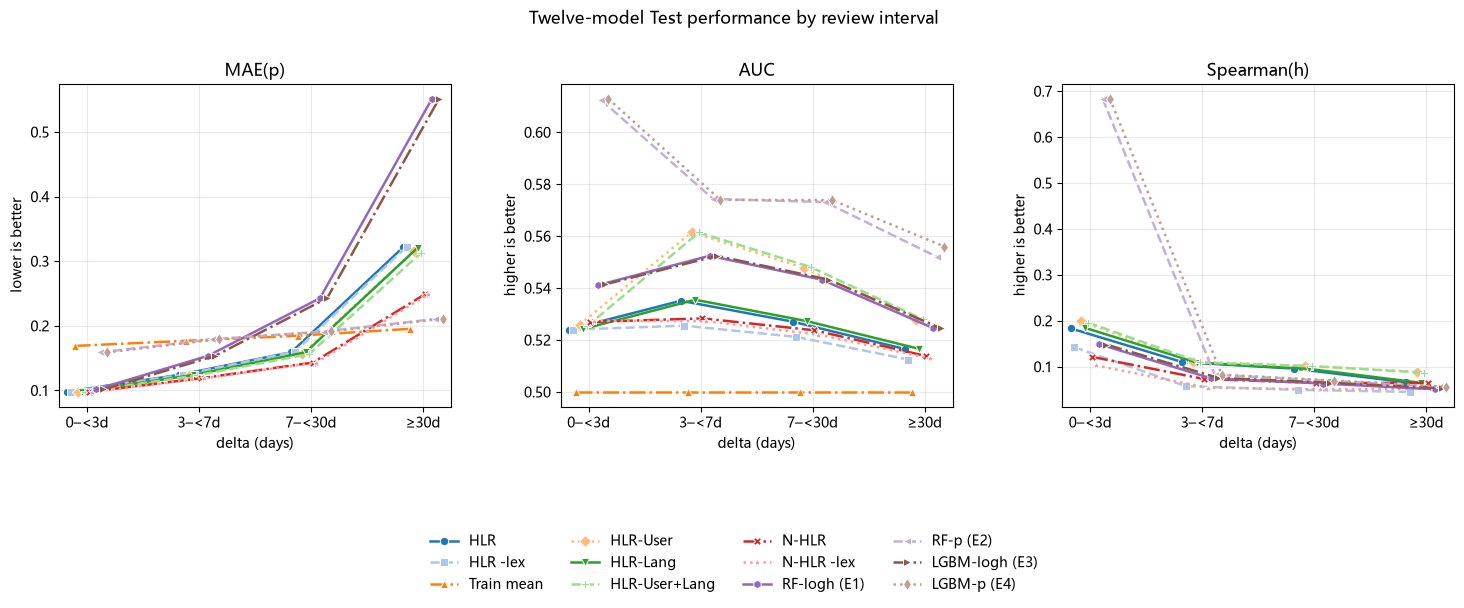

In [55]:
import matplotlib.pyplot as plt

delta_model_order = model_order  # 第 8 节的十二个模型，顺序保持一致
labels = ["[0, 3) 天", "[3, 7) 天", "[7, 30) 天", "[30, +∞) 天"]
test_group_ids = np.searchsorted(np.array([3.0, 7.0, 30.0]),
                                 test_days, side="right")
test_delta_rows = []
for name in delta_model_order:
    p_pred, h_pred = test_predictions[name]
    for group_id, label in enumerate(labels):
        mask = test_group_ids == group_id
        test_delta_rows.append({
            "model": name, "delta 区间": label, "rows": int(mask.sum()),
            "MAE(p)": float(np.abs(p_pred[mask] - test_true_p[mask]).mean()),
            "AUC": auc_fixed(np.rint(test_true_p[mask]), p_pred[mask]),
            "Spearman(h)": (np.nan if name == "Train mean" else
                             spearman_with_ties(test_true_h[mask], h_pred[mask])),
        })
final_test_delta = pd.DataFrame(test_delta_rows)
for name in delta_model_order:
    part = final_test_delta[final_test_delta["model"] == name]
    overall = float(final_summary.loc[
        (final_summary["model"] == name) & (final_summary["split"] == "Test"),
        "MAE(p)",
    ].iloc[0])
    assert part["rows"].sum() == n_test
    assert np.isclose(np.average(part["MAE(p)"], weights=part["rows"]), overall)


delta_order = ["[0, 3) 天", "[3, 7) 天", "[7, 30) 天", "[30, +∞) 天"]
delta_counts = (final_test_delta[final_test_delta["model"] == "HLR"]
                .set_index("delta 区间").loc[delta_order, "rows"])
print("Test 各 delta 区间的样本数；十二个模型共用这些行。")
display(delta_counts.rename("rows").to_frame())

delta_matrices = {}
for metric in ("MAE(p)", "AUC", "Spearman(h)"):
    matrix = (final_test_delta.pivot(index="model", columns="delta 区间",
                                     values=metric)
              .loc[delta_model_order, delta_order])
    assert matrix.shape == (12, 4)
    if metric == "Spearman(h)":
        assert matrix.loc["Train mean"].isna().all()
        assert np.isfinite(matrix.drop(index="Train mean").to_numpy()).all()
    else:
        assert np.isfinite(matrix.to_numpy()).all()
    delta_matrices[metric] = matrix
    print(f"Test {metric}：逐行比较十二个模型；逐列比较同一复习间隔。")
    display(matrix.round(6))

plot_labels = ["0–<3d", "3–<7d", "7–<30d", "≥30d"]
colors = plt.get_cmap("tab20").colors
markers = ["o", "s", "^", "D", "v", "P", "X", "*", "h", "<", ">", "d"]
line_styles = ["-", "--", "-.", ":", "-", "--", "-.", ":", "-", "--", "-.", ":"]
x_centers = np.arange(4)
fig, axes = plt.subplots(1, 3, figsize=(18, 6.2), sharex=True)
for model_index, model_name in enumerate(delta_model_order):
    # 只横向错开绘图位置；每个点的 y 值仍是表中的真实指标。
    x_positions = x_centers + (model_index - 5.5) * 0.032
    for ax, metric in zip(axes, ("MAE(p)", "AUC", "Spearman(h)")):
        if model_name == "Train mean" and metric == "Spearman(h)":
            continue
        ax.plot(x_positions, delta_matrices[metric].loc[model_name].to_numpy(),
                marker=markers[model_index], linestyle=line_styles[model_index],
                linewidth=1.8, markersize=6, markeredgecolor="white",
                markeredgewidth=0.7, color=colors[model_index],
                label=model_name)
for ax, metric in zip(axes, ("MAE(p)", "AUC", "Spearman(h)")):
    ax.set_title(metric)
    ax.set_xticks(x_centers, plot_labels)
    ax.set_xlim(-0.25, 3.25)
    ax.set_xlabel("delta (days)")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("lower is better")
axes[1].set_ylabel("higher is better")
axes[2].set_ylabel("higher is better")
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="lower center", ncol=4,
           bbox_to_anchor=(0.5, 0.02), frameon=False)
fig.suptitle('Twelve-model Test performance by review interval')
fig.subplots_adjust(bottom=0.34, wspace=0.28, top=0.86)
plt.show()


# 08 · N-HLR 非线性结构消融实验

[English](../../08_nonlinearity_ablation.ipynb) · 简体中文

本实验检验 N-HLR 的 MAE 改善是否来自从基础特征到 $\log_2 \hat h$ 的非线性映射。所有实验统一使用 **-lex** 输入，即 `x_correct`、`x_wrong` 和 bias，不使用词元特征。

比较三个模型：

1. **原始 HLR -lex**：保留原项目的线性模型和训练结果，仅作为参考。
2. **Aligned-Linear-HLR -lex**：仍为线性输出，但采用与 N-HLR 完全一致的损失、Adam、batch、训练轮数、梯度裁剪和 Validation 选模。
3. **N-HLR -lex**：四个 ReLU 隐藏单元，采用同一套训练规则。

Aligned-Linear 与 N-HLR 从同一组 HLR -lex 权重开始，并使用三个配对随机种子。核心比较是后两者；Test 只在每个种子通过 Validation 选定 epoch 后评价。


In [56]:
# Locate shared data and modules when running from a subdirectory.
from pathlib import Path
import os
import sys

_notebook_start = Path.cwd().resolve()
_notebook_parents = (_notebook_start, *_notebook_start.parents)
_project_root = next(
    (p for p in _notebook_parents
     if (p / "data/raw/settles.acl16.learning_traces.13m.csv.gz").is_file()),
    None,
)
if _project_root is None:
    _project_root = next(
        (p for p in _notebook_parents if (p / "experiment_pipeline.py").is_file()),
        _notebook_start,
    )
os.chdir(_project_root)
if str(_project_root) not in sys.path:
    sys.path.insert(0, str(_project_root))

from pathlib import Path
import os
import time
import joblib
import matplotlib.pyplot as plt
from IPython.display import display

# All required implementation code is included in this notebook.

# Execute the stages in order in this kernel.
# The inline cells above have completed this stage.

assert len(hlr_lexless_weights) == 3
SEEDS = (42, 43, 44)
HIDDEN = 4
BATCH_SIZE = 8192
EPOCHS_MATCHED = 5
LEARNING_RATE_MATCHED = 1e-4
H_WEIGHT_MATCHED = 1e-4
L2_MATCHED = 1e-6
CLIP_NORM = 10.0
EVAL_BATCH = 200_000
EXPERIMENT_VERSION = 1
CACHE_PATH = Path('data/artifacts/nonlinearity_ablation_lexless_v1.joblib')

experiment_meta = {
    'version': EXPERIMENT_VERSION,
    'source_sha256': source_sha256,
    'n_rows': int(n_rows),
    'train_end': int(train_end),
    'test_start': int(test_start),
    'seeds': SEEDS,
    'hidden': HIDDEN,
    'batch_size': BATCH_SIZE,
    'epochs': EPOCHS_MATCHED,
    'learning_rate': LEARNING_RATE_MATCHED,
    'h_weight': H_WEIGHT_MATCHED,
    'l2': L2_MATCHED,
    'clip_norm': CLIP_NORM,
    'numpy': np.__version__,
    'pandas': pd.__version__,
}
display(pd.Series(experiment_meta, name='value').to_frame())


,value
version,1
source_sha256,ea2648bd3cc3da615a9df760a30cd350edef4459d77070...
n_rows,12854145
train_end,9254984
test_start,11568730
seeds,"(42, 43, 44)"
hidden,4
batch_size,8192
epochs,5
learning_rate,0.0001


## 对齐后的模型

两种对齐模型都最小化

$$\operatorname{MSE}(p,\hat p)+10^{-4}\operatorname{MSE}(\log_2h, z)+10^{-6}L_2,$$

其中 $z=\log_2\hat h$，再通过 $\hat h=2^z$ 和 $\hat p=2^{-\Delta/\hat h}$ 得到预测。区别仅在于 $z$ 是直接线性输出，还是四个 ReLU 隐藏单元的输出。


In [57]:
def base_matrix(batch):
    return np.column_stack((
        batch['x_correct'], batch['x_wrong'],
        np.ones(len(batch), dtype=np.float64),
    ))


def predictions_from_score(score, days):
    score = np.clip(score, LOG_MIN_H, LOG_MAX_H)
    h_pred = np.clip(np.exp2(score), MIN_H, MAX_H)
    p_pred = np.clip(np.exp2(-days / h_pred), MIN_P, MAX_P)
    return score, h_pred, p_pred


class AlignedLinearHLR:
    name = 'Aligned-Linear-HLR -lex'

    def __init__(self, linear_weights, seed=None):
        self.beta = np.asarray(linear_weights, dtype=np.float64).copy()

    def parameters(self):
        return [self.beta]

    def state(self):
        return (self.beta.copy(),)

    def restore(self, state):
        self.beta[:] = state[0]

    def forward(self, batch):
        base = base_matrix(batch)
        score, h_pred, p_pred = predictions_from_score(
            base @ self.beta, batch['delta_days']
        )
        return {'base': base, 'score': score, 'h_pred': h_pred, 'p_pred': p_pred}

    def gradients(self, batch, cache, grad_score):
        grad_beta = cache['base'].T @ grad_score + 2.0 * L2_MATCHED * self.beta
        return [grad_beta]

    def predict(self, batch):
        cache = self.forward(batch)
        return cache['p_pred'], cache['h_pred']


class FourReLUHLR:
    name = 'N-HLR -lex'

    def __init__(self, linear_weights, seed):
        linear_weights = np.asarray(linear_weights, dtype=np.float64)
        self.w1 = np.zeros((3, HIDDEN), dtype=np.float64)
        self.w1[:, 0] = linear_weights
        self.w1[:, 1] = -linear_weights
        self.w1[:, 2:] = np.random.default_rng(seed).normal(0.0, 0.01, size=(3, 2))
        self.w1[2, 2:] = 0.1
        self.w2 = np.array([1.0, -1.0, 0.0, 0.0], dtype=np.float64)
        self.b2 = np.zeros(1, dtype=np.float64)

    def parameters(self):
        return [self.w1, self.w2, self.b2]

    def state(self):
        return self.w1.copy(), self.w2.copy(), self.b2.copy()

    def restore(self, state):
        self.w1[:], self.w2[:], self.b2[:] = state

    def forward(self, batch):
        base = base_matrix(batch)
        pre = base @ self.w1
        hidden = np.maximum(pre, 0.0)
        score, h_pred, p_pred = predictions_from_score(
            hidden @ self.w2 + self.b2[0], batch['delta_days']
        )
        return {
            'base': base, 'pre': pre, 'hidden': hidden,
            'score': score, 'h_pred': h_pred, 'p_pred': p_pred,
        }

    def gradients(self, batch, cache, grad_score):
        grad_w2 = cache['hidden'].T @ grad_score + 2.0 * L2_MATCHED * self.w2
        grad_b2 = np.array([grad_score.sum()], dtype=np.float64)
        grad_hidden = (
            grad_score[:, None] * self.w2[None, :] * (cache['pre'] > 0)
        )
        grad_w1 = cache['base'].T @ grad_hidden + 2.0 * L2_MATCHED * self.w1
        return [grad_w1, grad_w2, grad_b2]

    def predict(self, batch):
        cache = self.forward(batch)
        return cache['p_pred'], cache['h_pred']


# 两种模型在训练前都必须精确复现原始 HLR -lex。
identity_batch = records[splits['Validation'][0]:splits['Validation'][0] + 10_000]
identity_linear = AlignedLinearHLR(hlr_lexless_weights)
identity_neural = FourReLUHLR(hlr_lexless_weights, SEEDS[0])
identity_p_linear, identity_h_linear = identity_linear.predict(identity_batch)
identity_p_neural, identity_h_neural = identity_neural.predict(identity_batch)
initial_p_max_error = float(np.max(np.abs(identity_p_linear - identity_p_neural)))
initial_h_max_error = float(np.max(np.abs(identity_h_linear - identity_h_neural)))
assert initial_p_max_error < 1e-12
assert initial_h_max_error < 1e-12
print(
    'Initialization check passed within floating-point tolerance; '
    f'max |Δp|={initial_p_max_error:.3g}, max |Δh|={initial_h_max_error:.3g}.'
)


Initialization check passed within floating-point tolerance; max |Δp|=1.11e-16, max |Δh|=8.53e-14.


In [58]:
def adam_update(param, grad, state, step):
    m, v = state
    m *= 0.9
    m += 0.1 * grad
    v *= 0.999
    v += 0.001 * np.square(grad)
    param -= LEARNING_RATE_MATCHED * (m / (1.0 - 0.9 ** step)) / (
        np.sqrt(v / (1.0 - 0.999 ** step)) + 1e-8
    )


def matched_train_step(model, batch, adam_states, step):
    cache = model.forward(batch)
    grad_score = (2.0 / len(batch)) * (
        (cache['p_pred'] - batch['p_target'])
        * cache['p_pred'] * (np.log(2.0) ** 2)
        * (batch['delta_days'] / cache['h_pred'])
        + H_WEIGHT_MATCHED
        * (cache['score'] - np.log2(batch['h_observed']))
    )
    gradients = model.gradients(batch, cache, grad_score)
    norm = np.sqrt(sum(float(np.sum(grad ** 2)) for grad in gradients))
    if norm > CLIP_NORM:
        factor = CLIP_NORM / norm
        gradients = [grad * factor for grad in gradients]
    for parameter, gradient, state in zip(model.parameters(), gradients, adam_states):
        adam_update(parameter, gradient, state, step)


def basic_metrics(model, split_name):
    start, stop = splits[split_name]
    abs_sum = sq_sum = h_abs_sum = 0.0
    for left in range(start, stop, EVAL_BATCH):
        right = min(left + EVAL_BATCH, stop)
        batch = records[left:right]
        p_pred, h_pred = model.predict(batch)
        error = p_pred - batch['p_target']
        abs_sum += float(np.abs(error).sum())
        sq_sum += float(np.dot(error, error))
        h_abs_sum += float(np.abs(h_pred - batch['h_observed']).sum())
    n = stop - start
    return {
        'n_eval': n, 'MAE(p)': abs_sum / n, 'RMSE(p)': np.sqrt(sq_sum / n),
        'MAE(h)_days': h_abs_sum / n,
    }


def detailed_metrics(model, split_name):
    start, stop = splits[split_name]
    p_true = records['p_target'][start:stop]
    h_true = records['h_observed'][start:stop]
    p_pred = np.empty(stop - start, dtype=np.float64)
    h_pred = np.empty(stop - start, dtype=np.float64)
    for left in range(start, stop, EVAL_BATCH):
        right = min(left + EVAL_BATCH, stop)
        p_batch, h_batch = model.predict(records[left:right])
        p_pred[left-start:right-start] = p_batch
        h_pred[left-start:right-start] = h_batch
    error = p_pred - p_true
    return {
        'split': split_name, 'n_eval': stop - start,
        'MAE(p)': float(np.abs(error).mean()),
        'RMSE(p)': float(np.sqrt(np.dot(error, error) / len(error))),
        'AUC': auc_fixed(np.rint(p_true), p_pred),
        'Spearman(h)': spearman_with_ties(h_true, h_pred),
        'mean_prediction': float(p_pred.mean()),
        'share_at_upper_bound': float(np.mean(p_pred == MAX_P)),
    }


def fit_matched_model(model_class, seed):
    model = model_class(hlr_lexless_weights, seed)
    initial = basic_metrics(model, 'Validation')
    trace = [{'epoch': 0, **initial}]
    best_mae = initial['MAE(p)']
    best_epoch = 0
    best_state = model.state()
    parameters = model.parameters()
    adam_states = [(np.zeros_like(p), np.zeros_like(p)) for p in parameters]
    order = np.arange(train_end, dtype=np.int32)
    rng = np.random.default_rng(seed + 10)
    step = 0
    started = time.perf_counter()
    for epoch in range(1, EPOCHS_MATCHED + 1):
        rng.shuffle(order)
        for left in range(0, train_end, BATCH_SIZE):
            rows = order[left:min(left + BATCH_SIZE, train_end)]
            step += 1
            matched_train_step(model, records[rows], adam_states, step)
        metrics = basic_metrics(model, 'Validation')
        trace.append({'epoch': epoch, **metrics})
        print(
            f'{model.name}; seed={seed}; epoch={epoch}; '
            f"Validation MAE={metrics['MAE(p)']:.6f}"
        )
        if metrics['MAE(p)'] < best_mae:
            best_mae = metrics['MAE(p)']
            best_epoch = epoch
            best_state = model.state()
    model.restore(best_state)
    elapsed = time.perf_counter() - started
    return model, pd.DataFrame(trace), {
        'selected_epoch': best_epoch, 'fit_seconds': elapsed,
    }


## 运行三个配对种子

首次运行需要完整训练六个模型（2 种结构 × 3 个种子），耗时可能较长。每完成一个模型都会写入缓存；中断后重新运行可从尚未完成的组合继续。缓存身份包含数据摘要、切分、依赖版本和全部实验超参数。


In [59]:
CACHE_PATH.parent.mkdir(parents=True, exist_ok=True)
if CACHE_PATH.is_file():
    cached = joblib.load(CACHE_PATH)
    if cached.get('meta') != experiment_meta:
        print('Existing cache does not match this experiment; starting a new result set.')
        cached = {'meta': experiment_meta, 'runs': {}}
else:
    cached = {'meta': experiment_meta, 'runs': {}}


def save_cache(payload):
    partial = CACHE_PATH.with_suffix('.partial')
    joblib.dump(payload, partial, compress=3)
    os.replace(partial, CACHE_PATH)


for seed in SEEDS:
    for model_class in (AlignedLinearHLR, FourReLUHLR):
        key = (model_class.name, seed)
        if key in cached['runs']:
            print(f'Loaded cached run: {key}')
            continue
        model, trace, resource = fit_matched_model(model_class, seed)
        rows = []
        for split_name in ('Validation', 'Test'):
            rows.append({
                'model': model.name, 'seed': seed,
                'selected_epoch': resource['selected_epoch'],
                'fit_seconds': resource['fit_seconds'],
                **detailed_metrics(model, split_name),
            })
        cached['runs'][key] = {
            'state': model.state(),
            'trace': trace.to_dict(orient='records'),
            'metrics': rows,
        }
        save_cache(cached)
        print(f'Saved completed run: {key}')

run_rows = [
    row
    for result in cached['runs'].values()
    for row in result['metrics']
]
seed_results = pd.DataFrame(run_rows).sort_values(['split', 'seed', 'model'])
trace_results = pd.concat([
    pd.DataFrame(result['trace']).assign(model=key[0], seed=key[1])
    for key, result in cached['runs'].items()
], ignore_index=True)

reference_model = AlignedLinearHLR(hlr_lexless_weights)
hlr_reference = pd.DataFrame([
    {'model': 'Original HLR -lex', 'seed': np.nan, **detailed_metrics(reference_model, split_name)}
    for split_name in ('Validation', 'Test')
])
display(hlr_reference.round(6))
display(seed_results.round(6))
print(f'Cache: {CACHE_PATH.resolve()}')


Loaded cached run: ('Aligned-Linear-HLR -lex', 42)
Loaded cached run: ('N-HLR -lex', 42)
Loaded cached run: ('Aligned-Linear-HLR -lex', 43)
Loaded cached run: ('N-HLR -lex', 43)
Loaded cached run: ('Aligned-Linear-HLR -lex', 44)
Loaded cached run: ('N-HLR -lex', 44)


,model,seed,split,n_eval,MAE(p),RMSE(p),AUC,Spearman(h),mean_prediction,share_at_upper_bound
0,Original HLR -lex,NaN,Validation,2313746,0.126217,0.290753,0.535436,0.162334,0.965776,0.353260
1,Original HLR -lex,NaN,Test,1285415,0.128283,0.290873,0.537459,0.160552,0.962699,0.345543


,model,seed,selected_epoch,fit_seconds,split,n_eval,MAE(p),RMSE(p),AUC,Spearman(h),mean_prediction,share_at_upper_bound
1,Aligned-Linear-HLR -lex,42,5,8.786174,Test,1285415,0.119925,0.287830,0.535192,-0.041136,0.975222,0.369251
3,N-HLR -lex,42,5,9.850683,Test,1285415,0.118909,0.287335,0.540314,0.126451,0.976555,0.366341
5,Aligned-Linear-HLR -lex,43,5,8.922807,Test,1285415,0.119902,0.287825,0.535175,-0.041755,0.975257,0.369312
7,N-HLR -lex,43,5,9.802252,Test,1285415,0.118952,0.287329,0.540619,0.126448,0.976459,0.366102
9,Aligned-Linear-HLR -lex,44,5,8.724737,Test,1285415,0.119893,0.287823,0.535174,-0.041782,0.975270,0.369338
11,N-HLR -lex,44,4,9.758867,Test,1285415,0.118847,0.287398,0.539675,0.122337,0.976689,0.367889
0,Aligned-Linear-HLR -lex,42,5,8.786174,Validation,2313746,0.118438,0.288357,0.532175,-0.036764,0.977385,0.378265
2,N-HLR -lex,42,5,9.850683,Validation,2313746,0.117471,0.287850,0.540292,0.127927,0.978515,0.374189
4,Aligned-Linear-HLR -lex,43,5,8.922807,Validation,2313746,0.118417,0.288353,0.532150,-0.037413,0.977418,0.378327
6,N-HLR -lex,43,5,9.802252,Validation,2313746,0.117505,0.287826,0.540748,0.127929,0.978413,0.373964


Cache: D:\fujing123\Projects\Data-Analytic\HLR\data\artifacts\nonlinearity_ablation_lexless_v1.joblib


MAE(p)             RMSE(p)                 AUC  \
                             mean       std      mean       std      mean   
model                                                                       
Aligned-Linear-HLR -lex  0.119907  0.000016  0.287826  0.000004  0.535181   
N-HLR -lex               0.118903  0.000053  0.287354  0.000038  0.540203   

                                  Spearman(h)           mean_prediction  \
                              std        mean       std            mean   
model                                                                     
Aligned-Linear-HLR -lex  0.000010   -0.041558  0.000365        0.975250   
N-HLR -lex               0.000482    0.125079  0.002374        0.976568   

                                  share_at_upper_bound            
                              std                 mean       std  
model                                                             
Aligned-Linear-HLR -lex  0.000025             0.369300  0.000044  
N-HLR -lex               0.000116             0.366777  0.000970

model,seed,Aligned-Linear-HLR -lex,N-HLR -lex,MAE gain from nonlinearity
0,42,0.119925,0.118909,0.001016
1,43,0.119902,0.118952,0.000950
2,44,0.119893,0.118847,0.001047


Mean paired Test MAE gain (positive favors N-HLR): 0.001004


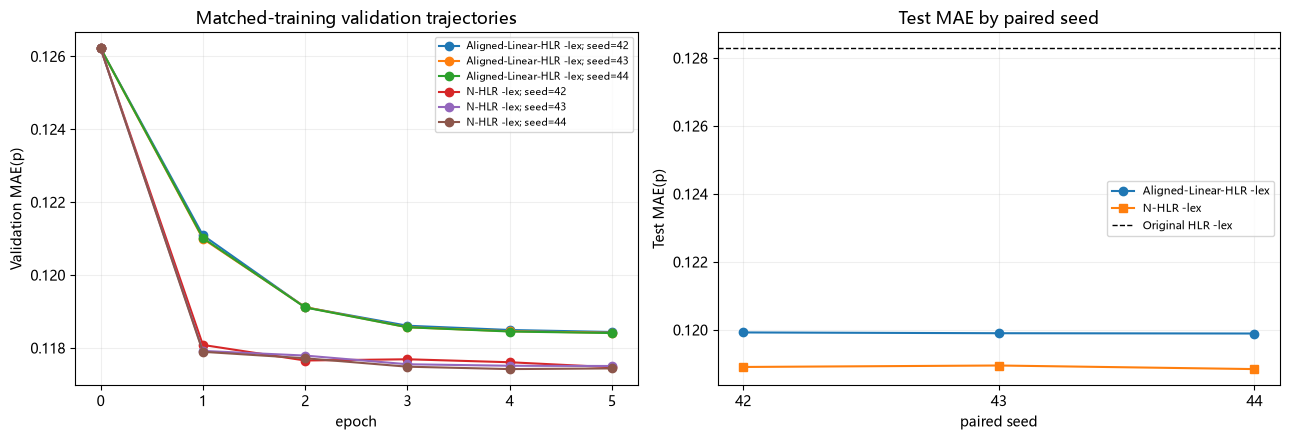

In [60]:
test_seed_results = seed_results[seed_results['split'] == 'Test'].copy()
metric_columns = ['MAE(p)', 'RMSE(p)', 'AUC', 'Spearman(h)', 'mean_prediction', 'share_at_upper_bound']
aggregate = test_seed_results.groupby('model')[metric_columns].agg(['mean', 'std'])
display(aggregate.round(6))

paired = (
    test_seed_results.pivot(index='seed', columns='model', values='MAE(p)')
    .reset_index()
)
paired['MAE gain from nonlinearity'] = (
    paired['Aligned-Linear-HLR -lex'] - paired['N-HLR -lex']
)
display(paired.round(6))
print(
    'Mean paired Test MAE gain (positive favors N-HLR): '
    f"{paired['MAE gain from nonlinearity'].mean():.6f}"
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for (model_name, seed), part in trace_results.groupby(['model', 'seed']):
    axes[0].plot(part['epoch'], part['MAE(p)'], marker='o', label=f'{model_name}; seed={seed}')
axes[0].set(
    xlabel='epoch', ylabel='Validation MAE(p)',
    title='Matched-training validation trajectories',
)
axes[0].grid(alpha=0.2)
axes[0].legend(fontsize=7)

for model_name, marker in [('Aligned-Linear-HLR -lex', 'o'), ('N-HLR -lex', 's')]:
    part = test_seed_results[test_seed_results['model'] == model_name]
    axes[1].plot(part['seed'], part['MAE(p)'], marker=marker, linewidth=1.5, label=model_name)
axes[1].axhline(
    hlr_reference.loc[hlr_reference['split'] == 'Test', 'MAE(p)'].iloc[0],
    color='black', linestyle='--', linewidth=1, label='Original HLR -lex',
)
axes[1].set(
    xlabel='paired seed', ylabel='Test MAE(p)',
    title='Test MAE by paired seed', xticks=list(SEEDS),
)
axes[1].grid(alpha=0.2)
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()


## 解释规则与实验限制

- 若 Aligned-Linear 与 N-HLR 的结果接近，而两者都优于原始 HLR，则改善主要来自损失与训练方式。
- 若 Aligned-Linear 接近原始 HLR，而 N-HLR 在三个配对种子下都更好，则结果支持非线性结构带来改善。
- 若 Aligned-Linear 介于两者之间，则训练方式与非线性结构都有贡献。

**实验限制——正则化不可完全等价。** Aligned-Linear 的参数是单个系数向量，而 N-HLR 使用两层参数 $W_1,W_2,b_2$。即使二者采用相同的 `L2=1e-6`，两层网络可以在层间重新缩放参数，因此相同的 L2 系数不代表完全相同的函数级约束。本实验将优化器、损失权重和名义 L2 系数保持一致，但不能把剩余差异严格解释为纯粹的函数非线性。

此外，三个随机种子只能用于检查结果是否在少量重复实验中方向一致，不足以支持正式的统计显著性结论。由于 Test 标签大量位于回忆率上界，解释 MAE 时还应同时查看 RMSE、预测均值和上界预测比例。


# 09 · Test 标签与模型预测分布及 MAE–RMSE 误差分析

[English](../../09_mae_rmse_analysis.ipynb) · 简体中文

本 notebook 重新设计 08 中实验 A 的分布图，目的是更直接地展示：**HLR 系模型的大部分预测非常高，而直接预测回忆率的树模型输出更保守。**

第一张图沿用 EDA 的 20 个等宽区间，分别画出 Test 标签、HLR 和 RF-p 的棒形直方图，避免多条阶梯线互相遮挡。第二张图比较所有系列中 `p ≥ 0.95` 的记录占比，用一个数字概括高位集中的程度。N-HLR 和 LGBM-p 保留在汇总表和第二张图中。

本 notebook 不重新训练模型；已有统一比较缓存时直接读取。


In [61]:
# Locate shared data and modules when running from a subdirectory.
from pathlib import Path
import os
import sys

_notebook_start = Path.cwd().resolve()
_notebook_parents = (_notebook_start, *_notebook_start.parents)
_project_root = next(
    (p for p in _notebook_parents
     if (p / "data/raw/settles.acl16.learning_traces.13m.csv.gz").is_file()),
    None,
)
if _project_root is None:
    _project_root = next(
        (p for p in _notebook_parents if (p / "experiment_pipeline.py").is_file()),
        _notebook_start,
    )
os.chdir(_project_root)
if str(_project_root) not in sys.path:
    sys.path.insert(0, str(_project_root))

from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from IPython.display import display

# All required implementation code is included in this notebook.

# Execute the stages in order in this kernel.
# The inline cells above have completed this stage.

REPORTS_DIR = Path('reports')
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
SMALL_MULTIPLES_PATH = REPORTS_DIR / 's09_prediction_distribution_bars.png'
HIGH_SHARE_PATH = REPORTS_DIR / 's09_high_prediction_share.png'

distribution_series = {
    'p_target (true)': np.asarray(test_true_p, dtype=np.float64),
    'HLR': np.asarray(test_predictions['HLR'][0], dtype=np.float64),
    'N-HLR': np.asarray(test_predictions['N-HLR'][0], dtype=np.float64),
    'RF-p': np.asarray(test_predictions['RF-p (E2)'][0], dtype=np.float64),
    'LGBM-p': np.asarray(test_predictions['LGBM-p (E4)'][0], dtype=np.float64),
}
n_test_distribution = len(distribution_series['p_target (true)'])
assert all(len(values) == n_test_distribution for values in distribution_series.values())
assert all(np.isfinite(values).all() for values in distribution_series.values())
assert all(np.all((MIN_P <= values) & (values <= MAX_P))
           for values in distribution_series.values())
print(f'Test rows: {n_test_distribution:,}')


Test rows: 1,285,415


## 9.1 分布统计

表格保留均值、标准差、分位数和边界占比。图形用于快速传达主要模式，精确比较仍以表格为准。


In [62]:
distribution_rows = []
for name, values in distribution_series.items():
    p10, p50, p90 = np.quantile(values, [0.10, 0.50, 0.90])
    distribution_rows.append({
        'series': name,
        'n_test': len(values),
        'mean': float(values.mean()),
        'std': float(values.std()),
        'P10': float(p10),
        'P50': float(p50),
        'P90': float(p90),
        'share_ge_0.95': float(np.mean(values >= 0.95)),
        'share_at_MIN_P': float(np.mean(values == MIN_P)),
        'share_at_MAX_P': float(np.mean(values == MAX_P)),
    })
distribution_summary = pd.DataFrame(distribution_rows)
display(distribution_summary.round(6))


,series,n_test,mean,std,P10,P50,P90,share_ge_0.95,share_at_MIN_P,share_at_MAX_P
0,p_target (true),1285415,0.895429,0.271137,0.500000,0.999900,0.999900,0.836041,0.070233,0.836030
1,HLR,1285415,0.962835,0.091981,0.903317,0.995612,0.999900,0.829599,0.000000,0.345267
2,N-HLR,1285415,0.976572,0.061257,0.941167,0.997467,0.999900,0.886834,0.000000,0.366044
3,RF-p,1285415,0.894972,0.044565,0.855217,0.902198,0.934825,0.021230,0.000000,0.000010
4,LGBM-p,1285415,0.894965,0.044095,0.855804,0.902438,0.935212,0.017517,0.000000,0.000019


## 9.2 与 EDA 对照的 20-bin 棒形直方图

三张图使用相同的 `[0,1]` 横轴和 20 个等宽区间。每根柱表示该系列落入相应区间的 Test 行占比。为了让每个分布的形状都清楚可见，三个面板分别调整纵轴范围，因此**不应根据柱子的绝对高度跨面板比较占比**；跨系列的精确占比见上一张表和下一张图。


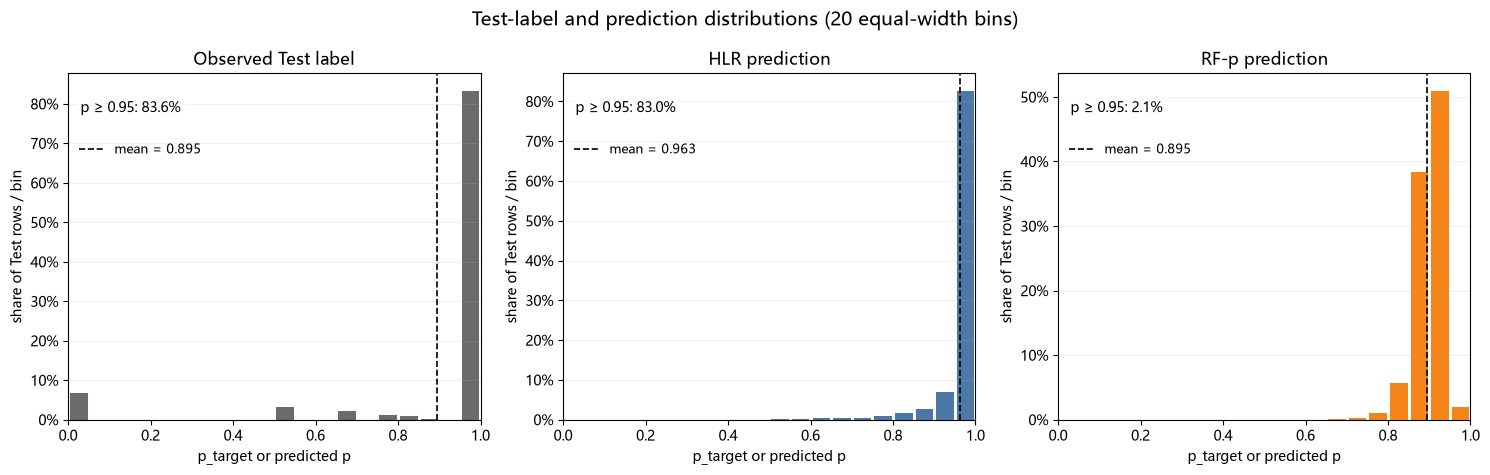

Saved: D:\fujing123\Projects\Data-Analytic\HLR\reports\s09_prediction_distribution_bars.png


In [63]:
histogram_names = ['p_target (true)', 'HLR', 'RF-p']
histogram_titles = {
    'p_target (true)': 'Observed Test label',
    'HLR': 'HLR prediction',
    'RF-p': 'RF-p prediction',
}
histogram_colors = {
    'p_target (true)': '#6B6B6B',
    'HLR': '#4C78A8',
    'RF-p': '#F58518',
}
histogram_edges = np.linspace(0.0, 1.0, 21)
histogram_centers = (histogram_edges[:-1] + histogram_edges[1:]) / 2
histogram_width = 0.9 * np.diff(histogram_edges)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharex=True)
for ax, name in zip(axes, histogram_names):
    values = distribution_series[name]
    masses = np.histogram(values, bins=histogram_edges)[0] / len(values)
    ax.bar(
        histogram_centers, masses, width=histogram_width,
        color=histogram_colors[name], edgecolor='white', linewidth=0.7,
    )
    mean_value = float(values.mean())
    share_high = float(np.mean(values >= 0.95))
    ax.axvline(
        mean_value, color='black', linestyle='--', linewidth=1.2,
        label=f'mean = {mean_value:.3f}',
    )
    ax.text(
        0.03, 0.92, f'p ≥ 0.95: {share_high:.1%}',
        transform=ax.transAxes, ha='left', va='top', fontsize=10,
        bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.85},
    )
    ax.set(
        title=histogram_titles[name], xlim=(0, 1),
        xlabel='p_target or predicted p', ylabel='share of Test rows / bin',
    )
    ax.set_xticks(np.linspace(0, 1, 6))
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0))
    ax.grid(axis='y', alpha=0.2)
    ax.legend(loc='upper left', bbox_to_anchor=(0, 0.83), frameon=False, fontsize=9)
fig.suptitle(
    'Test-label and prediction distributions (20 equal-width bins)',
    fontsize=14,
)
fig.tight_layout()
fig.savefig(SMALL_MULTIPLES_PATH, dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved: {SMALL_MULTIPLES_PATH.resolve()}')


## 9.3 极高预测占比

下面直接比较每个系列中 `p ≥ 0.95` 的行占比。该图不替代完整分布，而是将“模型是否经常给出极高回忆率”这一观点压缩成一个容易比较的量。


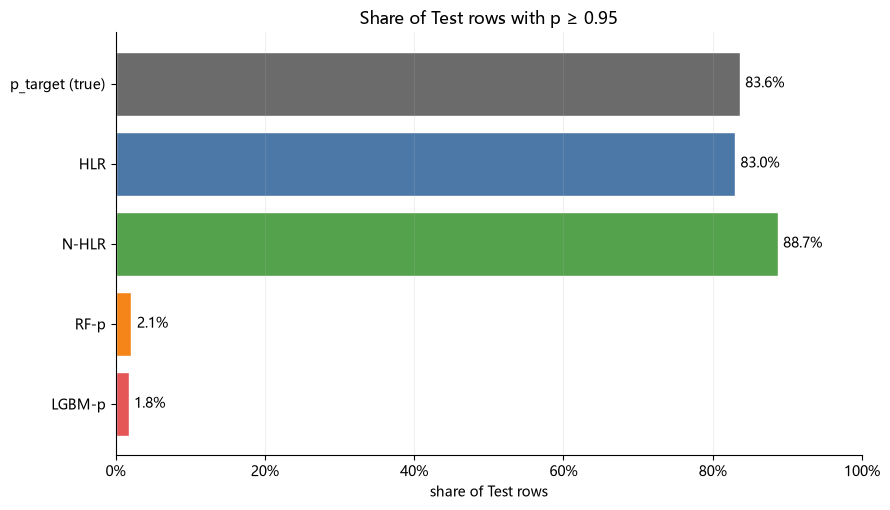

,share_ge_0.95
series,
p_target (true),0.836041
HLR,0.829599
N-HLR,0.886834
RF-p,0.021230
LGBM-p,0.017517


Saved: D:\fujing123\Projects\Data-Analytic\HLR\reports\s09_high_prediction_share.png


In [64]:
high_share = (
    distribution_summary.set_index('series')
    .loc[list(distribution_series), 'share_ge_0.95']
)
high_share_colors = ['#6B6B6B', '#4C78A8', '#54A24B', '#F58518', '#E45756']

fig, ax = plt.subplots(figsize=(9, 5.2))
bars = ax.barh(
    high_share.index, high_share.to_numpy(),
    color=high_share_colors, edgecolor='white',
)
ax.invert_yaxis()
ax.bar_label(bars, labels=[f'{value:.1%}' for value in high_share], padding=4)
ax.set(
    title='Share of Test rows with p ≥ 0.95',
    xlabel='share of Test rows', xlim=(0, 1),
)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0))
ax.grid(axis='x', alpha=0.2)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(HIGH_SHARE_PATH, dpi=180, bbox_inches='tight')
plt.show()
display(high_share.rename('share_ge_0.95').to_frame().round(6))
print(f'Saved: {HIGH_SHARE_PATH.resolve()}')


## 9.4 读图结论

Test 标签高度集中在回忆率上界。HLR 和 N-HLR 的预测也集中在接近 1 的区域，因此在占 Test 大多数的高回忆率记录上容易获得较低绝对误差。RF-p 和 LGBM-p 的输出则主要集中在较低且更窄的高概率区间，很少给出 `p ≥ 0.95` 的预测，可以称为相对保守。

这里的“保守”只描述预测分布的位置，不等价于整体模型更好或更差。HLR 系模型的高位集中有利于当前数据分布下的 MAE；直接预测回忆率的树模型虽然 MAE 更高，却在 RMSE 和 AUC 上表现更好。模型比较仍需结合逐行误差和其他指标，不能只根据边际分布得出结论。


## 9.5 为什么 MAE 和 RMSE 给出不同的模型排序？

HLR 的 MAE 低于 RF-p，但 RMSE 更高。为了定位排名反转来自哪些记录，下面按照真实 `p_target` 分组，并把每一组对总体 MAE 和总体 MSE 的贡献相加。

对组 $g$，定义

$$C_{\mathrm{MAE},g}=\frac{N_g}{N}\operatorname{MAE}_g,$$

$$C_{\mathrm{MSE},g}=\frac{N_g}{N}\operatorname{MSE}_g.$$

所有 $C_{\mathrm{MAE},g}$ 相加等于总体 MAE；所有 $C_{\mathrm{MSE},g}$ 相加等于总体 MSE，最后对总体 MSE 开平方才得到 RMSE。**RMSE 本身不能按组直接相加**，因此右图展示的是 MSE contribution，并在整根柱末端标出对应 RMSE。


,model,group,n_group,share,MAE_g,MSE_g,C_MAE,C_MSE
0,HLR,p = MIN_P,90279,0.070233,0.951658,0.916788,0.066838,0.064389
1,HLR,MIN_P < p ≤ 0.2,13,0.000010,0.785759,0.618302,0.000008,0.000006
2,HLR,0.2 < p ≤ 0.5,48508,0.037737,0.472692,0.232218,0.017838,0.008763
3,HLR,0.5 < p < MAX_P,71970,0.055990,0.244573,0.067469,0.013694,0.003778
4,HLR,p = MAX_P,1074645,0.836030,0.035472,0.009178,0.029656,0.007673
5,RF-p,p = MIN_P,90279,0.070233,0.872254,0.767085,0.061261,0.053875
6,RF-p,MIN_P < p ≤ 0.2,13,0.000010,0.464523,0.249884,0.000005,0.000003
7,RF-p,0.2 < p ≤ 0.5,48508,0.037737,0.393611,0.159442,0.014854,0.006017
8,RF-p,0.5 < p < MAX_P,71970,0.055990,0.158337,0.031007,0.008865,0.001736
9,RF-p,p = MAX_P,1074645,0.836030,0.101935,0.011885,0.085221,0.009936


,model,MAE,sum_C_MAE,MSE,sum_C_MSE,RMSE
0,HLR,0.128033,0.128033,0.084610,0.084610,0.290877
1,RF-p,0.170206,0.170206,0.071567,0.071567,0.267520


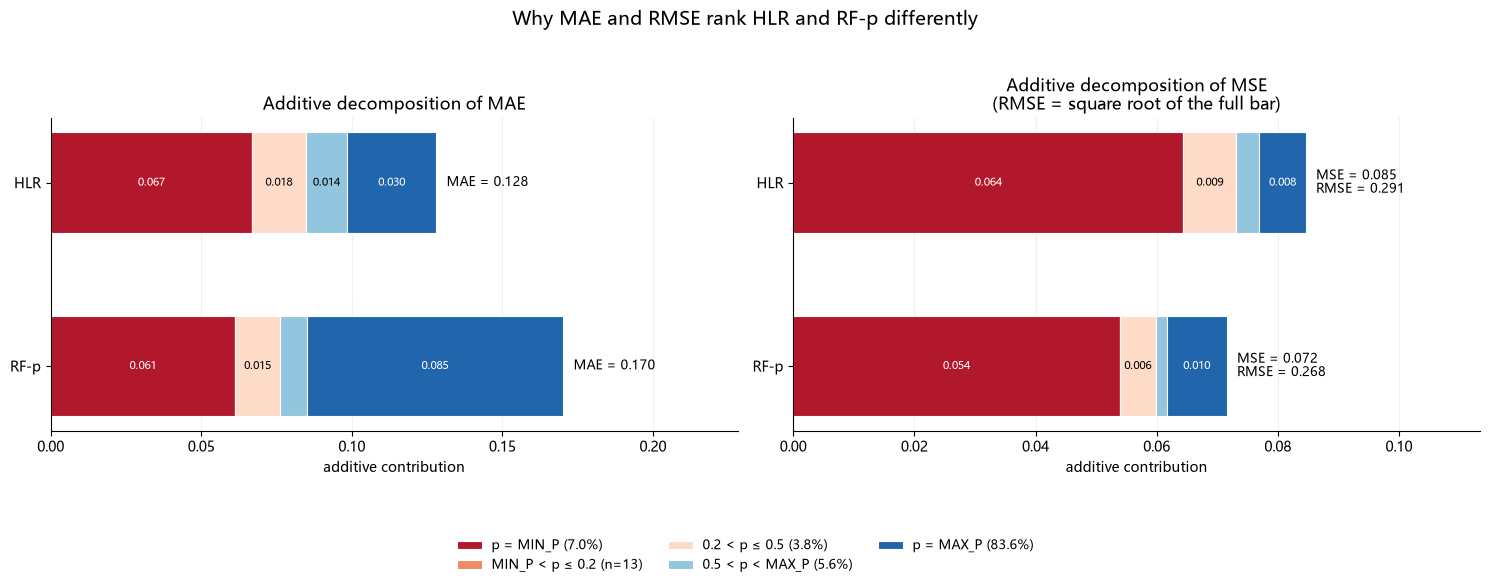

Saved: D:\fujing123\Projects\Data-Analytic\HLR\reports\s09_mae_mse_contribution_stacks.png


In [65]:
DECOMPOSITION_PATH = REPORTS_DIR / 's09_mae_mse_contribution_stacks.png'
decomposition_models = ['HLR', 'RF-p']
decomposition_group_names = [
    'p = MIN_P', 'MIN_P < p ≤ 0.2', '0.2 < p ≤ 0.5',
    '0.5 < p < MAX_P', 'p = MAX_P',
]
true_p = distribution_series['p_target (true)']
decomposition_masks = [
    true_p == MIN_P,
    (true_p > MIN_P) & (true_p <= 0.2),
    (true_p > 0.2) & (true_p <= 0.5),
    (true_p > 0.5) & (true_p < MAX_P),
    true_p == MAX_P,
]
coverage = np.zeros(len(true_p), dtype=np.int8)
for mask in decomposition_masks:
    coverage += mask
assert np.all(coverage == 1), 'p_target groups must cover Test exactly once'

decomposition_rows = []
for model_name in decomposition_models:
    error = distribution_series[model_name] - true_p
    absolute_error = np.abs(error)
    squared_error = error ** 2
    for group_name, mask in zip(decomposition_group_names, decomposition_masks):
        n_group = int(mask.sum())
        decomposition_rows.append({
            'model': model_name,
            'group': group_name,
            'n_group': n_group,
            'share': n_group / len(true_p),
            'MAE_g': float(absolute_error[mask].mean()),
            'MSE_g': float(squared_error[mask].mean()),
            'C_MAE': float(absolute_error[mask].sum() / len(true_p)),
            'C_MSE': float(squared_error[mask].sum() / len(true_p)),
        })

mae_mse_decomposition = pd.DataFrame(decomposition_rows)
decomposition_checks = []
for model_name in decomposition_models:
    part = mae_mse_decomposition[mae_mse_decomposition['model'] == model_name]
    error = distribution_series[model_name] - true_p
    overall_mae = float(np.abs(error).mean())
    overall_mse = float(np.mean(error ** 2))
    assert np.isclose(part['C_MAE'].sum(), overall_mae, rtol=0, atol=1e-12)
    assert np.isclose(part['C_MSE'].sum(), overall_mse, rtol=0, atol=1e-12)
    decomposition_checks.append({
        'model': model_name,
        'MAE': overall_mae,
        'sum_C_MAE': float(part['C_MAE'].sum()),
        'MSE': overall_mse,
        'sum_C_MSE': float(part['C_MSE'].sum()),
        'RMSE': float(np.sqrt(overall_mse)),
    })
decomposition_summary = pd.DataFrame(decomposition_checks)
display(mae_mse_decomposition.round(6))
display(decomposition_summary.round(6))

group_shares = (
    mae_mse_decomposition[mae_mse_decomposition['model'] == decomposition_models[0]]
    .set_index('group')['share']
    .loc[decomposition_group_names]
)
legend_labels = [
    f'{group} ({group_shares[group]:.1%})'
    if group_shares[group] >= 0.001
    else f'{group} (n={int(decomposition_masks[i].sum()):,})'
    for i, group in enumerate(decomposition_group_names)
]
group_colors = ['#B2182B', '#EF8A62', '#FDDBC7', '#92C5DE', '#2166AC']
model_positions = np.arange(len(decomposition_models))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
for ax, metric, title in zip(
    axes,
    ['C_MAE', 'C_MSE'],
    ['Additive decomposition of MAE',
     'Additive decomposition of MSE\n(RMSE = square root of the full bar)'],
):
    left = np.zeros(len(decomposition_models), dtype=np.float64)
    for group_name, legend_label, color in zip(
        decomposition_group_names, legend_labels, group_colors
    ):
        values = np.array([
            mae_mse_decomposition.loc[
                (mae_mse_decomposition['model'] == model_name)
                & (mae_mse_decomposition['group'] == group_name), metric
            ].iloc[0]
            for model_name in decomposition_models
        ])
        bars = ax.barh(
            model_positions, values, left=left, height=0.55,
            color=color, edgecolor='white', linewidth=0.8, label=legend_label,
        )
        threshold = 0.06 * max(
            decomposition_summary['MAE' if metric == 'C_MAE' else 'MSE']
        )
        for bar, value in zip(bars, values):
            if value >= threshold:
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    bar.get_y() + bar.get_height() / 2,
                    f'{value:.3f}', ha='center', va='center', fontsize=8,
                    color='white' if color in ('#B2182B', '#2166AC') else 'black',
                )
        left += values
    totals = decomposition_summary.set_index('model').loc[
        decomposition_models, 'MAE' if metric == 'C_MAE' else 'MSE'
    ].to_numpy()
    rmse_values = decomposition_summary.set_index('model').loc[
        decomposition_models, 'RMSE'
    ].to_numpy()
    x_limit = float(totals.max() * 1.34)
    for y, total, rmse in zip(model_positions, totals, rmse_values):
        label = (
            f'MAE = {total:.3f}'
            if metric == 'C_MAE'
            else f'MSE = {total:.3f}\nRMSE = {rmse:.3f}'
        )
        ax.text(total + 0.015 * x_limit, y, label, va='center', fontsize=9)
    ax.set(
        title=title, yticks=model_positions, yticklabels=decomposition_models,
        xlabel='additive contribution', xlim=(0, x_limit),
    )
    ax.invert_yaxis()
    ax.grid(axis='x', alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc='lower center', ncol=3, frameon=False,
    bbox_to_anchor=(0.5, -0.01), fontsize=9,
)
fig.suptitle('Why MAE and RMSE rank HLR and RF-p differently', fontsize=14)
fig.tight_layout(rect=(0, 0.15, 1, 0.95))
fig.savefig(DECOMPOSITION_PATH, dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved: {DECOMPOSITION_PATH.resolve()}')


## 9.6 结论：高频小误差与低频大误差

`p_target=MAX_P` 的记录占 Test 的 83.603%。在这组数量最多的高回忆率记录上，HLR 的 MAE 很低，因此该组对 HLR 总体 MAE 的贡献只有 0.029656，而对 RF-p 的贡献为 0.085221。这一大样本组使 HLR 获得更低的总体 MAE。

另一方面，`p_target=MIN_P` 的记录占 Test 的 7.023%。HLR 会对其中一部分记录给出非常高的预测，因此产生较大的尾部误差；误差平方后，该组对 HLR 总体 MSE 的贡献达到 0.064389，高于 RF-p 的 0.053875。少量大误差在 MSE 中受到更强惩罚，最终使 HLR 的 RMSE 高于 RF-p。

因此，两个指标的排序并不矛盾：**MAE 更受数量占绝对多数的高回忆率记录影响，RMSE 则更敏感于低回忆率记录上的少量大误差。** HLR 的预测分布与标签的高位集中更接近，所以 MAE 较低；RF-p 的预测更保守，减少了灾难性高估，所以 RMSE 较低。右图展示的是可加的 MSE contribution，而不是可直接相加的 RMSE contribution。


# 10 · Random Forest 与 LightGBM 预测相似性

[English](../../10_rf_lightgbm_similarity.ipynb) · 简体中文

本 notebook 只分析两组树模型在同一批 Test 记录上的逐行预测是否相同：

- E1：RF-logh 与 E3：LGBM-logh；
- E2：RF-p 与 E4：LGBM-p。

比较同时在模型原始输出空间和最终裁剪后的回忆率空间进行，并检查边界裁剪是否放大了表面相似性。这里不再包含 MAE/RMSE 误差分解；该分析已移至 `09_mae_rmse_analysis.ipynb`。

已有模型与统一 Test 预测会从缓存读取，不重新训练。


In [66]:
import numpy as np
import pandas as pd
from IPython.display import display

diag_required = [
    "test_predictions", "records", "splits", "RF_BATCH", "MIN_P", "MAX_P",
    "LOG_MIN_H", "LOG_MAX_H", "rf_x_from_records", "rf_p_x_from_records",
    "rf_e1_model", "rf_e2_model", "lgbm_e3_model", "lgbm_e4_model",
    "spearman_with_ties",
]
diag_missing = [name for name in diag_required if name not in globals()]
if diag_missing:
    raise RuntimeError(
        "Missing variables from the current kernel: " + ", ".join(diag_missing)
        + ". This section needs the trained models and section 8 test_predictions."
    )

diag_test_start, diag_test_stop = splits["Test"]
diag_n_test = diag_test_stop - diag_test_start

def diag_metric_row(pair, space, rf_values, lgb_values):
    rf_values = np.asarray(rf_values, dtype=np.float64)
    lgb_values = np.asarray(lgb_values, dtype=np.float64)
    assert rf_values.shape == lgb_values.shape == (diag_n_test,)
    assert np.isfinite(rf_values).all() and np.isfinite(lgb_values).all()
    d = rf_values - lgb_values
    abs_d = np.abs(d)
    p50, p90, p99 = np.quantile(abs_d, [0.50, 0.90, 0.99])
    pearson = (float(np.corrcoef(rf_values, lgb_values)[0, 1])
               if np.std(rf_values) > 0 and np.std(lgb_values) > 0
               else np.nan)
    return {
        "pair": pair, "space": space, "n_test": diag_n_test,
        "Pearson": pearson,
        "Spearman": spearman_with_ties(rf_values, lgb_values),
        "mean_d": float(d.mean()),
        "mean_abs_d": float(abs_d.mean()),
        "P50_abs_d": float(p50), "P90_abs_d": float(p90),
        "P99_abs_d": float(p99),
        "share_abs_lt_1e-6": float(np.mean(abs_d < 1e-6)),
        "share_exact": float(np.mean(d == 0)),
    }

diag_pairs = [
    ("E1 vs E3", "RF-logh (E1)", "LGBM-logh (E3)",
     rf_e1_model, lgbm_e3_model, rf_x_from_records, "raw_log2_h", True),
    ("E2 vs E4", "RF-p (E2)", "LGBM-p (E4)",
     rf_e2_model, lgbm_e4_model, rf_p_x_from_records, "raw_p", False),
]
diag_stat_rows = []
diag_boundary_rows = []
diag_check_rows = []

for pair, rf_name, lgb_name, rf_model, lgb_model, make_x, raw_space, predicts_logh in diag_pairs:
    rf_p = np.asarray(test_predictions[rf_name][0], dtype=np.float64)
    lgb_p = np.asarray(test_predictions[lgb_name][0], dtype=np.float64)
    assert rf_p.shape == lgb_p.shape == (diag_n_test,)
    diag_stat_rows.append(diag_metric_row(pair, "clipped_p", rf_p, lgb_p))

    same_bound = ((rf_p == MIN_P) & (lgb_p == MIN_P)) | (
        (rf_p == MAX_P) & (lgb_p == MAX_P)
    )
    both_interior = ((MIN_P < rf_p) & (rf_p < MAX_P)
                     & (MIN_P < lgb_p) & (lgb_p < MAX_P))
    diag_boundary_rows.append({
        "pair": pair,
        "same_p_bound_share": float(same_bound.mean()),
        "n_both_interior": int(both_interior.sum()),
        "share_abs_lt_1e-6_interior": (
            float(np.mean(np.abs(rf_p[both_interior] - lgb_p[both_interior]) < 1e-6))
            if both_interior.any() else np.nan
        ),
    })

    rf_raw = np.empty(diag_n_test, dtype=np.float64)
    lgb_raw = np.empty(diag_n_test, dtype=np.float64)
    rf_reconstruction_max = 0.0
    lgb_reconstruction_max = 0.0
    for left in range(diag_test_start, diag_test_stop, RF_BATCH):
        right = min(left + RF_BATCH, diag_test_stop)
        batch = records[left:right]
        x = make_x(batch)
        lo, hi = left - diag_test_start, right - diag_test_start
        rf_chunk = rf_model.predict(x)
        lgb_chunk = lgb_model.predict(x, num_iteration=lgb_model.best_iteration_)
        rf_raw[lo:hi] = rf_chunk
        lgb_raw[lo:hi] = lgb_chunk

        if predicts_logh:
            rf_h = np.exp2(np.clip(rf_chunk, LOG_MIN_H, LOG_MAX_H))
            lgb_h = np.exp2(np.clip(lgb_chunk, LOG_MIN_H, LOG_MAX_H))
            rf_rebuilt = np.clip(
                np.exp2(-batch["delta_days"] / rf_h), MIN_P, MAX_P
            )
            lgb_rebuilt = np.clip(
                np.exp2(-batch["delta_days"] / lgb_h), MIN_P, MAX_P
            )
        else:
            rf_rebuilt = np.clip(rf_chunk, MIN_P, MAX_P)
            lgb_rebuilt = np.clip(lgb_chunk, MIN_P, MAX_P)
        rf_reconstruction_max = max(
            rf_reconstruction_max, float(np.max(np.abs(rf_rebuilt - rf_p[lo:hi])))
        )
        lgb_reconstruction_max = max(
            lgb_reconstruction_max, float(np.max(np.abs(lgb_rebuilt - lgb_p[lo:hi])))
        )

    diag_stat_rows.append(diag_metric_row(pair, raw_space, rf_raw, lgb_raw))
    diag_check_rows.append({
        "pair": pair,
        "max_rebuild_error_RF": rf_reconstruction_max,
        "max_rebuild_error_LGBM": lgb_reconstruction_max,
    })
    del rf_raw, lgb_raw, same_bound, both_interior

diag_stats = pd.DataFrame(diag_stat_rows)
diag_boundary = pd.DataFrame(diag_boundary_rows)
diag_reconstruction = pd.DataFrame(diag_check_rows)
assert (diag_reconstruction[["max_rebuild_error_RF",
                             "max_rebuild_error_LGBM"]].to_numpy() < 1e-10).all()
with pd.option_context("display.float_format", lambda value: f"{value:.6g}"):
    display(diag_stats)
    display(diag_boundary)
    display(diag_reconstruction)


,pair,space,n_test,Pearson,Spearman,mean_d,mean_abs_d,P50_abs_d,P90_abs_d,P99_abs_d,share_abs_lt_1e-6,share_exact
0,E1 vs E3,clipped_p,1285415,0.999839,0.999821,5.40839e-05,0.000677724,5.28721e-05,0.00146051,0.00942326,0.290873,0.23349
1,E1 vs E3,raw_log2_h,1285415,0.998481,0.998186,8.83455e-05,0.0158254,0.00819329,0.0279267,0.158902,0,0
2,E2 vs E4,clipped_p,1285415,0.976632,0.984299,7.59294e-06,0.00357975,0.00186114,0.00669609,0.0325417,0.000881427,0
3,E2 vs E4,raw_p,1285415,0.976632,0.984299,7.51957e-06,0.00357982,0.00186114,0.00669609,0.0325453,0.000881427,0


,pair,same_p_bound_share,n_both_interior,share_abs_lt_1e-6_interior
0,E1 vs E3,0.23349,983133,0.0740073
1,E2 vs E4,0,1285378,0.000881453


,pair,max_rebuild_error_RF,max_rebuild_error_LGBM
0,E1 vs E3,7.21645e-16,0
1,E2 vs E4,5.55112e-16,0


In [67]:
# Locate shared data and modules when running from a subdirectory.
from pathlib import Path
import os
import sys

_notebook_start = Path.cwd().resolve()
_notebook_parents = (_notebook_start, *_notebook_start.parents)
_project_root = next(
    (p for p in _notebook_parents
     if (p / "data/raw/settles.acl16.learning_traces.13m.csv.gz").is_file()),
    None,
)
if _project_root is None:
    _project_root = next(
        (p for p in _notebook_parents if (p / "experiment_pipeline.py").is_file()),
        _notebook_start,
    )
os.chdir(_project_root)
if str(_project_root) not in sys.path:
    sys.path.insert(0, str(_project_root))

# All required implementation code is included in this notebook.

# Execute the stages in order in this kernel.
# The inline cells above have completed this stage.


## 10.1 读表说明

`clipped_p` 是实际用于统一评价的最终回忆率预测；`raw_log2_h` 和 `raw_p` 是模型裁剪前的原始输出。Pearson 和 Spearman 接近 1 表示数值关系或排序高度接近，但不能证明逐行预测相同，因此还需同时查看平均绝对差异、差异分位数和完全相同比例。

`same_p_bound_share` 统计两个模型同时落在相同回忆率裁剪边界的比例。若它与 `share_exact` 一致，则最终预测的大量完全相等主要来自共同裁剪。重建误差用于确认原始模型输出可以准确还原第 7 节保存的 Test 预测。


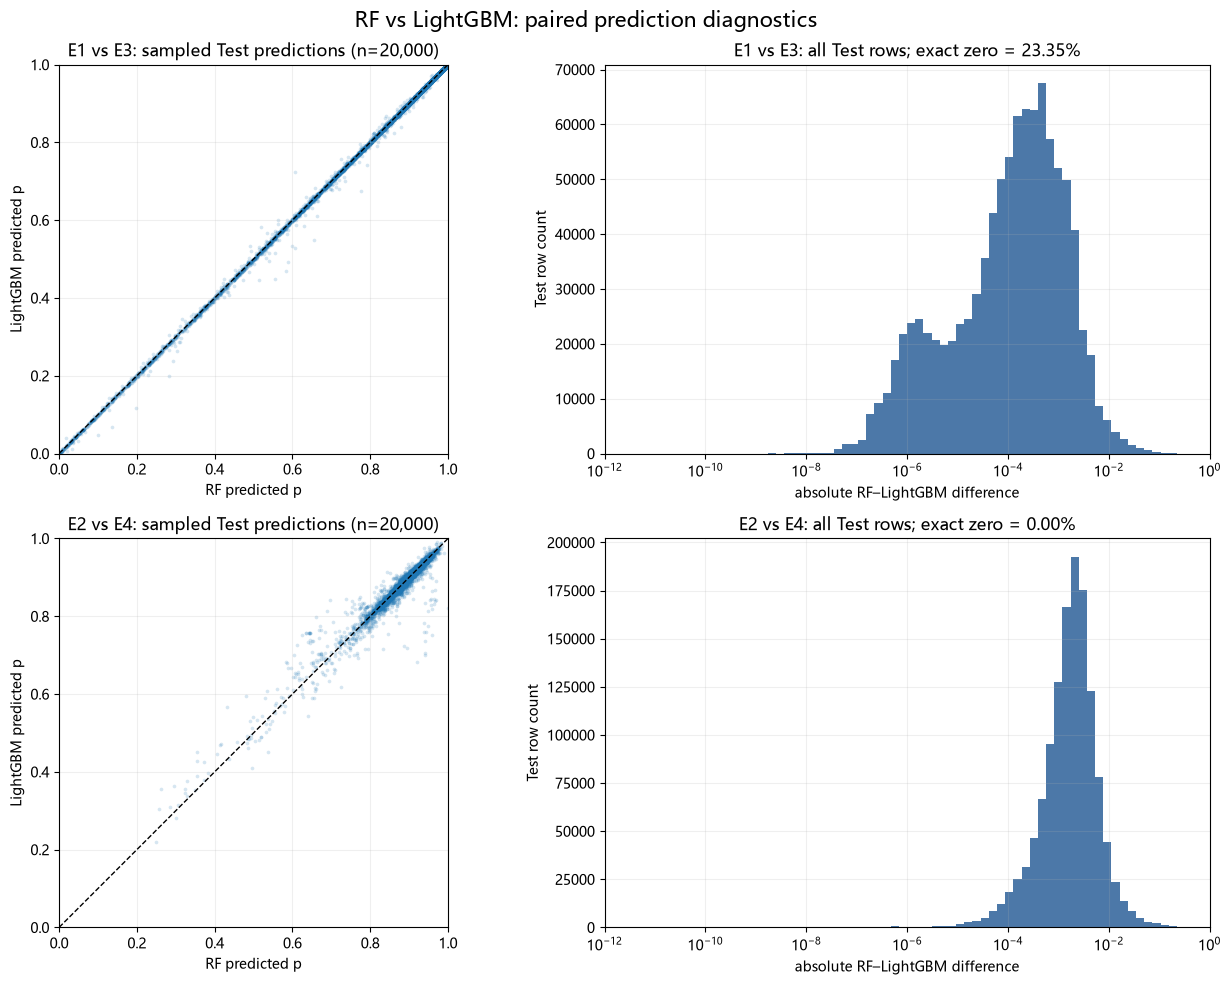

Saved: D:\fujing123\Projects\Data-Analytic\HLR\reports\s10_rf_lgbm_similarity.png


In [68]:
from pathlib import Path
import matplotlib.pyplot as plt

diag_scatter_n = min(20_000, diag_n_test)
diag_sample = np.random.default_rng(20261115).choice(
    diag_n_test, size=diag_scatter_n, replace=False
)
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for row, (pair, rf_name, lgb_name, *_rest) in enumerate(diag_pairs):
    rf_p = test_predictions[rf_name][0]
    lgb_p = test_predictions[lgb_name][0]
    ax_scatter, ax_hist = axes[row]
    ax_scatter.scatter(
        rf_p[diag_sample], lgb_p[diag_sample],
        s=7, alpha=0.18, linewidths=0, rasterized=True,
    )
    ax_scatter.plot([MIN_P, MAX_P], [MIN_P, MAX_P], 'k--', linewidth=1)
    ax_scatter.set(
        xlim=(0, 1), ylim=(0, 1),
        xlabel='RF predicted p', ylabel='LightGBM predicted p',
        title=f'{pair}: sampled Test predictions (n={diag_scatter_n:,})',
    )
    ax_scatter.set_aspect('equal', adjustable='box')
    ax_scatter.grid(alpha=0.2)

    abs_difference = np.abs(rf_p - lgb_p)
    positive = abs_difference[abs_difference > 0]
    ax_hist.hist(
        np.maximum(positive, 1e-12), bins=np.logspace(-12, 0, 75),
        color='#4C78A8', edgecolor='none',
    )
    ax_hist.set_xscale('log')
    ax_hist.set(
        xlim=(1e-12, 1), xlabel='absolute RF–LightGBM difference',
        ylabel='Test row count',
        title=f'{pair}: all Test rows; exact zero = {(abs_difference == 0).mean():.2%}',
    )
    ax_hist.grid(alpha=0.2)

fig.suptitle('RF vs LightGBM: paired prediction diagnostics', fontsize=15)
fig.tight_layout()
figure_path = Path('reports/s10_rf_lgbm_similarity.png')
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved: {figure_path.resolve()}')


## 10.2 结论

E1/E3 的最终回忆率预测几乎重合：Pearson 为 0.999839，平均绝对差异为 0.000678。不过，23.349% 的完全相同预测全部可以由两者共同落在相同裁剪边界解释；原始 `log2(h)` 输出没有逐行完全相等的记录。因此，两者的原始半衰期函数高度相关但并不相同，遗忘曲线变换和裁剪进一步放大了最终回忆率的相似性。

E2/E4 的 Pearson 为 0.976632，平均绝对差异为 0.003580。两者没有共同边界记录，也没有完全相同的 Test 预测，原始 `p` 和裁剪后 `p` 的差异统计几乎一致。因此，这一组的相似性来自模型实际输出，而不是裁剪。

综合来看，RF 与 LightGBM 在相同数据、特征和目标下学习到了高度相似的主要预测模式，但不能称为逐行等价。该诊断证明了相似程度及裁剪的作用；关于两种算法为什么收敛到相似模式，只能结合低维特征、大样本和共同目标作机制推断，不能视为已经完成因果证明。更完整的实验记录见 [最终报告](../../deliverables/ELEC3544_Group4_final_report.pdf)。
